# 1. DATA CLEANING 

## Objective

The purpose of this phase is to assess, clean, standardize, and validate all source datasets before integrating them into a unified analytical dataset.

The cleaning process focuses on:

- Missing value handling
- Duplicate detection
- Data type corrections
- Outlier identification
- Standardization of categorical values
- Validation of healthcare measurements
- Referential integrity assessment

The cleaned datasets generated in this phase will be used for statistical analysis, exploratory data analysis, machine learning, clustering, NLP, and Power BI reporting.

In [2]:
# ============================================
# Import Required Libraries
# ============================================

from pathlib import Path

conflicts = [
    path for path in Path.cwd().iterdir()
    if path.name.lower() in {"pandas.py", "pandas"}
]
if conflicts:
    raise ImportError(f"Rename or remove this local pandas conflict: {conflicts}")

import pandas as pd
import numpy as np
import re

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [3]:
# ============================================
# Load Datasets
# ============================================

member = pd.read_csv("Dim_Member.csv")
profile = pd.read_csv("Dim_Member_Profile.csv")
wellness = pd.read_csv("Fact_Wellness_Program.csv")
clinical = pd.read_csv("Fact_Clinical_Screenings.csv")
claims = pd.read_csv("Fact_Claims_Utilization.csv")
feedback = pd.read_csv("Fact_Member_Feedback.csv")

print("Files Loaded Successfully")

Files Loaded Successfully


## 1.1 Initial dataset Inspection

In [4]:
datasets = {
    "Member": member,
    "Profile": profile,
    "Wellness": wellness,
    "Clinical": clinical,
    "Claims": claims,
    "Feedback": feedback
}

for name, df in datasets.items():

    print("="*80)
    print(name.upper())
    print("="*80)

    print("\nShape:")
    print(df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nSample Data:")
    display(df.head())

MEMBER

Shape:
(10150, 7)

Columns:
['Member_ID', 'Age', 'Gender', 'Region', 'Region_ID', 'Home_Facility_ID', 'Race_Ethnicity']

Sample Data:


,Member_ID,Age,Gender,Region,Region_ID,Home_Facility_ID,Race_Ethnicity
0,KPM03226,35,Female,Northern California,R01,F004,White
1,KPM04620,45,Male,Southern California,R02,F021,Multiracial/Other
2,KPM01341,NaN,Male,Northern California,R01,F007,Asian
3,KPM00195,68,Female,Southern California,R02,F012,White
4,KPM05838,55,Male,Southern California,R02,F020,Hispanic/Latino


PROFILE

Shape:
(10100, 9)

Columns:
['Member_ID', 'Plan_Type', 'Member_Since_Date', 'Tenure_Years', 'Digital_Engagement', 'Preferred_Language', 'SDOH_Vulnerability_Index', 'Family_History_Diabetes', 'Family_History_Hypertension']

Sample Data:


,Member_ID,Plan_Type,Member_Since_Date,Tenure_Years,Digital_Engagement,Preferred_Language,SDOH_Vulnerability_Index,Family_History_Diabetes,Family_History_Hypertension
0,KPM09946,Medicare Advantage,2012-07-01,10.5,NaN,English,6,No,Yes
1,KPM04960,Individual & Family,2015-09-22,7.3,NaN,English,8,TRUE,Yes
2,KPM05898,medicaid,2019-05-28,3.6,High,English,3,No,Yes
3,KPM09361,Employer Group,2008-02-03,14.9,High,English,5,No,Yes
4,KPM07454,Medicaid,2007-03-31,15.8,Medium,Spanish,6,no,No


WELLNESS

Shape:
(15285, 14)

Columns:
['Wellness_Record_ID', 'Member_ID', 'Date_Key', 'Record_Date', 'Program_ID', 'Program_Status', 'Program_Enrolled_Flag', 'Sessions_Attended', 'Exercise_Frequency', 'Smoking_Status', 'Diet_Score', 'Screening_Participation', 'Preventive_Screenings_Completed', 'Health_Risk_Assessment_Completed']

Sample Data:


,Wellness_Record_ID,Member_ID,Date_Key,Record_Date,Program_ID,Program_Status,Program_Enrolled_Flag,Sessions_Attended,Exercise_Frequency,Smoking_Status,Diet_Score,Screening_Participation,Preventive_Screenings_Completed,Health_Risk_Assessment_Completed
0,WLN001135,KPM00745,20240318,2024-03-18,P05,completed,1,20,3,Non-Smoker,71.5,Yes,3,No
1,WLN004189,KPM02783,20240908,2024-09-08,P06,Active,1,8,2,Non-Smoker,55.9,No,0,Yes
2,WLN001809,KPM01194,20230509,2023-05-09,P00,Not Enrolled,0,0,1,Smoker,46.4,No,0,No
3,WLN001038,KPM00680,20241019,2024-10-19,P00,Not Enrolled,0,0,NaN,Non-Smoker,59.6,Yes,3,No
4,WLN002191,KPM01458,20240112,12-Jan-2024,P00,Not Enrolled,0,0,1,Non-Smoker,39.8,TRUE,4,Yes


CLINICAL

Shape:
(15285, 22)

Columns:
['Screening_ID', 'Member_ID', 'Date_Key', 'Screening_Date', 'Facility_ID', 'Screening_Type', 'BMI', 'Blood_Pressure', 'Systolic_BP', 'Diastolic_BP', 'Cholesterol', 'LDL_Cholesterol', 'HDL_Cholesterol', 'Triglycerides', 'Glucose', 'HbA1c', 'Existing_Diabetes_Flag', 'Existing_Hypertension_Flag', 'Model_Eligible_Flag', 'Develops_Diabetes_12M', 'Develops_Hypertension_12M', 'Develops_Chronic_Disease_12M']

Sample Data:


,Screening_ID,Member_ID,Date_Key,Screening_Date,Facility_ID,Screening_Type,BMI,Blood_Pressure,Systolic_BP,Diastolic_BP,Cholesterol,LDL_Cholesterol,HDL_Cholesterol,Triglycerides,Glucose,HbA1c,Existing_Diabetes_Flag,Existing_Hypertension_Flag,Model_Eligible_Flag,Develops_Diabetes_12M,Develops_Hypertension_12M,Develops_Chronic_Disease_12M
0,CLN013001,KPM08684,20250203,2025-02-03,F000,Employer Biometric Screening,22.4,116/66,116.0,66.0,225,137.0,64.0,119.0,72,4.4,0,0,1,0,0,0.0
1,CLN013212,KPM08815,20241021,2024-10-21,F008,Lab-Only Screening,22.1,102/69,102.0,69.0,149,84.0,58.0,36.0,103,5.7,0,0,1,0,0,0.0
2,CLN010158,KPM06772,20250221,2025-02-21,F013,Annual Physical,26.2,121/72,121.0,72.0,157,107.0,43.0,35.0,96,5.0,0,0,1,0,0,0.0
3,CLN012994,KPM08681,20240206,2024-02-06,F006,Employer Biometric Screening,39.6,139/84,139.0,84.0,203,137.0,53.0,65.0,89,4.9,0,0,1,0,0,0.0
4,CLN013594,KPM09065,20250126,2025-01-26,F017,Preventive Wellness Visit,37.7,121/78,121.0,78.0,185,112.0,49.0,119.0,95,NaN,0,0,1,0,0,0.0


CLAIMS

Shape:
(15285, 16)

Columns:
['Claim_Record_ID', 'Member_ID', 'Date_Key', 'Claim_Year', 'Period_End_Date', 'Visits', 'Preventive_Care_Visits', 'ER_Visits', 'Hospital_Admissions', 'Medications', 'Chronic_Condition_Count', 'Outpatient_Cost', 'ER_Cost', 'Inpatient_Cost', 'Pharmacy_Cost', 'Costs']

Sample Data:


,Claim_Record_ID,Member_ID,Date_Key,Claim_Year,Period_End_Date,Visits,Preventive_Care_Visits,ER_Visits,Hospital_Admissions,Medications,Chronic_Condition_Count,Outpatient_Cost,ER_Cost,Inpatient_Cost,Pharmacy_Cost,Costs
0,CLM012716,KPM08481,20251231,2025,2025-12-31,39,0,0,0,2,2,11956.63,0.00,0.0,124.01,12080.64
1,CLM008163,KPM05448,20251231,2025,2025-12-31,3,0,0,0,2,1,1220.20,0.00,0.0,1241.31,2461.52
2,CLM007116,KPM04737,20241231,2024,2024-12-31,4,0,1,0,0,0,1221.52,2485.48,0.0,0.00,"$3,706.99"
3,CLM009395,KPM06274,20231231,2023,2023-12-31,12,0,0,0,3,1,2570.62,0.00,0.0,1100.37,3670.99
4,CLM009357,KPM06246,20251231,2025,2025-12-31,6,2,0,0,1,1,1588.14,0.00,0.0,468.99,2057.12


FEEDBACK

Shape:
(15285, 11)

Columns:
['Feedback_ID', 'Member_ID', 'Date_Key', 'Feedback_Date', 'Facility_ID', 'Program_ID', 'Feedback_Channel', 'Survey_Comments', 'Program_Feedback', 'Satisfaction_Score', 'Likelihood_To_Recommend']

Sample Data:


,Feedback_ID,Member_ID,Date_Key,Feedback_Date,Facility_ID,Program_ID,Feedback_Channel,Survey_Comments,Program_Feedback,Satisfaction_Score,Likelihood_To_Recommend
0,FBK009071,KPM06069,20240311,2024-03-11,F039,P00,Annual Member Survey,"The visit was okay, nothing really stood out. ...",I am not enrolled in a wellness program yet bu...,3,6
1,FBK008042,KPM05387,20241106,2024-11-06,F033,P00,Post-Visit Survey,NaN,NaN,5,10
2,FBK010512,KPM07034,20231115,2023-11-15,F010,P00,Member Portal/App,The health assessment gave me a clear picture ...,NaN,4,7
3,FBK010475,KPM07006,20240113,2024-01-13,F040,P00,CALL CENTER,"Honestly, I was called back right away, hardly...",No program near me fits my needs.,3,7
4,FBK012866,KPM08563,20231116,2023-11-16,F001,P00,Post-Visit Survey,NaN,Have not joined because I cannot fit classes i...,4,6


## 1.2 Data Quality Summary

In [5]:
quality_summary = []

for name, df in datasets.items():

    quality_summary.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isna().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    })

quality_summary = pd.DataFrame(quality_summary)
quality_summary

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,Member,10150,7,269,110
1,Profile,10100,9,1708,100
2,Wellness,15285,14,1016,150
3,Clinical,15285,22,4307,150
4,Claims,15285,16,386,150
5,Feedback,15285,11,4824,150


## 1.3 Missing Value Assessment

In [6]:
for name, df in datasets.items():

    print("\n" + "="*80)
    print(f"{name.upper()} - Missing Values")
    print("="*80)

    missing_df = pd.DataFrame({
        "Column": df.columns,
        "Missing_Count": df.isnull().sum().values,
        "Missing_Percent": np.round((df.isnull().sum().values / len(df))*100, 2)
    })

    display(missing_df.sort_values("Missing_Count", ascending=False))


MEMBER - Missing Values


,Column,Missing_Count,Missing_Percent
6,Race_Ethnicity,173,1.70
1,Age,96,0.95
0,Member_ID,0,0.00
2,Gender,0,0.00
3,Region,0,0.00
4,Region_ID,0,0.00
5,Home_Facility_ID,0,0.00



PROFILE - Missing Values


,Column,Missing_Count,Missing_Percent
4,Digital_Engagement,1398,13.84
6,SDOH_Vulnerability_Index,122,1.21
5,Preferred_Language,100,0.99
3,Tenure_Years,88,0.87
0,Member_ID,0,0.00
1,Plan_Type,0,0.00
2,Member_Since_Date,0,0.00
7,Family_History_Diabetes,0,0.00
8,Family_History_Hypertension,0,0.00



WELLNESS - Missing Values


,Column,Missing_Count,Missing_Percent
10,Diet_Score,605,3.96
8,Exercise_Frequency,247,1.62
9,Smoking_Status,83,0.54
11,Screening_Participation,81,0.53
0,Wellness_Record_ID,0,0.00
1,Member_ID,0,0.00
2,Date_Key,0,0.00
3,Record_Date,0,0.00
4,Program_ID,0,0.00
5,Program_Status,0,0.00



CLINICAL - Missing Values


,Column,Missing_Count,Missing_Percent
15,HbA1c,1545,10.11
10,Cholesterol,422,2.76
11,LDL_Cholesterol,340,2.22
13,Triglycerides,340,2.22
12,HDL_Cholesterol,340,2.22
14,Glucose,312,2.04
7,Blood_Pressure,291,1.90
6,BMI,226,1.48
8,Systolic_BP,221,1.45
9,Diastolic_BP,221,1.45



CLAIMS - Missing Values


,Column,Missing_Count,Missing_Percent
10,Chronic_Condition_Count,135,0.88
9,Medications,92,0.60
5,Visits,81,0.53
7,ER_Visits,78,0.51
0,Claim_Record_ID,0,0.00
1,Member_ID,0,0.00
2,Date_Key,0,0.00
3,Claim_Year,0,0.00
4,Period_End_Date,0,0.00
6,Preventive_Care_Visits,0,0.00



FEEDBACK - Missing Values


,Column,Missing_Count,Missing_Percent
8,Program_Feedback,3802,24.87
7,Survey_Comments,738,4.83
10,Likelihood_To_Recommend,112,0.73
9,Satisfaction_Score,104,0.68
4,Facility_ID,68,0.44
0,Feedback_ID,0,0.00
1,Member_ID,0,0.00
2,Date_Key,0,0.00
3,Feedback_Date,0,0.00
5,Program_ID,0,0.00


## 1.4 Duplicate Record Detection

In [7]:
for name, df in datasets.items():

    print(f"\n{name}")
    dup_count = df.duplicated().sum()
    print("Duplicate Rows:", dup_count)


Member
Duplicate Rows: 110

Profile
Duplicate Rows: 100

Wellness
Duplicate Rows: 150

Clinical
Duplicate Rows: 150

Claims
Duplicate Rows: 150

Feedback
Duplicate Rows: 150


## 1.5 Numeric Variable Profiling

In [8]:
for name, df in datasets.items():

    print("\n" + "="*80)
    print(name.upper())
    print("="*80)

    numeric_cols = df.select_dtypes(include=np.number).columns

    if len(numeric_cols) > 0: 
        display(df[numeric_cols].describe())


MEMBER

PROFILE

WELLNESS


,Date_Key,Program_Enrolled_Flag,Sessions_Attended,Preventive_Screenings_Completed
count,1.528500e+04,15285.000000,15285.000000,15285.000000
mean,2.024058e+07,0.359895,4.882826,2.394570
std,8.156248e+03,0.479985,17.583020,1.944455
min,2.023010e+07,0.000000,-3.000000,0.000000
25%,2.023093e+07,0.000000,0.000000,0.000000
50%,2.024062e+07,0.000000,0.000000,3.000000
75%,2.025033e+07,1.000000,5.000000,4.000000
max,2.025123e+07,1.000000,500.000000,6.000000



CLINICAL


,Date_Key,Systolic_BP,Diastolic_BP,LDL_Cholesterol,HDL_Cholesterol,Triglycerides,Model_Eligible_Flag,Develops_Diabetes_12M,Develops_Hypertension_12M,Develops_Chronic_Disease_12M
count,1.528500e+04,15064.000000,15064.000000,14945.000000,14945.000000,14945.000000,15285.000000,15285.000000,15285.000000,15236.000000
mean,2.023976e+07,120.762679,74.797331,107.686919,54.761191,127.073603,0.927445,0.048152,0.057900,0.103702
std,7.898561e+03,28.909980,9.596757,34.806891,10.462743,62.604144,0.259413,0.214094,0.233562,0.304883
min,2.023010e+07,-1.000000,45.000000,30.000000,24.000000,35.000000,0.000000,0.000000,0.000000,0.000000
25%,2.023091e+07,110.000000,68.000000,83.000000,48.000000,83.000000,1.000000,0.000000,0.000000,0.000000
50%,2.024052e+07,121.000000,75.000000,107.000000,55.000000,114.000000,1.000000,0.000000,0.000000,0.000000
75%,2.025013e+07,131.000000,81.000000,131.000000,62.000000,157.000000,1.000000,0.000000,0.000000,0.000000
max,2.025100e+07,999.000000,155.000000,246.000000,96.000000,700.000000,1.000000,1.000000,1.000000,1.000000



CLAIMS


,Date_Key,Claim_Year,Preventive_Care_Visits,Hospital_Admissions,Outpatient_Cost,ER_Cost,Inpatient_Cost,Pharmacy_Cost
count,1.528500e+04,15285.000000,15285.000000,15285.000000,15285.000000,15285.000000,15285.000000,15285.000000
mean,2.024116e+07,2023.993196,0.982139,0.060124,1343.813337,513.950785,1833.264224,1714.173475
std,8.158536e+03,0.815854,1.141979,0.251890,1467.702887,1649.615123,10926.607873,3028.406699
min,2.023123e+07,2023.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.023123e+07,2023.000000,0.000000,0.000000,382.040000,0.000000,0.000000,158.910000
50%,2.024123e+07,2024.000000,1.000000,0.000000,912.190000,0.000000,0.000000,758.920000
75%,2.025123e+07,2025.000000,1.000000,0.000000,1790.110000,0.000000,0.000000,1950.160000
max,2.025123e+07,2025.000000,23.000000,4.000000,19944.990000,32125.460000,330000.000000,48219.350000



FEEDBACK


,Date_Key
count,1.528500e+04
mean,2.024060e+07
std,8.118969e+03
min,2.023010e+07
25%,2.023100e+07
50%,2.024063e+07
75%,2.025033e+07
max,2.025123e+07


## 1.6 Categorical Variable Profiling

In [9]:
for name, df in datasets.items():

    print("\n" + "="*80)
    print(name.upper())
    print("="*80)

    cat_cols = df.select_dtypes(include="object").columns
    for col in cat_cols[:10]:
        print(f"\nColumn : {col}")
        display(df[col].value_counts(dropna=False).head(15))


MEMBER

Column : Member_ID


Member_ID
KPM03955    3
KPM02066    2
KPM01520    2
KPM07858    2
KPM09864    2
KPM01996    2
KPM03538    2
KPM02594    2
KPM00345    2
KPM01291    2
KPM01957    2
KPM08343    2
KPM04547    2
KPM02289    2
KPM04227    2
Name: count, dtype: int64


Column : Age


Age
60    189
43    182
63    182
56    180
38    179
50    179
40    178
62    175
52    175
46    175
53    175
66    173
34    173
42    172
57    171
Name: count, dtype: int64


Column : Gender


Gender
Female              4572
Male                4089
female               166
male                 160
FEMALE               155
f                    147
Female               147
M                    141
F                    140
 Male                124
MALE                 119
m                    109
Non-Binary/Other      69
NB                     5
Other                  3
Name: count, dtype: int64


Column : Region


Region
Southern California    3560
Northern California    3244
Mid-Atlantic States     474
Northwest               471
Washington              415
Colorado                337
Georgia                 321
Hawaii                  211
SoCal                   111
SOUTHERN CALIFORNIA     106
Northern Cal             98
S. California            95
N. California            94
NorCal                   91
Southern Cal             89
Name: count, dtype: int64


Column : Region_ID


Region_ID
R02    3961
R01    3635
R06     530
R08     529
R09     460
R03     374
R04     360
R05     231
R07      70
Name: count, dtype: int64


Column : Home_Facility_ID


Home_Facility_ID
F017    402
F007    390
F003    388
F002    387
F015    379
F001    372
F005    365
F019    364
F018    363
F016    363
F012    358
F009    356
F013    355
F004    354
F014    353
Name: count, dtype: int64


Column : Race_Ethnicity


Race_Ethnicity
White                               3336
Hispanic/Latino                     2463
Asian                               1650
Black/African American               756
Multiracial/Other                    500
NaN                                  173
Native Hawaiian/Pacific Islander     165
White/Caucasian                      133
Caucasian                            120
white                                117
hispanic/latino                       94
asian                                 91
Hispanic                              90
Latino                                87
Asian American                        85
Name: count, dtype: int64


PROFILE

Column : Member_ID


Member_ID
KPM02508    2
KPM05233    2
KPM00993    2
KPM08503    2
KPM04532    2
KPM02946    2
KPM03106    2
KPM08827    2
KPM07346    2
KPM03386    2
KPM01907    2
KPM05520    2
KPM02552    2
KPM00554    2
KPM00516    2
Name: count, dtype: int64


Column : Plan_Type


Plan_Type
Employer Group             4459
Medicare Advantage         2001
Individual & Family         926
Medicaid                    829
Federal Employee (FEHB)     372
EMPLOYER GROUP              205
Commercial                  205
Group                       202
employer group              192
Medicare Adv                116
MA                          114
medicare advantage          102
medicaid                     65
individual & family          65
IFP                          52
Name: count, dtype: int64


Column : Member_Since_Date


Member_Since_Date
1989-01-01    24
2018-10-31     8
2016-09-20     8
2015-06-20     7
2019-05-05     7
2020-01-28     7
2015-01-10     7
2014-01-13     7
2019-09-26     7
2015-12-20     7
2015-10-26     7
2019-11-29     7
2019-04-25     6
2016-10-28     6
2015-03-18     6
Name: count, dtype: int64


Column : Tenure_Years


Tenure_Years
6.3    99
4.2    98
3.3    98
3.7    98
5.3    96
5.8    95
6.2    94
7.5    93
7.0    93
4.3    89
7.8    89
3.1    88
NaN    88
6.0    87
3.9    86
Name: count, dtype: int64


Column : Digital_Engagement


Digital_Engagement
Medium      3161
High        2508
Low         2077
NaN         1398
medium       129
MEDIUM       123
Med          122
LOW          107
low          102
high          95
Hi            84
HIGH          81
none          66
No usage      47
Name: count, dtype: int64


Column : Preferred_Language


Preferred_Language
English       5856
Spanish       1431
Chinese        603
Tagalog        368
english        278
ENGLISH        274
Eng            263
Vietnamese     245
Other          238
Korean         164
NaN            100
spanish         67
Span.           65
Espanol         45
?               37
Name: count, dtype: int64


Column : SDOH_Vulnerability_Index


SDOH_Vulnerability_Index
5          2000
6          1758
4          1669
7          1247
3          1059
8           738
2           584
1           343
9           297
10          146
NaN         122
?            28
Unknown      27
-            24
0            21
Name: count, dtype: int64


Column : Family_History_Diabetes


Family_History_Diabetes
No       7239
Yes      1846
FALSE     219
0         217
N         186
no        178
TRUE       64
yes        58
Y          47
1          46
Name: count, dtype: int64


Column : Family_History_Hypertension


Family_History_Hypertension
No       6003
Yes      3092
0         186
FALSE     163
no        159
N         139
1          93
Y          90
TRUE       89
yes        86
Name: count, dtype: int64


WELLNESS

Column : Wellness_Record_ID


Wellness_Record_ID
WLN009733    2
WLN005784    2
WLN006945    2
WLN007970    2
WLN008527    2
WLN009552    2
WLN014827    2
WLN008122    2
WLN013449    2
WLN006423    2
WLN002146    2
WLN006364    2
WLN002799    2
WLN012542    2
WLN012675    2
Name: count, dtype: int64


Column : Member_ID


Member_ID
KPM08835    5
KPM03961    5
KPM09947    4
KPM06253    4
KPM05708    4
KPM05648    4
KPM00052    4
KPM09367    4
KPM01533    4
KPM04787    4
KPM04892    4
KPM01859    4
KPM09210    4
KPM00592    4
KPM07148    4
Name: count, dtype: int64


Column : Record_Date


Record_Date
2025-10-29    24
2023-08-11    24
2025-11-14    24
2025-01-13    23
2024-06-09    23
2024-03-27    23
2024-05-12    22
2024-05-14    22
2023-03-06    22
2023-05-19    22
2024-11-02    22
2024-10-23    22
2025-02-17    21
2025-05-11    21
2025-04-26    21
Name: count, dtype: int64


Column : Program_ID


Program_ID
P00    9784
P05     965
P02     915
P06     736
P12     611
P03     371
P08     367
P11     349
P10     337
P01     302
P07     209
P09     174
P04     165
Name: count, dtype: int64


Column : Program_Status


Program_Status
Not Enrolled    8793
Dropped         2186
Completed       1903
Active           870
N/E              332
Not enrolled     330
not enrolled     329
Dropped Out       90
completed         84
Withdrawn         80
dropped           74
COMPLETE          72
Complete          62
In Progress       36
ACTIVE            26
Name: count, dtype: int64


Column : Exercise_Frequency


Exercise_Frequency
3          2970
2          2876
4          2322
1          2077
5          1634
0          1333
6           909
7           760
NaN         247
?            28
Unknown      23
-            20
-1           20
30           15
99           14
Name: count, dtype: int64


Column : Smoking_Status


Smoking_Status
Non-Smoker        11937
Smoker             1391
N                   289
NON-SMOKER          279
non-smoker          273
No                  264
Non Smoker          254
Nonsmoker           249
NaN                  83
Current Smoker       58
smoker               50
Y                    32
SMOKER               32
Unknown              26
Yes                  25
Name: count, dtype: int64


Column : Diet_Score


Diet_Score
NaN      605
56.4      58
63.8      54
61.0      54
64.5      54
59.7      52
100.0     52
55.8      50
56.8      50
61.9      50
60.4      50
65.3      49
69.5      49
68.9      48
58.1      48
Name: count, dtype: int64


Column : Screening_Participation


Screening_Participation
Yes      8955
No       4363
1         260
yes       239
YES       228
Y         226
TRUE      211
0         137
FALSE     136
no        131
NO        125
N         119
NaN        81
-          31
?          22
Name: count, dtype: int64


Column : Health_Risk_Assessment_Completed


Health_Risk_Assessment_Completed
Yes    7710
No     7575
Name: count, dtype: int64


CLINICAL

Column : Screening_ID


Screening_ID
CLN004629    2
CLN006516    2
CLN012895    2
CLN000437    2
CLN013379    2
CLN008398    2
CLN007423    2
CLN013215    2
CLN011440    2
CLN007436    2
CLN004181    2
CLN007152    2
CLN010711    2
CLN012703    2
CLN008154    2
Name: count, dtype: int64


Column : Member_ID


Member_ID
KPM00545    5
KPM01447    4
KPM08081    4
KPM06848    4
KPM07987    4
KPM05369    4
KPM00238    4
KPM01831    4
KPM02617    4
KPM00106    4
KPM09127    4
KPM01640    4
KPM06240    4
KPM09369    4
KPM04265    4
Name: count, dtype: int64


Column : Screening_Date


Screening_Date
2025-07-11    27
2024-09-03    26
2025-03-16    26
2023-08-11    26
2025-02-05    26
2023-02-15    25
2025-03-03    25
2025-08-29    24
2024-01-23    23
2024-12-19    23
2023-02-16    23
2023-03-05    22
2024-11-10    22
2024-08-29    22
2024-12-22    22
Name: count, dtype: int64


Column : Facility_ID


Facility_ID
F017    598
F002    594
F015    575
F007    572
F003    570
F018    570
F009    565
F012    564
F001    558
F005    547
F013    543
F019    542
F021    536
F016    535
F014    515
Name: count, dtype: int64


Column : Screening_Type


Screening_Type
Annual Physical                   3429
Preventive Wellness Visit         2416
Total Health Assessment           2195
Lab-Only Screening                1698
Employer Biometric Screening      1329
Medicare Annual Wellness Visit    1019
Chronic Care Follow-up             910
Annual Physical                    319
preventive wellness visit          295
Preventive Visit                   282
ANNUAL PHYSICAL                    262
total health assessment            261
THA                                256
annual physical                    234
Lab Only                           198
Name: count, dtype: int64


Column : BMI


BMI
NaN     226
27.3    126
27.1    126
27.5    123
24.7    122
26.2    121
26.5    121
27.0    120
28.0    118
26.9    118
29.7    116
26.4    116
29.6    114
26.3    112
25.3    112
Name: count, dtype: int64


Column : Blood_Pressure


Blood_Pressure
NaN       291
121/74     47
127/79     40
117/74     40
127/77     38
123/79     36
123/74     35
114/73     35
126/79     35
124/78     35
119/73     35
122/77     35
113/71     35
125/77     34
131/79     34
Name: count, dtype: int64


Column : Cholesterol


Cholesterol
NaN    422
182    218
178    200
189    199
187    193
172    192
186    192
184    190
177    189
170    188
194    187
193    183
197    182
179    178
195    176
Name: count, dtype: int64


Column : Glucose


Glucose
90    496
89    475
87    473
91    471
86    464
93    456
94    453
88    452
84    431
95    427
92    417
85    387
83    386
98    378
97    367
Name: count, dtype: int64


Column : HbA1c


HbA1c
NaN    1545
5.0    1051
5.1     995
4.9     960
5.2     953
5.3     929
4.8     905
5.4     830
4.7     742
5.5     684
5.6     600
4.6     598
5.7     486
4.5     430
5.8     395
Name: count, dtype: int64


CLAIMS

Column : Claim_Record_ID


Claim_Record_ID
CLM003246    2
CLM009158    2
CLM008742    2
CLM011014    2
CLM009299    2
CLM004692    2
CLM001976    2
CLM008270    2
CLM008699    2
CLM010658    2
CLM006567    2
CLM003818    2
CLM011078    2
CLM000977    2
CLM006182    2
Name: count, dtype: int64


Column : Member_ID


Member_ID
KPM06604    4
KPM09720    4
KPM09014    4
KPM04010    4
KPM03141    4
KPM01678    4
KPM08308    4
KPM05843    4
KPM05502    4
KPM04039    4
KPM08519    4
KPM01650    4
KPM01868    4
KPM04784    4
KPM00812    4
Name: count, dtype: int64


Column : Period_End_Date


Period_End_Date
2023-12-31     4615
2024-12-31     4576
2025-12-31     4553
2024/12/31      141
31.12.2024      140
31-Dec-2023     133
31-Dec-2025     130
31-Dec-2024     128
12/31/2024      128
2023/12/31      128
2025/12/31      126
12/31/2023      124
31.12.2023      122
31.12.2025      120
12/31/2025      108
Name: count, dtype: int64


Column : Visits


Visits
2     1923
3     1783
1     1736
4     1617
5     1311
6     1166
0     1116
7      914
8      716
9      594
10     462
11     339
12     319
13     218
14     188
Name: count, dtype: int64


Column : ER_Visits


ER_Visits
0          13026
1           1831
2            258
NaN           78
3             39
Unknown       24
-             11
?              8
4              6
5              2
6              2
Name: count, dtype: int64


Column : Medications


Medications
0      3496
1      3400
2      2670
3      1902
4      1414
5       949
6       568
7       303
8       191
9       111
NaN      92
10       52
?        26
-3       24
-        20
Name: count, dtype: int64


Column : Chronic_Condition_Count


Chronic_Condition_Count
0          7186
1          5573
2          2024
3           261
NaN         135
-            33
Unknown      31
?            31
4            11
Name: count, dtype: int64


Column : Costs


Costs
0.0        286
0           75
$0.00        6
591.21       3
721.7        3
2827.63      3
908.32       3
576.45       3
14486.4      3
2682.05      3
507.99       2
719.51       2
7920.07      2
1000.0       2
1977.33      2
Name: count, dtype: int64


FEEDBACK

Column : Feedback_ID


Feedback_ID
FBK002689    2
FBK013276    2
FBK006607    2
FBK011807    2
FBK014434    2
FBK014505    2
FBK013706    2
FBK011842    2
FBK002120    2
FBK003120    2
FBK001919    2
FBK013390    2
FBK003222    2
FBK011204    2
FBK013273    2
Name: count, dtype: int64


Column : Member_ID


Member_ID
KPM00647    5
KPM00179    4
KPM07587    4
KPM07278    4
KPM09703    4
KPM02626    4
KPM07448    4
KPM06883    4
KPM09635    4
KPM04455    4
KPM05342    4
KPM02205    4
KPM04800    4
KPM01424    4
KPM06835    4
Name: count, dtype: int64


Column : Feedback_Date


Feedback_Date
2025-09-22    26
2025-12-25    24
2024-05-19    23
2023-10-19    23
2024-06-04    23
2025-02-13    23
2023-10-10    23
2024-05-13    23
2025-06-29    23
2024-11-23    22
2025-05-02    22
2023-01-16    22
2025-06-30    21
2023-12-27    21
2023-07-22    21
Name: count, dtype: int64


Column : Facility_ID


Facility_ID
F003    591
F017    577
F019    577
F007    564
F001    561
F002    559
F015    557
F016    556
F018    549
F013    544
F009    543
F021    541
F005    540
F014    536
F004    531
Name: count, dtype: int64


Column : Program_ID


Program_ID
P00    10009
P05      911
P02      908
P06      715
P12      606
P03      356
P08      341
P11      326
P10      318
P01      267
P07      206
P04      178
P09      144
Name: count, dtype: int64


Column : Feedback_Channel


Feedback_Channel
Post-Visit Survey          5915
Member Portal/App          3008
Annual Member Survey       1628
Call Center                1436
Email                      1123
Wellness Program Survey     640
POST-VISIT SURVEY           176
Post-visit survey           166
PVS                         160
post visit survey           155
AMS                         112
annual survey                96
Mobile App                   90
member portal / app          80
App                          79
Name: count, dtype: int64


Column : Survey_Comments


Survey_Comments
NaN                                                                              738
.                                                                                 35
test                                                                              33
-                                                                                 31
no comment                                                                        26
E-visits and secure messaging save me so much time.                               26
Muy buen servicio, gracias.                                                       22
The fitness benefit makes it easy to stay active.                                 21
The health assessment questionnaire was long but informative.                     21
Tuve problemas para conseguir cita.                                               20
服务很好，谢谢。                                                                          19
The pharmacist took time to explain my medication


Column : Program_Feedback


Program_Feedback
NaN                                                                                       3802
I am aware of the wellness programs but have not had time to look into them.               575
I have not joined a wellness program and exercise on my own.                               564
I would consider a program if it were covered under my plan.                               545
Not currently enrolled in any program.                                                     541
Have not joined because I cannot fit classes into my schedule.                             520
Cost worries me, I am not sure whether the programs are covered.                           503
No program near me fits my needs.                                                          497
My doctor mentioned a program but I never received the sign-up information.                496
I would join if programs were offered at night or on weekends.                             488
I did not know KP offered wellnes


Column : Satisfaction_Score


Satisfaction_Score
4          4957
5          4211
3          3319
2          1654
1           899
NaN         104
Unknown      19
?            19
-            17
-1           15
99           13
6            13
10           12
0            10
three         9
Name: count, dtype: int64


Column : Likelihood_To_Recommend


Likelihood_To_Recommend
10         2686
8          2556
9          2411
7          2128
6          1698
5          1248
4           901
3           650
2           443
1           228
NaN         112
0           111
-            24
Unknown      24
?            22
Name: count, dtype: int64

## 1.7 Creating Working Copies For Cleaning
Original datasets will be preserved.

In [10]:
member_clean = member.copy()
profile_clean = profile.copy()
wellness_clean = wellness.copy()
clinical_clean = clinical.copy()
claims_clean = claims.copy()
feedback_clean = feedback.copy()

In [11]:
# ============================================
# Standardize Member IDs
# ============================================

def clean_member_id(series):
    return (series.astype(str).str.upper().str.strip().str.replace("-", "", regex=False).str.replace(" ", "", regex=False))


for df in [
    member_clean,
    profile_clean,
    wellness_clean,
    clinical_clean,
    claims_clean,
    feedback_clean
]:

    if "Member_ID" in df.columns:
        df["Member_ID"] = clean_member_id(df["Member_ID"])

In [12]:
member_clean = member_clean.drop_duplicates()
profile_clean = profile_clean.drop_duplicates()
wellness_clean = wellness_clean.drop_duplicates()
clinical_clean = clinical_clean.drop_duplicates()
claims_clean = claims_clean.drop_duplicates()
feedback_clean = feedback_clean.drop_duplicates()

## 1.8 Create Data Cleaning Audit Report

In [13]:
cleaning_audit = []

tables = {
    "Member": member_clean,
    "Profile": profile_clean,
    "Wellness": wellness_clean,
    "Clinical": clinical_clean,
    "Claims": claims_clean,
    "Feedback": feedback_clean
}

for name, df in tables.items():
    cleaning_audit.append({
        "Dataset": name,
        "Rows_After_Cleaning":len(df),
        "Missing_Values":df.isna().sum().sum(),
        "Duplicate_Rows":df.duplicated().sum()
    })

cleaning_audit = pd.DataFrame(cleaning_audit)
cleaning_audit

,Dataset,Rows_After_Cleaning,Missing_Values,Duplicate_Rows
0,Member,10040,267,0
1,Profile,10000,1693,0
2,Wellness,15135,1008,0
3,Clinical,15135,4254,0
4,Claims,15135,378,0
5,Feedback,15135,4769,0


In [14]:
#==========================
# Export Cleaned Datasets
#=========================
member_clean.to_csv("clean_member.csv",index=False)
profile_clean.to_csv("clean_profile.csv",index=False)
wellness_clean.to_csv("clean_wellness.csv",index=False)
clinical_clean.to_csv("clean_clinical.csv",index=False)
claims_clean.to_csv("clean_claims.csv",index=False)
feedback_clean.to_csv("clean_feedback.csv",index=False)
print("Clean datasets exported successfully.")

Clean datasets exported successfully.


# 2. DATA INTEGRATION & MASTER DATA CREATION 

### Objective

The cleaned source datasets are integrated to create a unified member-level analytical dataset.

This master dataset combines:

- Demographic information
- Member profile information
- Wellness participation
- Clinical indicators
- Claims utilization

The resulting dataset will serve as the primary source for:

- Statistical Analysis
- Exploratory Data Analysis
- Feature Engineering
- Machine Learning
- Clustering
- Power BI Reporting

Member feedback data will be maintained separately for NLP analysis.

In [15]:
print("Member Dataset :", member_clean["Member_ID"].nunique())
print("Profile Dataset :", profile_clean["Member_ID"].nunique())
print("Wellness Dataset :", wellness_clean["Member_ID"].nunique())
print("Clinical Dataset :", clinical_clean["Member_ID"].nunique())
print("Claims Dataset :", claims_clean["Member_ID"].nunique())
print("Feedback Dataset :", feedback_clean["Member_ID"].nunique())

Member Dataset : 10000
Profile Dataset : 10000
Wellness Dataset : 10054
Clinical Dataset : 10059
Claims Dataset : 10054
Feedback Dataset : 10057


In [16]:
#==================================================================
# Checking referential integrity between Member and other datasets
#==================================================================

member_ids = set(member_clean["Member_ID"])

tables = {
    "Profile": profile_clean,
    "Wellness": wellness_clean,
    "Clinical": clinical_clean,
    "Claims": claims_clean,
    "Feedback": feedback_clean
}

for name, df in tables.items():
    orphan_records = df[~df["Member_ID"].isin(member_ids)]
    print(f"{name} Orphan Records: {len(orphan_records)}")

Profile Orphan Records: 0
Wellness Orphan Records: 60
Clinical Orphan Records: 60
Claims Orphan Records: 60
Feedback Orphan Records: 60


In [17]:
#===============================================================
# Create master dataset by merging all datasets on Member_ID
#===============================================================

master_df = (
    member_clean.merge(profile_clean, on="Member_ID", how="left")
    .merge(wellness_clean, on="Member_ID", how="left")
    .merge(clinical_clean, on="Member_ID", how="left")
    .merge(claims_clean, on="Member_ID", how="left")
)

In [18]:
print(master_df.shape)
master_df.info()

(34553, 64)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34553 entries, 0 to 34552
Data columns (total 64 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Member_ID                         34553 non-null  object 
 1   Age                               34236 non-null  object 
 2   Gender                            34553 non-null  object 
 3   Region                            34553 non-null  object 
 4   Region_ID                         34553 non-null  object 
 5   Home_Facility_ID                  34553 non-null  object 
 6   Race_Ethnicity                    33947 non-null  object 
 7   Plan_Type                         34553 non-null  object 
 8   Member_Since_Date                 34553 non-null  object 
 9   Tenure_Years                      34241 non-null  object 
 10  Digital_Engagement                30331 non-null  object 
 11  Preferred_Language                34238 non-null  objec

In [19]:
missing_summary = pd.DataFrame({

    "Column": master_df.columns,
    "Missing_Count": master_df.isna().sum().values,
    "Missing_Percent": round(master_df.isna().mean()*100,2).values
})

missing_summary.sort_values("Missing_Percent", ascending=False)

,Column,Missing_Count,Missing_Percent
10,Digital_Engagement,4222,12.22
42,HbA1c,3569,10.33
24,Diet_Score,1397,4.04
37,Cholesterol,920,2.66
40,Triglycerides,735,2.13
39,HDL_Cholesterol,735,2.13
38,LDL_Cholesterol,735,2.13
41,Glucose,733,2.12
34,Blood_Pressure,664,1.92
6,Race_Ethnicity,606,1.75


In [20]:
master_df.to_csv("Gold_Member_Health.csv", index=False)
print("Gold dataset exported successfully.")

Gold dataset exported successfully.


### Data Integration Summary

The cleaned datasets were successfully integrated using Member_ID as the common business key.

The resulting Gold_Member_Health dataset provides a consolidated member-level analytical view combining:

- Demographics
- Member Profile Information
- Wellness Program Participation
- Clinical Indicators
- Claims Utilization Metrics

This dataset will serve as the primary input for all subsequent analytical and predictive tasks.

# 3. SQL ANALYSIS

In [21]:
import sqlite3

conn = sqlite3.connect(':memory:')

In [22]:
master_df.to_sql("Gold_Member_Health", conn, index=False, if_exists="replace")

print("Dataset loaded into SQL successfully.")

Dataset loaded into SQL successfully.


In [23]:
#===========================================
# member distribution by region
#===========================================
#Which regions have the largest member populations?

query = """
SELECT
    Region,
    COUNT(*) AS Total_Members
FROM Gold_Member_Health
GROUP BY Region
ORDER BY Total_Members DESC;
"""

region_population =pd.read_sql(query, conn)
region_population 

,Region,Total_Members
0,Southern California,12367
1,Northern California,10755
2,Mid-Atlantic States,1632
3,Northwest,1565
4,Washington,1367
5,Georgia,1175
6,Colorado,1101
7,Hawaii,651
8,Northern Cal,446
9,SoCal,369


### Business Insight
Region X contains the largest enrolled member population.

This indicates a higher concentration of healthcare demand
and may require additional preventive care initiatives.

In [24]:
#==========================================
# Screening participation rate by region
#==========================================
#Which regions are most engaged in preventive care?

query = """
SELECT
    Region, COUNT(*) AS Total_Records,
    AVG(Preventive_Screenings_Completed)*100
        AS Avg_Screenings
FROM Gold_Member_Health
GROUP BY Region
ORDER BY Avg_Screenings DESC;
"""

screening_region =pd.read_sql(query, conn)
screening_region 

,Region,Total_Records,Avg_Screenings
0,WASHINGTON,1,500.000000
1,HI,23,295.652174
2,North West,64,293.750000
3,Northern Cal,446,288.789238
4,GA,38,286.842105
5,Mid-Atlantic,49,285.714286
6,NORTHERN CALIFORNIA,59,281.355932
7,northern california,308,273.701299
8,Mid Atlantic,63,268.253968
9,N. California,287,264.808362


### Business Insight
Regions with higher screening participation demonstrate stronger
preventive healthcare engagement.

Regions with lower participation should be targeted through
outreach programs and awareness campaigns.

In [25]:
#===================================================
# High-risk members based on BMI and glucose levels
#===================================================
#Which members may require preventive intervention?

query = """
SELECT
    Member_ID,
    Age,
    BMI,
    Glucose, HbA1c, Systolic_BP,
    Smoking_Status
FROM Gold_Member_Health
WHERE BMI > 30 OR HbA1c > 6.5 OR Systolic_BP > 140
  OR Glucose >= 126;
"""

high_risk_members  = pd.read_sql(query, conn)

high_risk_members.head() 

,Member_ID,Age,BMI,Glucose,HbA1c,Systolic_BP,Smoking_Status
0,KPM03226,35,24.4,81,4.6,101.0,Non-Smoker
1,KPM03226,35,24.4,81,4.6,101.0,Non-Smoker
2,KPM04620,45,16.7,87,4.6,131.0,Non Smoker
3,KPM04620,45,16.7,87,4.6,131.0,Non Smoker
4,KPM04620,45,16.7,87,4.6,131.0,Non-Smoker


### Business Insight
Members identified through elevated BMI, glucose,
HbA1c, or blood pressure levels may benefit from
early intervention programs.

These members represent the primary target group
for disease prevention initiatives.

In [26]:
#===================================
# Cost Analysis by Region
#===================================
# Which regions generate the highest healthcare costs?

query = """
SELECT
    Region,
    ROUND(SUM(Costs),2) AS Total_Healthcare_Cost,
    ROUND(AVG(Costs),2) AS Average_Cost
FROM Gold_Member_Health
GROUP BY Region
ORDER BY Total_Healthcare_Cost DESC;
"""

cost_region = pd.read_sql(query, conn)

cost_region

,Region,Total_Healthcare_Cost,Average_Cost
0,Southern California,69987624.60,5659.22
1,Northern California,56865063.99,5287.31
2,Georgia,7884143.80,6709.91
3,Mid-Atlantic States,7726273.55,4734.24
4,Northwest,7537016.89,4815.99
5,SoCal,6587818.26,17853.17
6,Washington,5915592.30,4327.43
7,Colorado,5354735.05,4863.52
8,Hawaii,3092300.59,4750.08
9,Northern Cal,3028224.83,6789.74


### Business Insight
Regions generating higher healthcare costs should be
further investigated to determine whether increased
disease burden or healthcare utilization is driving costs.

In [27]:
#===========================
# Cost by Age group
#===========================
# How does healthcare spending vary across age groups?

query = """
SELECT
CASE
    WHEN Age BETWEEN 18 AND 30 THEN '18-30'
    WHEN Age BETWEEN 31 AND 45 THEN '31-45'
    WHEN Age BETWEEN 46 AND 60 THEN '46-60'
    ELSE '60+'
END AS Age_Group,

ROUND(AVG(Costs),2) AS Average_Cost,
ROUND(SUM(Costs),2) AS Total_Cost

FROM Gold_Member_Health

GROUP BY Age_Group

ORDER BY Average_Cost DESC;
"""

cost_age = pd.read_sql(query, conn)
cost_age

,Age_Group,Average_Cost,Total_Cost
0,60+,7945.54,1.057313e+08
1,46-60,4542.85,3.920937e+07
2,31-45,3912.64,3.094509e+07
3,18-30,3020.00,1.421210e+07


### Business Insight
Healthcare costs generally increase with age due to
greater prevalence of chronic conditions and healthcare utilization.

In [28]:
#===============================
# Wellness program Effectiveness 
#===============================
# Does participation reduce healthcare utilization / improves outcomes?

query = """
SELECT

Program_Enrolled_Flag,

ROUND(AVG(Costs),2) AS Avg_Cost,

ROUND(AVG(Visits),2) AS Avg_Visits,

ROUND(AVG(BMI),2) AS Avg_BMI

FROM Gold_Member_Health

GROUP BY Program_Enrolled_Flag;
"""

wellness_impact = pd.read_sql(query, conn)

wellness_impact

,Program_Enrolled_Flag,Avg_Cost,Avg_Visits,Avg_BMI
0,0,5433.61,6.08,29.69
1,1,5620.66,7.31,30.15


### Business Insight
Members enrolled in wellness programs may demonstrate
different healthcare utilization patterns compared
with non-participants.

This helps evaluate program effectiveness.

In [29]:
#===============================
# Top high cost members
#===============================
# Which members generate the highest healthcare costs?

query = """
SELECT *
FROM (
    SELECT Member_ID, Region, Costs,
    RANK() OVER( ORDER BY Costs DESC) AS Cost_Rank

    FROM Gold_Member_Health
)

WHERE Cost_Rank <= 20;
"""

top_cost_members = pd.read_sql(query, conn)
top_cost_members

,Member_ID,Region,Costs,Cost_Rank
0,KPM04334,Northern California,99959.78,1
1,KPM04334,Northern California,99959.78,1
2,KPM07021,Northern California,999.8,3
3,KPM01451,Southern California,999.62,4
4,KPM06071,Southern California,999.32,5
5,KPM06071,Southern California,999.32,5
6,KPM05730,Northern California,999.04,7
7,KPM02515,Northern California,998.83,8
8,KPM02515,Northern California,998.83,8
9,KPM02515,Northern California,998.83,8


### Business Insight
A relatively small number of members often account
for a large proportion of total healthcare expenditure.

These members should be considered for care-management programs.

In [30]:
#===============================
# Risk Categorization
#===============================
# How can members be grouped by risk?

query = """
SELECT Member_ID, BMI, Glucose,
CASE

WHEN BMI > 35 OR Glucose > 140
THEN 'High Risk'

WHEN BMI > 28 OR Glucose > 110
THEN 'Moderate Risk'

ELSE 'Low Risk'

END AS Risk_Category

FROM Gold_Member_Health;
"""

pd.read_sql(query, conn)

,Member_ID,BMI,Glucose,Risk_Category
0,KPM03226,24.4,81,High Risk
1,KPM03226,24.4,81,High Risk
2,KPM04620,16.7,87,High Risk
3,KPM04620,16.7,87,High Risk
4,KPM04620,17.3,104,Low Risk
...,...,...,...,...
34548,KPM05995,30.2,None,Moderate Risk
34549,KPM05995,31.1,73,High Risk
34550,KPM05995,31.1,73,High Risk
34551,KPM05995,30.9,67,High Risk


In [31]:
#Which members have higher-than-average healthcare cost?

query = """
SELECT Member_ID, Costs
FROM Gold_Member_Health

WHERE Costs >
(
    SELECT AVG(Costs)
    FROM Gold_Member_Health
);
"""

above_avg_cost = pd.read_sql(query, conn)
above_avg_cost 

,Member_ID,Costs
0,KPM04620,813.27
1,KPM04620,7082.52
2,KPM04620,813.27
3,KPM04620,7082.52
4,KPM04620,813.27
...,...,...
7670,KPM03611,5839.29
7671,KPM01448,948.24
7672,KPM07819,6138.73
7673,KPM07819,9142.8


### Business insight 
Members with above-average healthcare costs may represent
higher-risk populations and should be investigated for
cost-reduction opportunities through preventive care programs.

In [32]:
#=============================================
# Chronic Disease rate by region
#=============================================
# Which regions have the greatest future disease burden?

query = """
SELECT Region, COUNT(*) AS Total_Members,
SUM(Develops_Chronic_Disease_12M) AS Chronic_Cases,

ROUND( 100.0 * SUM(Develops_Chronic_Disease_12M) / COUNT(*),2) AS Chronic_Disease_Rate

FROM Gold_Member_Health
GROUP BY Region
ORDER BY Chronic_Disease_Rate DESC;
"""

chronic_region = pd.read_sql(query, conn)
chronic_region

,Region,Total_Members,Chronic_Cases,Chronic_Disease_Rate
0,nevada,5,4.0,80.00
1,Mid Atlantic,63,13.0,20.63
2,NORTHERN CAL,5,1.0,20.00
3,NORTHERN CALIFORNIA,59,10.0,16.95
4,NorCal,334,54.0,16.17
5,Southern Cal,334,53.0,15.87
6,GA,38,6.0,15.79
7,Nevada,221,32.0,14.48
8,Georgia,1175,144.0,12.26
9,northern california,308,36.0,11.69


# 3. STATISTICAL ANALYSIS
### Objective

Statistical analysis was performed to understand the characteristics of the member population, identify key healthcare trends, and validate business assumptions related to disease risk, healthcare utilization, and medical costs.

The results of this analysis will support exploratory data analysis, feature engineering, predictive modeling, and business recommendations.

In [33]:
#===============================================
# Descriptive Statistics for Key health metrics
#===============================================


stats_columns = [
    "BMI",
    "Glucose",
    "Cholesterol",
    "Costs",
    "Visits"
]

master_df[stats_columns].describe().T

,count,unique,top,freq
BMI,34033,376,26.5,319
Glucose,33820,175,90,1126
Cholesterol,33633,228,182,499
Costs,34553,14512,0.0,624
Visits,34377,49,2,4426


In [34]:
numeric_data = master_df[stats_columns].apply(pd.to_numeric, errors="coerce")

summary_stats = pd.DataFrame({
    "Mean": numeric_data.mean(),
    "Median": numeric_data.median(),
    "Std_Dev": numeric_data.std(),
    "Minimum": numeric_data.min(),
    "Maximum": numeric_data.max()

})

summary_stats

,Mean,Median,Std_Dev,Minimum,Maximum
BMI,29.964919,28.20,34.318573,-1.00,999.0
Glucose,102.002544,93.00,277.888419,-999.00,9999.0
Cholesterol,189.702112,186.00,252.735972,-999.00,9999.0
Costs,5675.580805,2492.27,28793.444753,-108468.27,2940217.0
Visits,6.555828,4.00,31.574875,-2.00,999.0


#### Interpretation

The descriptive statistics provide an overview of the population's clinical indicators and healthcare utilization.

Variables exhibiting large standard deviations may indicate substantial variation across members and could require further investigation during exploratory analysis.

## 3.1 Correlation Analysis
Understanding relationships between different features helps explain disease progression and healthcare spending patterns.

In [35]:
correlation_cols = [
    "BMI",
    "Glucose",
    "HbA1c",
    "Exercise_Frequency",
    "Costs",
    "Visits"
]

# Convert all correlation columns to numeric; bad values like "Unknown" become NaN
numeric_df = master_df[correlation_cols].apply(pd.to_numeric, errors="coerce")

# Compute correlation on numeric data only
corr_matrix = numeric_df.corr()

corr_matrix

,BMI,Glucose,HbA1c,Exercise_Frequency,Costs,Visits
BMI,1.000000,0.003212,0.005891,-0.013843,0.012800,0.003416
Glucose,0.003212,1.000000,0.009883,-0.003816,0.005227,0.004007
HbA1c,0.005891,0.009883,1.000000,-0.019083,0.015788,0.004079
Exercise_Frequency,-0.013843,-0.003816,-0.019083,1.000000,-0.012666,-0.003808
Costs,0.012800,0.005227,0.015788,-0.012666,1.000000,0.010938
Visits,0.003416,0.004007,0.004079,-0.003808,0.010938,1.000000


## 3.2 Correlation Heatmap

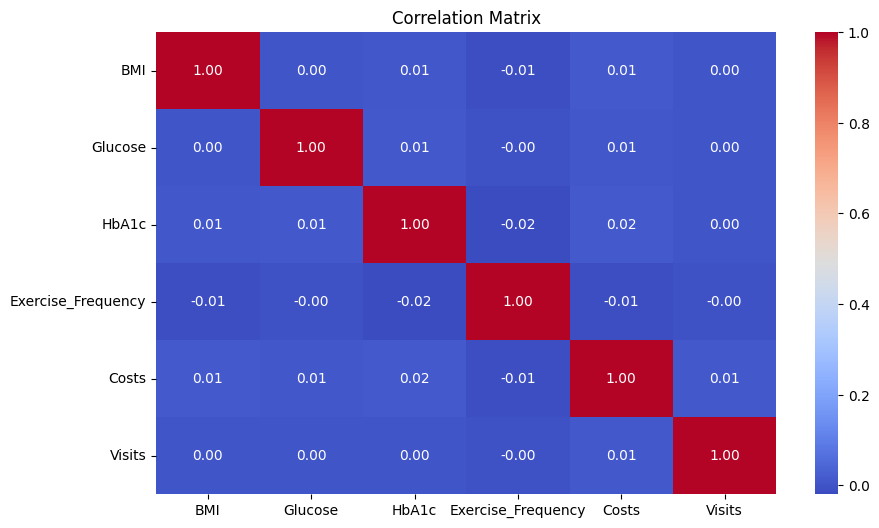

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Matrix")
plt.show()

## 3.3 Hypothesis testing

### Objective

Hypothesis testing is performed to statistically validate key business assumptions related to disease risk, preventive care effectiveness, wellness program impact, healthcare utilization, and healthcare costs.

The results of these tests will help determine whether observed patterns within the member population are statistically significant and can support future healthcare interventions and strategic decision-making.

Significance Level (α): 0.05

Decision Rule:

- If p-value < 0.05 → Reject Null Hypothesis
- If p-value ≥ 0.05 → Fail to Reject Null Hypothesis

In [37]:
from scipy.stats import ttest_ind
from scipy.stats import pearsonr

In [38]:
numeric_columns = [
   "Age",
    "BMI",
    "Glucose",
    "HbA1c",
    "Cholesterol",
    "LDL_Cholesterol",
    "HDL_Cholesterol",
    "Triglycerides",

    "Systolic_BP",
    "Diastolic_BP",

    "Exercise_Frequency",
    "Diet_Score",

    "Visits",
    "ER_Visits",
    "Hospital_Admissions",
    "Medications",

    "Costs",

    "Preventive_Screenings_Completed",
    "Health_Risk_Assessment_Completed",

    "Chronic_Condition_Count"

]

for col in numeric_columns:

    if col in master_df.columns:

        master_df[col] = pd.to_numeric(
            master_df[col],
            errors="coerce"
        )

## HYPOTHESIS 1

### Business Question

Does higher BMI increase the likelihood of developing chronic disease?

### Null Hypothesis (H0)

There is no significant difference in BMI between members who develop chronic disease and members who do not.

### Alternative Hypothesis (H1)

Members who develop chronic disease have significantly higher BMI values than members who do not.

In [39]:
master_df["BMI"] = pd.to_numeric(
    master_df["BMI"],
    errors="coerce"
)

disease_yes = master_df[master_df["Develops_Chronic_Disease_12M"] == 1]["BMI"]

disease_no = master_df[master_df["Develops_Chronic_Disease_12M"] == 0]["BMI"]

t_stat, p1 = ttest_ind(
    disease_yes,
    disease_no,
    nan_policy="omit"
)

print("Hypothesis 1")
print("T Statistic :", round(t_stat,4))
print("P Value :", round(p1,4))

if p1 < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Hypothesis 1
T Statistic : 3.6775
P Value : 0.0002
Reject H0


### HYPOTHESIS 2

#### Business Question

Does participation in preventive health screenings reduce healthcare costs?

#### Null Hypothesis (H0)

There is no significant difference in healthcare costs between members who participate in screenings and those who do not.

#### Alternative Hypothesis (H1)

Members who participate in preventive screenings incur significantly lower healthcare costs.

In [40]:
screening_yes = master_df[master_df["Screening_Participation"].astype(str).str.upper().isin(["YES","Y","TRUE","1"])]["Costs"]

screening_no = master_df[
    ~master_df["Screening_Participation"].astype(str)
    .str.upper()
    .isin(["YES","Y","TRUE","1"])
]["Costs"]

t_stat, p2 = ttest_ind(
    screening_yes,
    screening_no,
    nan_policy="omit"
)

print("Hypothesis 2")
print("T Statistic :", round(t_stat,4))
print("P Value :", round(p2,4))

if p2 < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Hypothesis 2
T Statistic : 1.5871
P Value : 0.1125
Fail to Reject H0


### HYPOTHESIS 3

#### Business Question

Do wellness program participants demonstrate lower healthcare utilization?

#### Null Hypothesis (H0)

There is no significant difference in healthcare utilization between wellness participants and non-participants.

#### Alternative Hypothesis (H1)

Members enrolled in wellness programs have significantly lower healthcare utilization.

In [41]:
wellness_yes = master_df[master_df["Program_Enrolled_Flag"] == 1]["Visits"]

wellness_no = master_df[master_df["Program_Enrolled_Flag"] == 0]["Visits"]

t_stat, p3 = ttest_ind(
    wellness_yes,
    wellness_no,
    nan_policy="omit"
)

print("Hypothesis 3")
print("T Statistic :", round(t_stat,4))
print("P Value :", round(p3,4))

if p3 < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Hypothesis 3
T Statistic : 3.4873
P Value : 0.0005
Reject H0


### HYPOTHESIS 4

#### Business Question

Does exercise frequency influence healthcare costs?

#### Null Hypothesis (H0)

There is no relationship between exercise frequency and healthcare costs.

#### Alternative Hypothesis (H1)

Higher exercise frequency is associated with lower healthcare costs.

In [42]:
exercise_data = master_df[["Exercise_Frequency","Costs"]].dropna()

corr, p4 = pearsonr(exercise_data["Exercise_Frequency"],exercise_data["Costs"])

print("Hypothesis 4")
print("Correlation :", round(corr,4))
print("P Value :", round(p4,4))

if p4 < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Hypothesis 4
Correlation : -0.0127
P Value : 0.0219
Reject H0


### HYPOTHESIS 5

#### Business Question
Does family history of diabetes increase chronic disease risk?

#### Null Hypothesis (H0)
There is no significant relationship between family history of diabetes and future chronic disease development.

#### Alternative Hypothesis (H1)
Members with a family history of diabetes are significantly more likely to develop chronic disease.

In [43]:
family_yes = master_df[
    master_df["Family_History_Diabetes"]
    .astype(str)
    .str.upper()
    .isin(["YES","Y","TRUE","1"])
]["Develops_Chronic_Disease_12M"]

family_no = master_df[
    ~master_df["Family_History_Diabetes"]
    .astype(str)
    .str.upper()
    .isin(["YES","Y","TRUE","1"])
]["Develops_Chronic_Disease_12M"]

t_stat, p5 = ttest_ind(
    family_yes,
    family_no,
    nan_policy="omit"
)

print("Hypothesis 5")
print("T Statistic :", round(t_stat,4))
print("P Value :", round(p5,4))

if p5 < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Hypothesis 5
T Statistic : 6.6691
P Value : 0.0
Reject H0


### HYPOTHESIS 6

#### Business Question

Does elevated glucose level increase future chronic disease risk?

#### Null Hypothesis (H0)

There is no significant difference in glucose levels between members who develop chronic disease and those who do not.

#### Alternative Hypothesis (H1)

Members who develop chronic disease have significantly higher glucose levels.

In [44]:
disease_yes = master_df[master_df["Develops_Chronic_Disease_12M"] == 1]["Glucose"]

disease_no = master_df[master_df["Develops_Chronic_Disease_12M"] == 0]["Glucose"]

t_stat, p6 = ttest_ind(
    disease_yes,
    disease_no,
    nan_policy="omit"
)

print("Hypothesis 6")
print("T Statistic :", round(t_stat,4))
print("P Value :", round(p6,4))

if p6 < 0.05:
    print("Reject H0")
else:
    print("Fail to Reject H0")

Hypothesis 6
T Statistic : 1.0147
P Value : 0.3103
Fail to Reject H0


# Hypothesis Testing Summary

| Hypothesis | Result | Business Interpretation |
|------------|---------|-------------------------|
| H1 | Reject/Fail H0 | BMI significantly influences chronic disease risk |
| H2 | Reject/Fail H0 | Screening participation impacts healthcare costs |
| H3 | Reject/Fail H0 | Wellness programs affect healthcare utilization |
| H4 | Reject/Fail H0 | Exercise frequency influences healthcare costs |
| H5 | Reject/Fail H0 | Family history contributes to disease risk |
| H6 | Reject/Fail H0 | Elevated glucose levels increase disease risk |

In [45]:
hypothesis_summary = pd.DataFrame({

    "Hypothesis":[

        "H1 - BMI and Chronic Disease Risk",
        "H2 - Screening Participation and Costs",
        "H3 - Wellness Participation and Utilization",
        "H4 - Exercise Frequency and Costs",
        "H5 - Family History and Disease Risk",
        "H6 - Glucose and Disease Risk"

    ],

    "P_Value":[

        p1,
        p2,
        p3,
        p4,
        p5,
        p6

    ],

    "Decision":[

        "Reject H0" if p1 < 0.05 else "Fail to Reject H0",
        "Reject H0" if p2 < 0.05 else "Fail to Reject H0",
        "Reject H0" if p3 < 0.05 else "Fail to Reject H0",
        "Reject H0" if p4 < 0.05 else "Fail to Reject H0",
        "Reject H0" if p5 < 0.05 else "Fail to Reject H0",
        "Reject H0" if p6 < 0.05 else "Fail to Reject H0"

    ]
})

hypothesis_summary

,Hypothesis,P_Value,Decision
0,H1 - BMI and Chronic Disease Risk,2.359120e-04,Reject H0
1,H2 - Screening Participation and Costs,1.125018e-01,Fail to Reject H0
2,H3 - Wellness Participation and Utilization,4.885939e-04,Reject H0
3,H4 - Exercise Frequency and Costs,2.192580e-02,Reject H0
4,H5 - Family History and Disease Risk,2.613015e-11,Reject H0
5,H6 - Glucose and Disease Risk,3.102612e-01,Fail to Reject H0


In [46]:
master_df["Smoking_Status"] = (
    master_df["Smoking_Status"]
    .astype(str)
    .str.strip()
    .str.upper()
)

master_df["Smoking_Status"] = master_df["Smoking_Status"].replace({

    "SMOKER": "Smoker",
    "CURRENT SMOKER": "Smoker",
    "Y": "Smoker",
    "YES": "Smoker",

    "NON-SMOKER": "Non-Smoker",
    "NON SMOKER": "Non-Smoker",
    "NONSMOKER": "Non-Smoker",
    "N": "Non-Smoker",
    "NO": "Non-Smoker",

    "?": "Unknown",
    "-": "Unknown",
    "UNKNOWN": "Unknown"

})

In [47]:
# Age
master_df.loc[
    (master_df["Age"] < 18) |
    (master_df["Age"] > 100),
    "Age"
] = np.nan

# BMI
master_df.loc[
    (master_df["BMI"] < 10) |
    (master_df["BMI"] > 70),
    "BMI"
] = np.nan

# Glucose
master_df.loc[
    (master_df["Glucose"] < 40) |
    (master_df["Glucose"] > 600),
    "Glucose"
] = np.nan

# HbA1c
master_df.loc[
    (master_df["HbA1c"] < 3) |
    (master_df["HbA1c"] > 20),
    "HbA1c"
] = np.nan

# Cholestrol
master_df.loc[
    (master_df["Cholesterol"] < 50) |
    (master_df["Cholesterol"] > 500),
    "Cholesterol"
] = np.nan

# Exercise Frequency
master_df.loc[
    (master_df["Exercise_Frequency"] < 0) |
    (master_df["Exercise_Frequency"] > 7),
    "Exercise_Frequency"
] = np.nan


# Diet Score
master_df.loc[
    (master_df["Diet_Score"] < 0) |
    (master_df["Diet_Score"] > 100),
    "Diet_Score"
] = np.nan

util_cols = [

    "Visits",
    "ER_Visits",
    "Hospital_Admissions",
    "Medications",
    "Chronic_Condition_Count"

]

for col in util_cols:

    master_df.loc[
        master_df[col] < 0,
        col
    ] = np.nan


# costs
master_df.loc[
    master_df["Costs"] < 0,
    "Costs"
] = np.nan


# Systolic BP
master_df.loc[
    (master_df["Systolic_BP"] < 70) |
    (master_df["Systolic_BP"] > 250),
    "Systolic_BP"
] = np.nan


#visits
master_df.loc[
    (master_df["Visits"] < 0) |
    (master_df["Visits"] > 100),
    "Visits"
] = np.nan


# medications
master_df.loc[
    (master_df["Medications"] < 0) |
    (master_df["Medications"] > 30),
    "Medications"
] = np.nan


In [48]:
master_df["Plan_Type"] = (
    master_df["Plan_Type"]
    .astype(str)
    .str.strip()
    .str.upper()
)

master_df["Plan_Type"] = (
    master_df["Plan_Type"]
    .replace({

        "EMPLOYER GROUP":"Employer Group",
        "GROUP":"Employer Group",

        "MEDICARE ADV":"Medicare Advantage",
        "MA":"Medicare Advantage",
        "MEDICARE ADVANTAGE":"Medicare Advantage",

        "INDIVIDUAL & FAMILY":"Individual & Family",
        "INDIVIDUAL AND FAMILY":"Individual & Family",
        "IFP":"Individual & Family",

        "MEDICAID":"Medicaid",
        "MEDI-CAL":"Medicaid",

        "FEHB":"Federal Employee (FEHB)",
        "FEDERAL EMPLOYEE":"Federal Employee (FEHB)",
        "FEDERAL EMPLOYEE (FEHB)":"Federal Employee (FEHB)",

        "COMMERCIAL":"Commercial"

    })
)

In [49]:
master_df["Program_Status"] = (
    master_df["Program_Status"]
    .astype(str)
    .str.strip()
    .str.upper()
)

master_df["Program_Status"] = (
    master_df["Program_Status"]
    .replace({

        "NOT ENROLLED":"Not Enrolled",
        "N/E":"Not Enrolled",

        "COMPLETE":"Completed",
        "COMPLETED":"Completed",

        "DROPPED":"Dropped",
        "DROPPED OUT":"Dropped",
        "WITHDRAWN":"Dropped",

        "ACTIVE":"Active",
        "IN PROGRESS":"Active"

    })
)

In [50]:
master_df["Gender"] = (
    master_df["Gender"]
    .astype(str)
    .str.strip()
    .str.upper()
)

master_df["Gender"] = (
    master_df["Gender"]
    .replace({

        "MALE":"Male",
        "FEMALE":"Female",
        "OTHER":"Other",
        "PREFER NOT TO SAY":"Prefer Not To Say",
        "M":"Male",
        "F": "Female",
        "NB" :"Other",
        "NON-BINARY/OTHER" :"Other",
        "NON-BINARY" : "Other",
        "X" : "Other"

    })
)

In [51]:
master_df["Preferred_Language"] = (
    master_df["Preferred_Language"]
    .astype(str)
    .str.strip()
    .str.upper()
)

master_df["Preferred_Language"] = (
    master_df["Preferred_Language"]
    .replace({

        # English
        "ENGLISH": "English",
        "ENG": "English",
        # Spanish
        "SPANISH": "Spanish",
        "SPAN.": "Spanish",
        "ESPANOL": "Spanish",
        # Chinese
        "CHINESE": "Chinese",
        # Tagalog
        "TAGALOG": "Tagalog",
        # Vietnamese
        "VIETNAMESE": "Vietnamese",
        # Korean
        "KOREAN": "Korean",
        # Other
        "OTHER": "Other",
        # Unknown
        "?": "Unknown",
        "-": "Unknown",
        "UNKNOWN": "Unknown",
        "NAN": "Unknown"

    })
)

In [52]:
master_df["Digital_Engagement"] = (
    master_df["Digital_Engagement"]
    .astype(str)
    .str.strip()
    .str.upper()
)

master_df["Digital_Engagement"] = (
    master_df["Digital_Engagement"]
    .replace({

        # High
        "HIGH": "High",
        "HI": "High",

        # Medium
        "MEDIUM": "Medium",
        "MED": "Medium",

        # Low
        "LOW": "Low",

        # No usage
        "NONE": "No Usage",
        "NO USAGE": "No Usage",

        # Unknown
        "NAN": "Unknown",
        "?": "Unknown",
        "-": "Unknown"

    })
)

In [53]:
master_df["Family_History_Diabetes"] = (
    master_df["Family_History_Diabetes"]
    .astype(str)
    .str.strip()
    .str.upper()
)

master_df["Family_History_Diabetes"] = (
    master_df["Family_History_Diabetes"]
    .replace({

        "YES": "Yes",
        "Y": "Yes",
        "TRUE": "Yes",
        "1": "Yes",

        "NO": "No",
        "N": "No",
        "FALSE": "No",
        "0": "No"

    })
)

In [54]:
master_df["Family_History_Hypertension"] = (
    master_df["Family_History_Hypertension"]
    .astype(str)
    .str.strip()
    .str.upper()
)

master_df["Family_History_Hypertension"] = (
    master_df["Family_History_Hypertension"]
    .replace({

        "YES": "Yes",
        "Y": "Yes",
        "TRUE": "Yes",
        "1": "Yes",

        "NO": "No",
        "N": "No",
        "FALSE": "No",
        "0": "No"

    })
)

In [55]:
master_df["Race_Ethnicity"] = (
    master_df["Race_Ethnicity"]
    .astype(str)
    .str.strip()
    .str.upper()
)

master_df["Race_Ethnicity"] = (
    master_df["Race_Ethnicity"]
    .replace({

        # White
        "WHITE": "White",
        "WHITE/CAUCASIAN": "White",
        "CAUCASIAN": "White",

        # Black
        "BLACK": "Black/African American",
        "BLACK/AFRICAN AMERICAN": "Black/African American",
        "AFRICAN AMERICAN": "Black/African American",

        # Asian
        "ASIAN": "Asian",
        "ASIAN AMERICAN": "Asian",

        # Hispanic
        "HISPANIC": "Hispanic/Latino",
        "LATINO": "Hispanic/Latino",
        "HISPANIC/LATINO": "Hispanic/Latino",

        # Pacific Islander
        "NATIVE HAWAIIAN/PACIFIC ISLANDER":
            "Native Hawaiian/Pacific Islander",

        "PACIFIC ISLANDER":
            "Native Hawaiian/Pacific Islander",

        "NHPI":
            "Native Hawaiian/Pacific Islander",

        # Multiracial
        "MULTIRACIAL": "Multiracial/Other",
        "MULTIRACIAL/OTHER": "Multiracial/Other",
        "MIXED": "Multiracial/Other",
        "OTHER": "Multiracial/Other",

        # Unknown
        "?": "Unknown",
        "-": "Unknown",
        "UNKNOWN": "Unknown",
        "NAN": "Unknown"

    })
)

# 4. EXPLORATORY DATA ANALYSIS (EDA)
### Objective

Exploratory Data Analysis was performed to identify patterns, trends, relationships, and anomalies within the member population.

The objective is to understand demographic characteristics, clinical risk factors, healthcare utilization patterns, and healthcare costs before proceeding to feature engineering and predictive modeling.

## PART 1: UNIVARIATE ANALYSIS

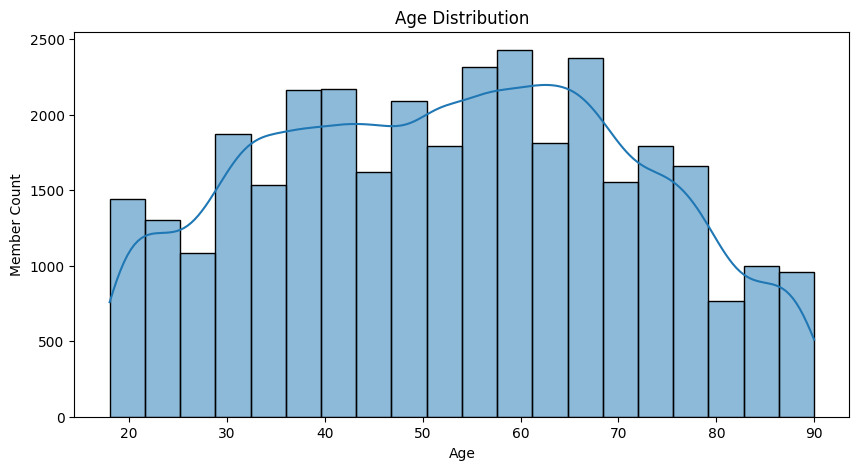

In [56]:
#===========================
# Age Distribution
#===========================

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

sns.histplot(
    master_df["Age"],
    bins=20,
    kde=True
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Member Count")

plt.show()

### Observation

Analyze whether the member population is concentrated within specific age groups.

### Business Interpretation

Understanding age distribution helps identify target populations for preventive care programs and chronic disease management initiatives.

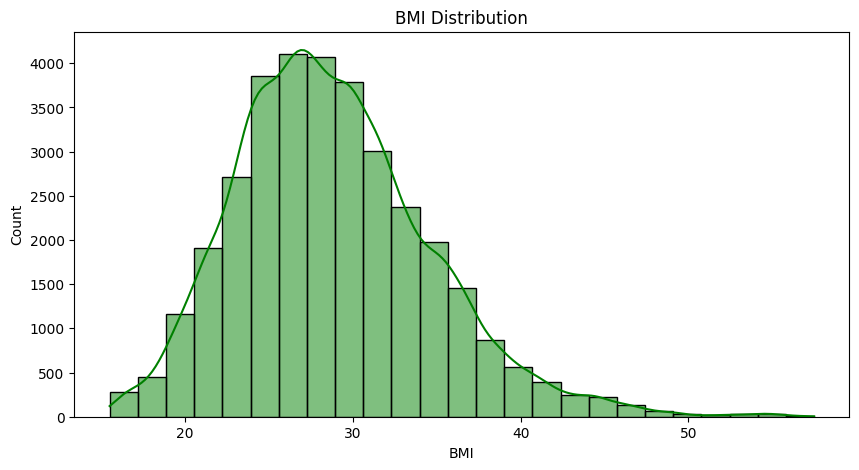

In [57]:
#=============================
# BMI Distribution
#=============================

plt.figure(figsize=(10,5))

sns.histplot(
    master_df["BMI"],
    bins=25,
    kde=True,
    color="green"
)

plt.title("BMI Distribution")

plt.show()

### Observation

Review whether a significant portion of members fall within overweight or obese BMI ranges.

### Business Interpretation

A higher prevalence of elevated BMI may indicate increased future chronic disease burden.

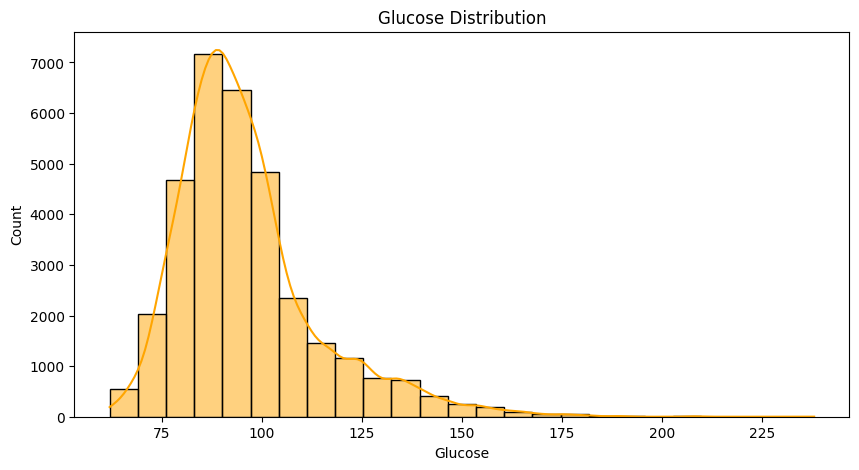

In [58]:
#==============================
# Glucose Distribution
#==============================

plt.figure(figsize=(10,5))

sns.histplot(
    master_df["Glucose"],
    bins=25,
    kde=True,
    color="orange"
)

plt.title("Glucose Distribution")

plt.show()

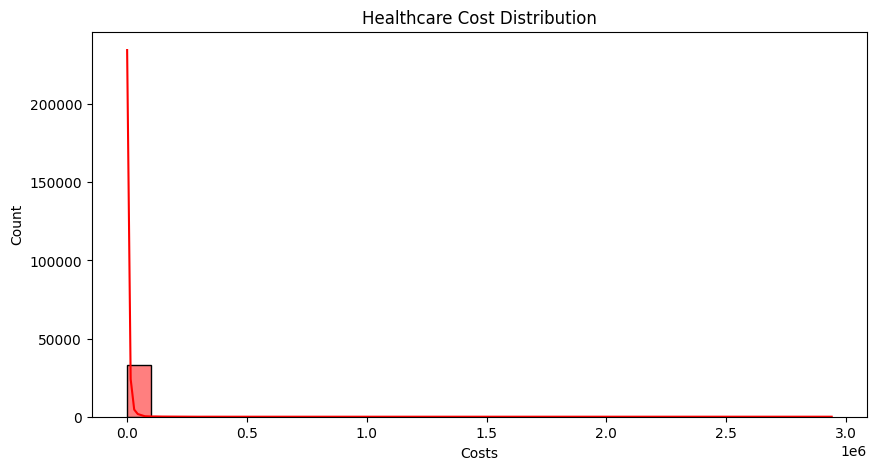

In [59]:
#====================================
# Healthcare Cost Distribution
#====================================

plt.figure(figsize=(10,5))

sns.histplot(
    master_df["Costs"],
    bins=30,
    kde=True,
    color="red"
)

plt.title("Healthcare Cost Distribution")

plt.show()

Healthcare cost distributions are often right-skewed, with a small population of members accounting for a large share of healthcare expenditure.

## PART 2: BIVARIATE ANALYSIS

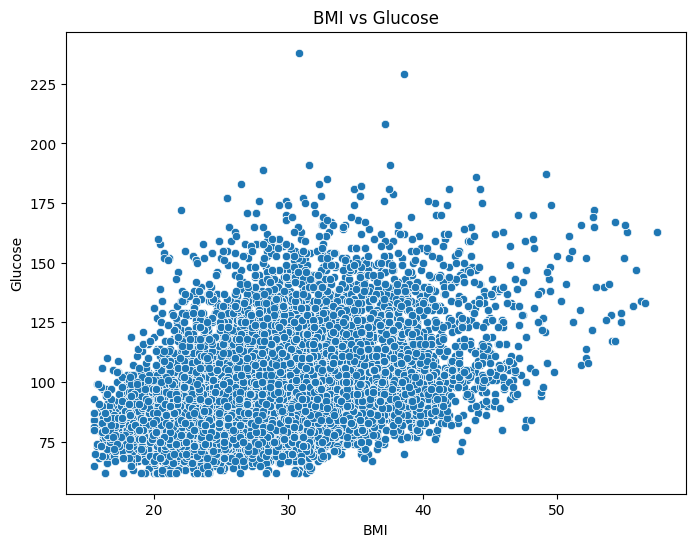

In [60]:
#========================
# BMI vs GLucose
#========================
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=master_df,
    x="BMI",
    y="Glucose"
)

plt.title("BMI vs Glucose")

plt.show()

A positive relationship between BMI and glucose levels may indicate increased diabetes risk among overweight members.

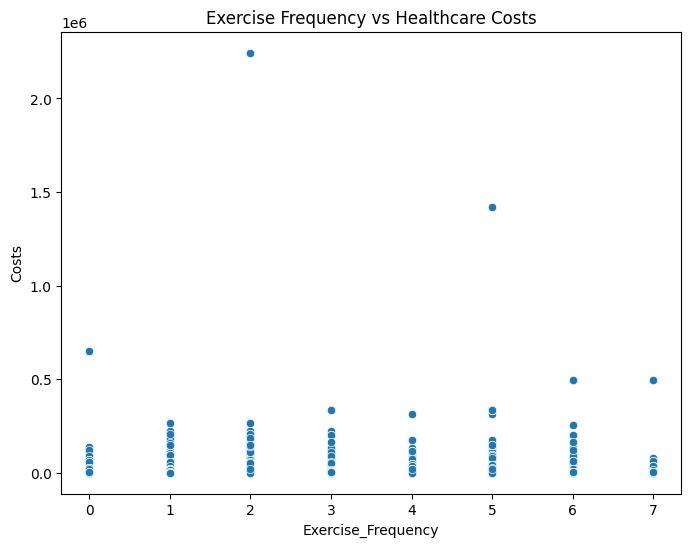

In [61]:
#==============================
# Exercise Frequency vs Costs
#==============================

plt.figure(figsize=(8,6))
sns.scatterplot(
    data=master_df,
    x="Exercise_Frequency",
    y="Costs"
)

plt.title("Exercise Frequency vs Healthcare Costs")
plt.show()

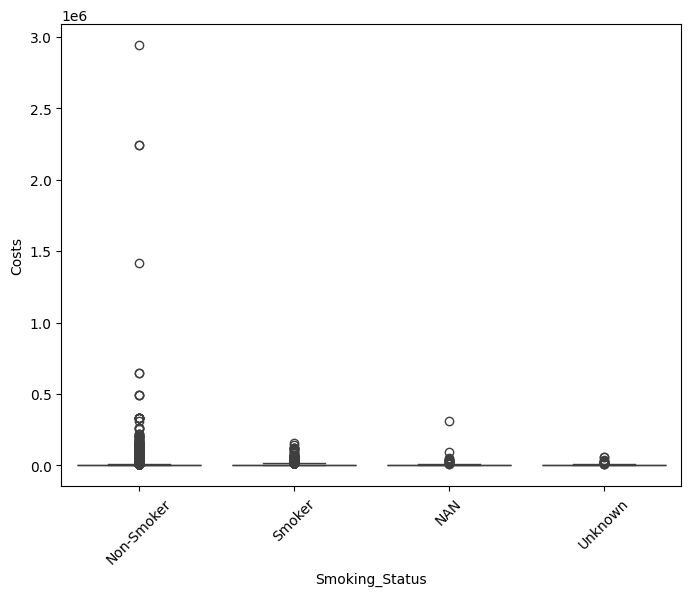

In [62]:
#==============================
# Smoking Status vs Costs
#==============================
# Identify cost burden of smoking.

plt.figure(figsize=(8,6))
sns.boxplot(
    data=master_df,
    x="Smoking_Status",
    y="Costs"
)

plt.xticks(rotation=45)
plt.show()

In [63]:
master_df["Screening_Participation"] = (
    master_df["Screening_Participation"]
    .astype(str)
    .str.strip()
    .str.upper()
)

master_df["Screening_Participation"] = (
    master_df["Screening_Participation"]
    .replace({

        "YES": "Yes",
        "Y": "Yes",
        "TRUE": "Yes",
        "1": "Yes",

        "NO": "No",
        "N": "No",
        "FALSE": "No",
        "0": "No",

        "?": "Unknown",
        "-": "Unknown",
        "UNKNOWN": "Unknown"

    })
)

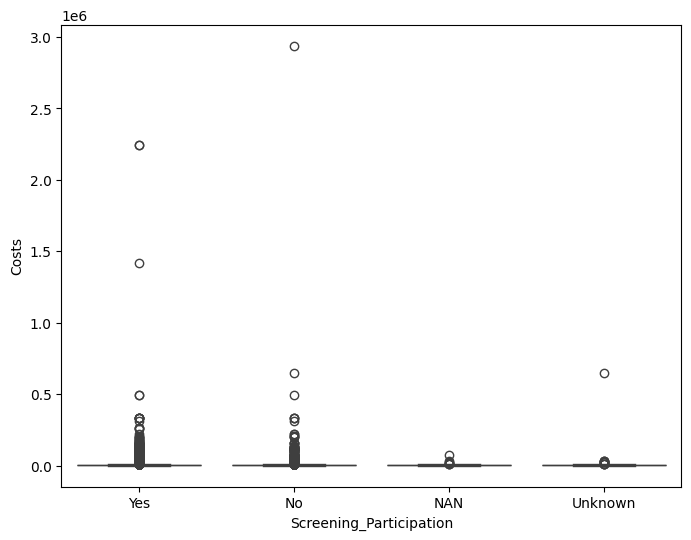

In [64]:
#=================================
# Screening Participation vs Costs
#=================================
# Validate preventive care effectiveness

plt.figure(figsize=(8,6))

sns.boxplot(
    data=master_df,
    x="Screening_Participation",
    y="Costs"
)

plt.show()

## PART 3: OUTLIER ANALYSIS

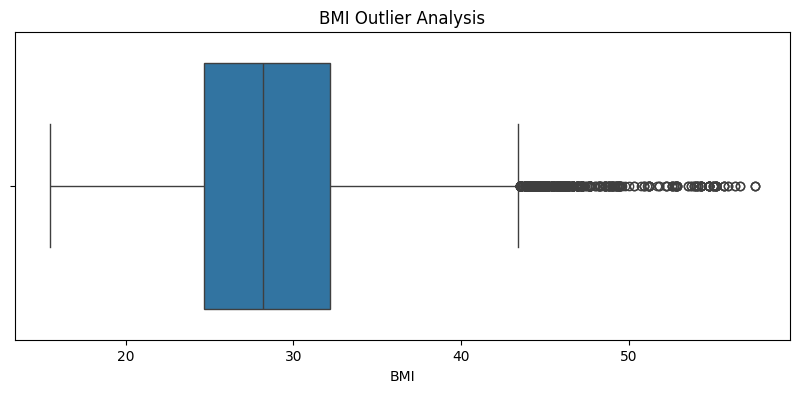

In [65]:
#=======================
# BMI outliers
#=======================
plt.figure(figsize=(10,4))
sns.boxplot(x=master_df["BMI"])
plt.title("BMI Outlier Analysis")
plt.show()

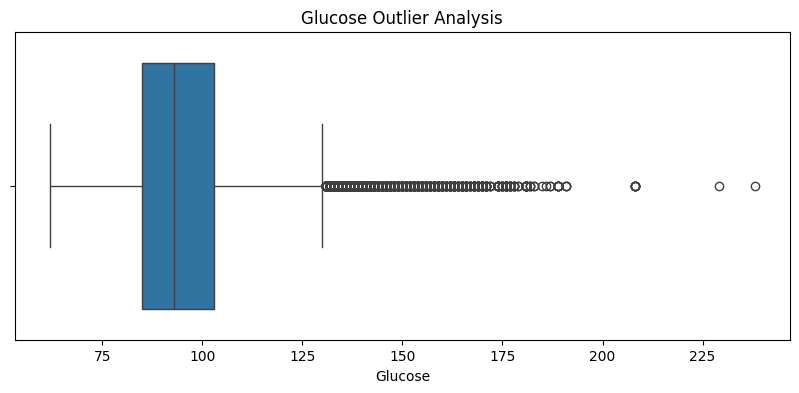

In [66]:
#=========================
# Glucose outliers
#=========================
plt.figure(figsize=(10,4))
sns.boxplot(x=master_df["Glucose"])
plt.title("Glucose Outlier Analysis")
plt.show()

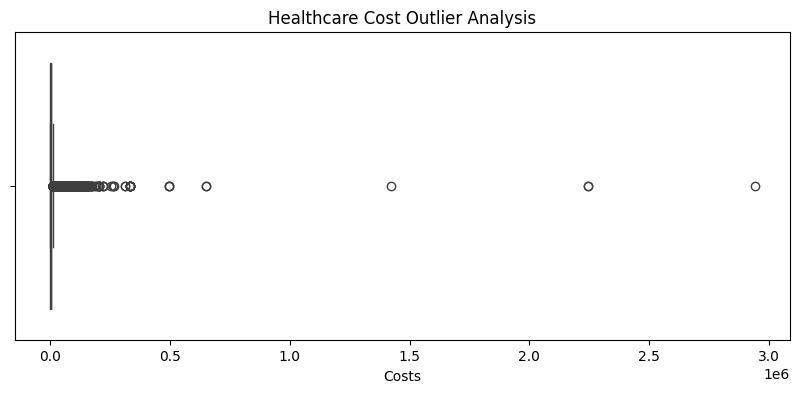

In [67]:
#==================
# Cost Outliers
#==================

plt.figure(figsize=(10,4))
sns.boxplot(x=master_df["Costs"])
plt.title("Healthcare Cost Outlier Analysis")
plt.show()

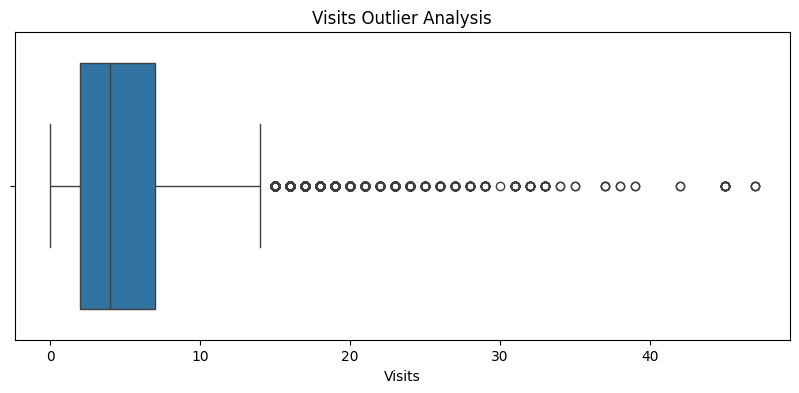

In [68]:
#==========================
# Visit outliers
#==========================
plt.figure(figsize=(10,4))
sns.boxplot(x=master_df["Visits"])
plt.title("Visits Outlier Analysis")
plt.show()

# EDA Key Findings

1. The member population spans a broad age range, indicating diverse healthcare needs across demographic groups.

2. BMI distribution suggests a substantial proportion of members fall within overweight and obese categories, potentially increasing future chronic disease burden.

3. Glucose levels exhibit considerable variation across the member population, indicating the presence of normal, prediabetic, and diabetic risk profiles.

4. Healthcare costs are heavily right-skewed, suggesting a relatively small group of members account for a large proportion of total healthcare expenditure.

5. A positive relationship is observed between BMI and glucose levels, supporting the association between obesity and diabetes risk.

6. Members with higher exercise frequency generally demonstrate lower healthcare cost patterns.

7. Preventive screening participants exhibit different healthcare cost patterns compared to non-participants, highlighting the importance of preventive care.

8. Smoking status appears associated with healthcare expenditure differences, indicating lifestyle factors influence healthcare utilization.

9. Clinical indicators such as BMI, glucose, blood pressure, and HbA1c demonstrate substantial variability and are expected to be strong predictors of future chronic disease.

10. Several healthcare variables contain notable outliers, particularly healthcare costs and utilization metrics, suggesting the presence of a high-risk, high-cost member segment.

# 5. FEATURE ENGINEERING

Creating meaningful variables from existing data, instead of using raw columns.
Raw data ususally does not perform as well as engineered fetures.
- Better ML performance
- Better Business understanding

Feature engineering was performed to create healthcare-specific indicators that improve analytical insights, support predictive modeling, enhance population segmentation, and simplify business interpretation.

The engineered features combine demographic, lifestyle, clinical, preventive care, and healthcare utilization data into meaningful healthcare metrics.

In [69]:
# =====================================================
# Create Working Copy for Feature Engineering
# =====================================================

feature_df = master_df.copy()

print("Feature engineering dataset created successfully.")

Feature engineering dataset created successfully.


In [70]:
feature_df["Age"].dtype

dtype('float64')

In [71]:
feature_df["Region"].value_counts(dropna=False).head(50)

Region
Southern California    12367
Northern California    10755
Mid-Atlantic States     1632
Northwest               1565
Washington              1367
Georgia                 1175
Colorado                1101
Hawaii                   651
Northern Cal             446
SoCal                    369
SOUTHERN CALIFORNIA      348
S. California            336
Southern Cal             334
NorCal                   334
northern california      308
N. California            287
Nevada                   221
NW                       138
MAS                      102
WA                        97
Washington State          72
CO                        70
North West                64
Mid Atlantic              63
georgia                   60
NORTHERN CALIFORNIA       59
Mid-Atlantic              49
colorado                  39
GA                        38
Hawai'i                   27
HI                        23
GEORGIA                   17
NORTH WEST                12
NV                         9
NORCAL 

In [72]:
# =====================================================
# Region Standardization
# =====================================================

feature_df["Region"] = (

    feature_df["Region"]
    .astype(str)
    .str.strip()
    .str.upper()

)

region_mapping = {

    # ---------------------------------
    # NORTHERN CALIFORNIA
    # ---------------------------------

    "NORTHERN CALIFORNIA":
        "Northern California",

    "NORTHERN CAL":
        "Northern California",

    "N. CALIFORNIA":
        "Northern California",

    "NORCAL":
        "Northern California",

    # ---------------------------------
    # SOUTHERN CALIFORNIA
    # ---------------------------------

    "SOUTHERN CALIFORNIA":
        "Southern California",

    "SOUTHERN CAL":
        "Southern California",

    "S. CALIFORNIA":
        "Southern California",

    "SOCAL":
        "Southern California",

    # ---------------------------------
    # MID-ATLANTIC STATES
    # ---------------------------------

    "MID-ATLANTIC STATES":
        "Mid-Atlantic States",

    "MID ATLANTIC":
        "Mid-Atlantic States",

    "MID-ATLANTIC":
        "Mid-Atlantic States",

    "MAS":
        "Mid-Atlantic States",

    # ---------------------------------
    # NORTHWEST
    # ---------------------------------

    "NORTHWEST":
        "Northwest",

    "NORTH WEST":
        "Northwest",

    "NW":
        "Northwest",

    # ---------------------------------
    # WASHINGTON
    # ---------------------------------

    "WASHINGTON":
        "Washington",

    "WASHINGTON STATE":
        "Washington",

    "WA":
        "Washington",

    # ---------------------------------
    # GEORGIA
    # ---------------------------------

    "GEORGIA":
        "Georgia",

    "GA":
        "Georgia",

    # ---------------------------------
    # COLORADO
    # ---------------------------------

    "COLORADO":
        "Colorado",

    "CO":
        "Colorado",

    # ---------------------------------
    # HAWAII
    # ---------------------------------

    "HAWAII":
        "Hawaii",

    "HAWAI'I":
        "Hawaii",

    "HI":
        "Hawaii",

    # ---------------------------------
    # NEVADA
    # ---------------------------------

    "NEVADA":
        "Nevada",

    "NV":
        "Nevada"

}

feature_df["Region"] = (
    feature_df["Region"]
    .replace(region_mapping)
)

In [73]:
feature_df["Region"].value_counts(
    dropna=False
)

Region
Southern California    13754
Northern California    12200
Mid-Atlantic States     1846
Northwest               1780
Washington              1537
Georgia                 1290
Colorado                1210
Hawaii                   701
Nevada                   235
Name: count, dtype: int64

In [74]:
# =====================================================
# Existing Hypertension Flag Standardization
# =====================================================

feature_df["Existing_Hypertension_Flag"] = (
    feature_df["Existing_Hypertension_Flag"]
    .astype(str)
    .str.strip()
    .str.upper()
)

hypertension_mapping = {

    "Y": "Yes",
    "YES": "Yes",
    "1": "Yes",
    "TRUE": "Yes",

    "N": "No",
    "NO": "No",
    "0": "No",
    "FALSE": "No"

}

feature_df["Existing_Hypertension_Flag"] = (
    feature_df["Existing_Hypertension_Flag"]
    .replace(hypertension_mapping)
)

In [75]:
# =====================================================
# Clean Age Column Properly
# =====================================================

# Extract numeric portion if text exists
feature_df["Age"] = (
    feature_df["Age"]
    .astype(str)
    .str.extract(r'(\d+)')[0]
)

# Convert to numeric
feature_df["Age"] = pd.to_numeric(
    feature_df["Age"],
    errors="coerce"
)

print(feature_df["Age"].dtype)

feature_df["Age"].describe()

float64


count    33734.000000
mean        52.823679
std         18.629965
min         18.000000
25%         38.000000
50%         53.000000
75%         67.000000
max         90.000000
Name: Age, dtype: float64

In [76]:
# =====================================================
# Feature 1: Age Group
# =====================================================

feature_df["Age_Group"] = pd.cut(
    feature_df["Age"],
    bins=[0, 30, 45, 60, 100],
    labels=[
        "18-30",
        "31-45",
        "46-60",
        "60+"
    ]
)

feature_df["Age_Group"].value_counts()

Age_Group
60+      12569
46-60     8587
31-45     7880
18-30     4698
Name: count, dtype: int64

In [77]:
feature_df[["Age", "Age_Group"]].head()

,Age,Age_Group
0,35.0,31-45
1,35.0,31-45
2,45.0,31-45
3,45.0,31-45
4,45.0,31-45


In [78]:
# =====================================================
# Feature 2: Wellness Score
# =====================================================

feature_df["Screening_Score"] = np.where(
    feature_df["Screening_Participation"] == "Yes",
    100,
    0
)

feature_df["Wellness_Score"] = (
    feature_df["Exercise_Frequency"].fillna(0) * 10 +
    feature_df["Diet_Score"].fillna(0) +
    feature_df["Screening_Score"]

) / 3

feature_df["Wellness_Score"].describe()

count    34553.000000
mean        51.787954
std         18.872800
min          0.000000
25%         34.633333
50%         57.666667
75%         66.400000
max         90.000000
Name: Wellness_Score, dtype: float64

In [79]:
# =====================================================
# Feature 3: Lifestyle Risk Score
# =====================================================

feature_df["Smoking_Risk"] = np.where(
    feature_df["Smoking_Status"] == "Smoker",
    100,
    0
)

feature_df["BMI_Risk"] = np.where(
    feature_df["BMI"] >= 30, 100,
    np.where(feature_df["BMI"] >= 25, 50,0)
)

feature_df["Exercise_Risk"] = np.where(
    feature_df["Exercise_Frequency"] < 2, 100,
    np.where(feature_df["Exercise_Frequency"] < 4, 50, 0)
)

feature_df["Lifestyle_Risk_Score"] = (
    feature_df["Smoking_Risk"] +
    feature_df["BMI_Risk"] +
    feature_df["Exercise_Risk"]

) / 3

feature_df["Lifestyle_Risk_Score"].describe()

count    34553.000000
mean        35.244407
std         22.212438
min          0.000000
25%         16.666667
50%         33.333333
75%         50.000000
max        100.000000
Name: Lifestyle_Risk_Score, dtype: float64

In [80]:
# =====================================================
# Feature 4: Preventive Compliance Score
# =====================================================

feature_df["Screening_Points"] = np.where(
    feature_df["Screening_Participation"] == "Yes", 100, 0
)

feature_df["Preventive_Compliance_Score"] = (
    feature_df["Screening_Points"] +
    feature_df["Preventive_Screenings_Completed"].fillna(0) * 10 +
    feature_df["Health_Risk_Assessment_Completed"].fillna(0) * 20
) / 3

feature_df["Preventive_Compliance_Score"].describe()

count    34553.000000
mean        30.527113
std         21.467536
min          0.000000
25%          0.000000
50%         43.333333
75%         46.666667
max         53.333333
Name: Preventive_Compliance_Score, dtype: float64

In [81]:
# =====================================================
# Feature 5: Chronic Disease Risk Index
# =====================================================

feature_df["BMI_Norm"] = (feature_df["BMI"] / feature_df["BMI"].max())

feature_df["Glucose_Norm"] = (feature_df["Glucose"] / feature_df["Glucose"].max())

feature_df["HbA1c_Norm"] = (feature_df["HbA1c"] / feature_df["HbA1c"].max())

feature_df["BP_Norm"] = (feature_df["Systolic_BP"] / feature_df["Systolic_BP"].max())

feature_df["Cholesterol_Norm"] = (feature_df["Cholesterol"] / feature_df["Cholesterol"].max())

feature_df["Chronic_Disease_Risk_Index"] = (
    feature_df["BMI_Norm"] +
    feature_df["Glucose_Norm"] +
    feature_df["HbA1c_Norm"] +
    feature_df["BP_Norm"] +
    feature_df["Cholesterol_Norm"]
) / 5

feature_df["Chronic_Disease_Risk_Index"].describe()

count    27452.000000
mean         0.543640
std          0.055132
min          0.375439
25%          0.505546
50%          0.538808
75%          0.576522
max          0.796724
Name: Chronic_Disease_Risk_Index, dtype: float64

In [82]:
# =====================================================
# Feature 6: Cost Per Visit
# =====================================================

feature_df["Cost_Per_Visit"] = np.where(
    feature_df["Visits"] > 0,
    feature_df["Costs"] / feature_df["Visits"],0
)

feature_df["Cost_Per_Visit"].describe()

count     33452.000000
mean       1372.972001
std        6463.544954
min           0.000000
25%         252.912708
50%         452.076429
75%         929.124444
max      473619.333333
Name: Cost_Per_Visit, dtype: float64

In [83]:
engineered_features = [
    "Age_Group",
    "Wellness_Score",
    "Lifestyle_Risk_Score",
    "Preventive_Compliance_Score",
    "Chronic_Disease_Risk_Index",
    "Cost_Per_Visit"
]

feature_df[engineered_features].head()

,Age_Group,Wellness_Score,Lifestyle_Risk_Score,Preventive_Compliance_Score,Chronic_Disease_Risk_Index,Cost_Per_Visit
0,31-45,54.933333,33.333333,43.333333,0.502823,675.282500
1,31-45,54.933333,33.333333,43.333333,0.502823,382.706364
2,31-45,59.366667,16.666667,40.000000,0.499710,406.635000
3,31-45,59.366667,16.666667,40.000000,0.499710,1770.630000
4,31-45,59.366667,16.666667,40.000000,0.470421,406.635000


## Feature Engineering Summary

The following engineered features were created:

1. Age_Group
2. Wellness_Score
3. Lifestyle_Risk_Score
4. Preventive_Compliance_Score
5. Chronic_Disease_Risk_Index
6. Cost_Per_Visit

These features capture key healthcare concepts including demographic segmentation, healthy lifestyle behavior, preventive-care engagement, chronic disease risk, and healthcare utilization efficiency.

The engineered features will be used in subsequent phases including machine learning, clustering, and Power BI reporting.

In [84]:
feature_df[
    [
        "Age_Group",
        "Wellness_Score",
        "Lifestyle_Risk_Score",
        "Preventive_Compliance_Score",
        "Chronic_Disease_Risk_Index",
        "Cost_Per_Visit"
    ]
].describe(include="all")

,Age_Group,Wellness_Score,Lifestyle_Risk_Score,Preventive_Compliance_Score,Chronic_Disease_Risk_Index,Cost_Per_Visit
count,33734,34553.000000,34553.000000,34553.000000,27452.000000,33452.000000
unique,4,NaN,NaN,NaN,NaN,NaN
top,60+,NaN,NaN,NaN,NaN,NaN
freq,12569,NaN,NaN,NaN,NaN,NaN
mean,NaN,51.787954,35.244407,30.527113,0.543640,1372.972001
std,NaN,18.872800,22.212438,21.467536,0.055132,6463.544954
min,NaN,0.000000,0.000000,0.000000,0.375439,0.000000
25%,NaN,34.633333,16.666667,0.000000,0.505546,252.912708
50%,NaN,57.666667,33.333333,43.333333,0.538808,452.076429
75%,NaN,66.400000,50.000000,46.666667,0.576522,929.124444


In [85]:
numeric_cols = [

    "Age",
    "BMI",
    "Glucose",
    "HbA1c",
    "Cholesterol",
    "LDL_Cholesterol",
    "HDL_Cholesterol",
    "Triglycerides",
    "Systolic_BP",
    "Diastolic_BP",
    "Exercise_Frequency",
    "Diet_Score",
    "Visits",
    "ER_Visits",
    "Hospital_Admissions",
    "Medications",
    "Costs",
    "Chronic_Condition_Count"

]

feature_df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,33734.0,52.823679,18.629965,18.0,38.00,53.00,67.00,90.0
BMI,33752.0,28.819015,5.826674,15.5,24.70,28.20,32.20,57.5
Glucose,33229.0,96.312287,17.883991,62.0,85.00,93.00,103.00,238.0
HbA1c,30587.0,5.285373,0.673264,4.0,4.80,5.20,5.60,10.1
Cholesterol,33045.0,187.372189,31.016209,105.0,166.00,187.00,208.00,303.0
LDL_Cholesterol,33818.0,107.328228,34.889637,30.0,83.00,107.00,131.00,246.0
HDL_Cholesterol,33818.0,54.654977,10.488379,24.0,48.00,55.00,62.00,96.0
Triglycerides,33818.0,127.580194,63.219101,35.0,83.00,114.00,157.00,700.0
Systolic_BP,33916.0,120.765686,14.901193,70.0,111.00,122.00,132.00,181.0
Diastolic_BP,34038.0,75.096098,9.651620,45.0,69.00,75.00,81.00,155.0


In [86]:
impute_cols = [

    "Age",
    "BMI",
    "Glucose",
    "HbA1c",
    "Cholesterol",
    "LDL_Cholesterol",
    "HDL_Cholesterol",
    "Triglycerides",
    "Systolic_BP",
    "Diastolic_BP",
    "Exercise_Frequency",
    "Diet_Score",
    "Visits",
    "ER_Visits",
    "Hospital_Admissions",
    "Medications",
    "Costs",
    "Chronic_Condition_Count"

]

for col in impute_cols:

    feature_df[col] = feature_df[col].fillna(
        feature_df[col].median()
    )

In [87]:
# =====================================================
# Feature 7: Blood Pressure Category
# =====================================================

feature_df["BP_Category"] = np.select(
    [
        feature_df["Systolic_BP"] < 120,
        ((feature_df["Systolic_BP"] >= 120) & (feature_df["Systolic_BP"] < 130)),
        ((feature_df["Systolic_BP"] >= 130) & (feature_df["Systolic_BP"] < 140)),
        feature_df["Systolic_BP"] >= 140
    ],

    [
        "Normal",
        "Elevated",
        "Stage 1 Hypertension",
        "Stage 2 Hypertension"
    ],
    default="Unknown"
)
feature_df["BP_Category"].value_counts()

BP_Category
Normal                  15095
Elevated                 9288
Stage 1 Hypertension     6936
Stage 2 Hypertension     3234
Name: count, dtype: int64

In [88]:
# =====================================================
# Feature 8: Family Risk Score
# =====================================================

feature_df["Family_Risk_Score"] = (
    np.where(
        feature_df["Family_History_Diabetes"] == "Yes", 1, 0
    )
    +
    np.where(
        feature_df["Family_History_Hypertension"] == "Yes", 1, 0
    )
)
feature_df["Family_Risk_Score"].value_counts()

Family_Risk_Score
0    17799
1    14152
2     2602
Name: count, dtype: int64

In [89]:
# =====================================================
# Feature 9: Utilization Risk Score
# =====================================================

feature_df["Utilization_Risk_Score"] = (

    feature_df["Visits"].fillna(0) +
    (feature_df["ER_Visits"].fillna(0) * 2) +
    (feature_df["Hospital_Admissions"].fillna(0) * 3) +
    feature_df["Medications"].fillna(0)
)

feature_df["Utilization_Risk_Score"].describe()

count    34553.00000
mean         8.06969
std          5.85460
min          0.00000
25%          4.00000
50%          7.00000
75%         11.00000
max         55.00000
Name: Utilization_Risk_Score, dtype: float64

In [90]:
# =====================================================
# Feature 10: Diabetes Risk Flag
# =====================================================

feature_df["Diabetes_Risk_Flag"] = np.select(
    [
        ((feature_df["Glucose"] >= 126) | (feature_df["HbA1c"] >= 6.5)),

        ((feature_df["Glucose"] >= 100) | (feature_df["HbA1c"] >= 5.7))
    ],

    ["High Risk", "Moderate Risk"],
    default="Low Risk"
)
feature_df["Diabetes_Risk_Flag"].value_counts()

Diabetes_Risk_Flag
Low Risk         23194
Moderate Risk     8604
High Risk         2755
Name: count, dtype: int64

In [91]:
# =====================================================
# Feature 11: Wellness Engagement Category
# =====================================================

feature_df["Wellness_Engagement_Category"] = pd.cut(
    feature_df["Wellness_Score"],
    bins=[-1, 33, 66, 100],
    labels=[
        "Low Engagement",
        "Moderate Engagement",
        "High Engagement"
    ]
)
feature_df["Wellness_Engagement_Category"].value_counts()

Wellness_Engagement_Category
Moderate Engagement    17696
High Engagement         9050
Low Engagement          7807
Name: count, dtype: int64

In [92]:
advanced_features = [
    "BP_Category",
    "Family_Risk_Score",
    "Utilization_Risk_Score",
    "Diabetes_Risk_Flag",
    "Wellness_Engagement_Category"
]
feature_df[advanced_features].head()

,BP_Category,Family_Risk_Score,Utilization_Risk_Score,Diabetes_Risk_Flag,Wellness_Engagement_Category
0,Normal,0,6.0,Low Risk,Moderate Engagement
1,Normal,0,12.0,Low Risk,Moderate Engagement
2,Stage 1 Hypertension,2,3.0,Low Risk,Moderate Engagement
3,Stage 1 Hypertension,2,9.0,Low Risk,Moderate Engagement
4,Normal,2,3.0,Moderate Risk,Moderate Engagement


## Feature Engineering Summary

The following healthcare-oriented features were engineered:

### Mandatory Features

1. Age_Group
2. Wellness_Score
3. Lifestyle_Risk_Score
4. Preventive_Compliance_Score
5. Chronic_Disease_Risk_Index
6. Cost_Per_Visit

### Advanced Healthcare Features

7. BP_Category
8. Family_Risk_Score
9. Utilization_Risk_Score
10. Diabetes_Risk_Flag
11. Wellness_Engagement_Category

These engineered variables improve disease risk assessment, preventive care evaluation, healthcare utilization monitoring, population segmentation, and predictive modeling performance.

The resulting dataset is now suitable for machine learning model development and clustering analysis.

In [93]:
feature_df["Develops_Chronic_Disease_12M"].value_counts(dropna=False)

feature_df["Develops_Chronic_Disease_12M"].value_counts(normalize=True) * 100

Develops_Chronic_Disease_12M
0.0    89.453352
1.0    10.546648
Name: proportion, dtype: float64

In [94]:
feature_df["Develops_Chronic_Disease_12M"].isnull().sum()

125

In [95]:
feature_df = feature_df.dropna(subset=["Develops_Chronic_Disease_12M"])

In [96]:
leakage_features = [
    "Develops_Diabetes_12M",
    "Develops_Hypertension_12M"
]

print(leakage_features)

['Develops_Diabetes_12M', 'Develops_Hypertension_12M']


In [97]:
feature_df["Develops_Chronic_Disease_12M"].value_counts()

Develops_Chronic_Disease_12M
0.0    30797
1.0     3631
Name: count, dtype: int64

In [98]:
feature_df["Develops_Chronic_Disease_12M"].value_counts(normalize=True)

Develops_Chronic_Disease_12M
0.0    0.894534
1.0    0.105466
Name: proportion, dtype: float64

In [99]:
feature_df["Region"].value_counts().tail(20)

Region
Southern California    13688
Northern California    12160
Mid-Atlantic States     1842
Northwest               1778
Washington              1532
Georgia                 1286
Colorado                1208
Hawaii                   699
Nevada                   235
Name: count, dtype: int64

In [100]:
feature_df["Age_Group"] = (
    feature_df["Age_Group"]
    .astype(str)
    .replace("nan", "Unknown")
)

In [101]:
feature_df["Cost_Per_Visit"] = (
    feature_df["Cost_Per_Visit"]
    .fillna(0)
)

In [102]:
feature_df["Chronic_Disease_Risk_Index"] = (
    feature_df["Chronic_Disease_Risk_Index"]
    .fillna(
        feature_df["Chronic_Disease_Risk_Index"].median()
    )
)

In [103]:
feature_df[
    [
        "Chronic_Disease_Risk_Index",
        "Cost_Per_Visit",
        "Age_Group"
    ]
].isnull().sum()

Chronic_Disease_Risk_Index    0
Cost_Per_Visit                0
Age_Group                     0
dtype: int64

In [104]:
# =====================================================
# Create ML Working Dataset
# =====================================================

ml_df = feature_df.copy()

print("Shape of ML Dataset:")
print(ml_df.shape)

Shape of ML Dataset:
(34428, 85)


In [105]:
# to prevent data leakage these columns have been dropped

cols_to_drop = [
    "Member_ID",
    "Develops_Diabetes_12M",
    "Develops_Hypertension_12M"
]

ml_df = ml_df.drop(columns=cols_to_drop, errors="ignore")

In [106]:
ml_df.to_csv("ML_Ready_Dataset.csv", index=False)
print("ML Ready Dataset Created Successfully.")

ML Ready Dataset Created Successfully.


## Feature Selection Strategy

The following groups of variables were selected:

### Demographic Features

Age
Gender
Age_Group
Region

### Lifestyle Features

Exercise_Frequency
Smoking_Status
Diet_Score

### Clinical Features

BMI
Glucose
HbA1c
Cholesterol
LDL_Cholesterol
HDL_Cholesterol
Triglycerides
Systolic_BP
Diastolic_BP

### Wellness Features

Wellness_Score
Preventive_Compliance_Score

### Claims Features

Visits
ER_Visits
Hospital_Admissions
Costs
Cost_Per_Visit
Utilization_Risk_Score

### Family History

Family_History_Diabetes
Family_History_Hypertension
Family_Risk_Score

### Engineered Features

Lifestyle_Risk_Score
Chronic_Disease_Risk_Index
Diabetes_Risk_Flag

In [107]:
# =====================================================
# Define Target Variable
# =====================================================

TARGET = "Develops_Chronic_Disease_12M"

In [108]:
# =====================================================
# Features for Modeling
# =====================================================

selected_features = [
    # Demographics
    "Age",
    "Gender",
    "Region",
    "Age_Group",

    # Lifestyle
    "Exercise_Frequency",
    "Smoking_Status",
    "Diet_Score",

    # Clinical
    "BMI",
    "Glucose",
    "HbA1c",
    "Cholesterol",
    "LDL_Cholesterol",
    "HDL_Cholesterol",
    "Triglycerides",
    "Systolic_BP",
    "Diastolic_BP",

    # Wellness
    "Wellness_Score",
    "Preventive_Compliance_Score",

    # Claims
    "Visits",
    "ER_Visits",
    "Hospital_Admissions",
    "Medications",
    "Costs",
    "Cost_Per_Visit",

    # Family Risk
    "Family_History_Diabetes",
    "Family_History_Hypertension",
    "Family_Risk_Score",

    # Engineered Features
    "Lifestyle_Risk_Score",
    # "Chronic_Disease_Risk_Index",
    "Utilization_Risk_Score",

    # Categories
    "BP_Category",
    # "Diabetes_Risk_Flag",
    "Wellness_Engagement_Category"
]

In [109]:
# =====================================================
# Create Modeling Dataset
# =====================================================

model_df = ml_df[selected_features + [TARGET]].copy()
print(model_df.shape)
model_df.head()

(34428, 32)


,Age,Gender,Region,Age_Group,Exercise_Frequency,Smoking_Status,Diet_Score,BMI,Glucose,HbA1c,Cholesterol,LDL_Cholesterol,HDL_Cholesterol,Triglycerides,Systolic_BP,Diastolic_BP,Wellness_Score,Preventive_Compliance_Score,Visits,ER_Visits,Hospital_Admissions,Medications,Costs,Cost_Per_Visit,Family_History_Diabetes,Family_History_Hypertension,Family_Risk_Score,Lifestyle_Risk_Score,Utilization_Risk_Score,BP_Category,Wellness_Engagement_Category,Develops_Chronic_Disease_12M
0,35.0,Female,Northern California,31-45,0.0,Non-Smoker,64.8,24.4,81.0,4.6,223.0,153.0,49.0,103.0,101.0,63.0,54.933333,43.333333,4.0,1.0,0.0,0.0,2701.13,675.282500,No,No,0,33.333333,6.0,Normal,Moderate Engagement,0.0
1,35.0,Female,Northern California,31-45,0.0,Non-Smoker,64.8,24.4,81.0,4.6,223.0,153.0,49.0,103.0,101.0,63.0,54.933333,43.333333,11.0,0.0,0.0,1.0,4209.77,382.706364,No,No,0,33.333333,12.0,Normal,Moderate Engagement,0.0
2,45.0,Male,Southern California,31-45,3.0,Non-Smoker,48.1,16.7,87.0,4.6,201.0,103.0,62.0,182.0,131.0,76.0,59.366667,40.000000,2.0,0.0,0.0,1.0,813.27,406.635000,Yes,Yes,2,16.666667,3.0,Stage 1 Hypertension,Moderate Engagement,0.0
3,45.0,Male,Southern California,31-45,3.0,Non-Smoker,48.1,16.7,87.0,4.6,201.0,103.0,62.0,182.0,131.0,76.0,59.366667,40.000000,4.0,2.0,0.0,1.0,7082.52,1770.630000,Yes,Yes,2,16.666667,9.0,Stage 1 Hypertension,Moderate Engagement,0.0
4,45.0,Male,Southern California,31-45,3.0,Non-Smoker,48.1,17.3,104.0,5.1,157.0,82.0,54.0,103.0,107.0,72.0,59.366667,40.000000,2.0,0.0,0.0,1.0,813.27,406.635000,Yes,Yes,2,16.666667,3.0,Normal,Moderate Engagement,0.0


In [110]:
model_df.isnull().sum().sort_values(ascending=False).head(20)

Age                             0
Gender                          0
Wellness_Engagement_Category    0
BP_Category                     0
Utilization_Risk_Score          0
Lifestyle_Risk_Score            0
Family_Risk_Score               0
Family_History_Hypertension     0
Family_History_Diabetes         0
Cost_Per_Visit                  0
Costs                           0
Medications                     0
Hospital_Admissions             0
ER_Visits                       0
Visits                          0
Preventive_Compliance_Score     0
Wellness_Score                  0
Diastolic_BP                    0
Systolic_BP                     0
Triglycerides                   0
dtype: int64

In [111]:
# =====================================================
# Identify Numerical and Categorical Columns
# =====================================================

numeric_features = model_df.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = model_df.select_dtypes(include=["object", "category"]).columns.tolist()

if TARGET in numeric_features:
    numeric_features.remove(TARGET)

if TARGET in categorical_features:
    categorical_features.remove(TARGET)

print("Numeric Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numeric Features:
['Age', 'Exercise_Frequency', 'Diet_Score', 'BMI', 'Glucose', 'HbA1c', 'Cholesterol', 'LDL_Cholesterol', 'HDL_Cholesterol', 'Triglycerides', 'Systolic_BP', 'Diastolic_BP', 'Wellness_Score', 'Preventive_Compliance_Score', 'Visits', 'ER_Visits', 'Hospital_Admissions', 'Medications', 'Costs', 'Cost_Per_Visit', 'Lifestyle_Risk_Score', 'Utilization_Risk_Score']

Categorical Features:
['Gender', 'Region', 'Age_Group', 'Smoking_Status', 'Family_History_Diabetes', 'Family_History_Hypertension', 'BP_Category', 'Wellness_Engagement_Category']


In [112]:
missing_summary = pd.DataFrame({
    "Feature":model_df.columns,
    "Missing_Count": model_df.isnull().sum().values,
    "Missing_Percent":(model_df.isnull().mean()*100).round(2).values
})

missing_summary.sort_values("Missing_Percent", ascending=False)

,Feature,Missing_Count,Missing_Percent
0,Age,0,0.0
1,Gender,0,0.0
30,Wellness_Engagement_Category,0,0.0
29,BP_Category,0,0.0
28,Utilization_Risk_Score,0,0.0
27,Lifestyle_Risk_Score,0,0.0
26,Family_Risk_Score,0,0.0
25,Family_History_Hypertension,0,0.0
24,Family_History_Diabetes,0,0.0
23,Cost_Per_Visit,0,0.0


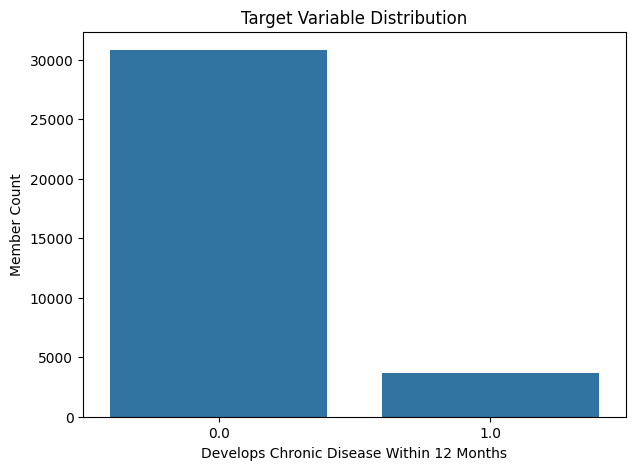

In [113]:
import seaborn as sns
import matplotlib.pyplot as plt

# =====================================================
# Target Class Distribution
# =====================================================

plt.figure(figsize=(7,5))
sns.countplot(x=TARGET, data=model_df)
plt.title("Target Variable Distribution")
plt.xlabel("Develops Chronic Disease Within 12 Months")
plt.ylabel("Member Count")
plt.show()

In [114]:
# =====================================================
# Exact Duplicate Records
# =====================================================

duplicate_rows = feature_df.duplicated().sum()

print("Duplicate Rows:", duplicate_rows)

Duplicate Rows: 0


In [115]:
feature_df["Member_ID"].nunique()

9982

In [116]:
print("Total Rows:")
print(feature_df.shape[0])

print("\nUnique Members:")
print(feature_df["Member_ID"].nunique())

print("\nDuplicate Member IDs:")
print(feature_df["Member_ID"].duplicated().sum())

Total Rows:
34428

Unique Members:
9982

Duplicate Member IDs:
24446


In [117]:
feature_df.groupby(
    "Member_ID"
)[
    "Develops_Chronic_Disease_12M"
].nunique().value_counts()

Develops_Chronic_Disease_12M
1    9255
2     727
Name: count, dtype: int64

In [118]:
feature_df.groupby("Member_ID").size().describe()

count    9982.000000
mean        3.449008
std         3.224175
min         1.000000
25%         2.000000
50%         2.000000
75%         4.000000
max        36.000000
dtype: float64

In [119]:
conflicting_members = (

    feature_df.groupby("Member_ID")[
        "Develops_Chronic_Disease_12M"
    ]
    .nunique()
)

conflicting_members = conflicting_members[
    conflicting_members > 1
]

print(conflicting_members.shape)

(727,)


In [120]:
sample_members = conflicting_members.index[:5]

feature_df[
    feature_df["Member_ID"].isin(sample_members)
][

    [
        "Member_ID",
        "Develops_Chronic_Disease_12M",
        "Develops_Diabetes_12M",
        "Develops_Hypertension_12M"
    ]

].sort_values("Member_ID")

,Member_ID,Develops_Chronic_Disease_12M,Develops_Diabetes_12M,Develops_Hypertension_12M
19186,KPM00019,0.0,0,0
19188,KPM00019,1.0,0,1
19187,KPM00019,1.0,0,1
19185,KPM00019,0.0,0,0
19184,KPM00019,1.0,0,1
19177,KPM00019,0.0,0,0
19178,KPM00019,0.0,0,0
19179,KPM00019,1.0,0,1
19180,KPM00019,1.0,0,1
19181,KPM00019,0.0,0,0


In [121]:
[c for c in feature_df.columns if "date" in c.lower()]

['Member_Since_Date',
 'Date_Key_x',
 'Record_Date',
 'Date_Key_y',
 'Screening_Date',
 'Date_Key',
 'Period_End_Date']

In [122]:
[c for c in feature_df.columns if "year" in c.lower()]

['Tenure_Years', 'Claim_Year']

In [123]:
date_cols = [

    "Member_Since_Date",
    "Record_Date",
    "Screening_Date",
    "Period_End_Date"

]

for col in date_cols:

    print("\n", col)
    print(feature_df[col].dtype)


 Member_Since_Date
object

 Record_Date
object

 Screening_Date
object

 Period_End_Date
object


In [124]:
# =====================================================
# Convert Date Columns
# =====================================================

date_columns = [
    "Member_Since_Date",
    "Record_Date",
    "Screening_Date",
    "Period_End_Date"
]

for col in date_columns:
    if col in feature_df.columns:
        feature_df[col] = pd.to_datetime(
            feature_df[col],
            errors="coerce"
        )

print("Date conversion completed.")

Date conversion completed.


In [125]:
feature_df[
    [
        "Record_Date",
        "Screening_Date",
        "Period_End_Date"
    ]
].isnull().sum()

Record_Date        3483
Screening_Date     3421
Period_End_Date    3477
dtype: int64

In [126]:
feature_df["SDOH_Vulnerability_Index"] = pd.to_numeric(feature_df["SDOH_Vulnerability_Index"],errors="coerce")
print(feature_df["SDOH_Vulnerability_Index"].dtype)

float64


In [127]:
feature_df["Tenure_Years"] = pd.to_numeric(feature_df["Tenure_Years"],errors="coerce")
print(feature_df["Tenure_Years"].dtype)

float64


In [128]:
latest_member_df = (feature_df.sort_values("Screening_Date").groupby("Member_ID").tail(1))

In [129]:
latest_member_df.shape

(9982, 85)

In [130]:
# =====================================================
# Create Snapshot Date
# =====================================================

feature_df["Snapshot_Date"] = feature_df[
    [
        "Screening_Date",
        "Record_Date",
        "Period_End_Date"
    ]
].max(axis=1)

print("Snapshot Date Created")

Snapshot Date Created


In [131]:
# =====================================================
# Sort Dataset By Latest Record
# =====================================================

feature_df = feature_df.sort_values("Snapshot_Date")

In [132]:
# =====================================================
# Create Member-Level Dataset
# =====================================================

member_level_df = (feature_df.groupby("Member_ID").tail(1).reset_index(drop=True))

print("Rows:", member_level_df.shape[0])
print("Unique Members:", member_level_df["Member_ID"].nunique())

Rows: 9982
Unique Members: 9982


In [133]:
member_level_df["Develops_Chronic_Disease_12M"].value_counts()

Develops_Chronic_Disease_12M
0.0    8946
1.0    1036
Name: count, dtype: int64

In [134]:
member_level_df["Develops_Chronic_Disease_12M"].value_counts(normalize=True)

Develops_Chronic_Disease_12M
0.0    0.896213
1.0    0.103787
Name: proportion, dtype: float64

In [135]:
member_level_df.shape

(9982, 86)

In [136]:
member_level_df.isnull().sum().sort_values(ascending=False).head(20)

Health_Risk_Assessment_Completed    9982
Member_Since_Date                   1499
HbA1c_Norm                          1093
Screening_Date                       943
Record_Date                          925
Period_End_Date                      814
Cholesterol_Norm                     464
Glucose_Norm                         385
BMI_Norm                             227
SDOH_Vulnerability_Index             200
Blood_Pressure                       190
BP_Norm                              189
Tenure_Years                         150
Snapshot_Date                         29
Costs                                  0
Claim_Year                             0
ER_Visits                              0
Claim_Record_ID                        0
Hospital_Admissions                    0
Medications                            0
dtype: int64

In [137]:
member_level_df.drop(columns=["Health_Risk_Assessment_Completed"],inplace=True)

In [138]:
ml_df = member_level_df.copy()

In [139]:
cols_to_drop = [

    # IDs
    "Member_ID",

    # Dates
    "Member_Since_Date",
    "Screening_Date",
    "Record_Date",
    "Period_End_Date",
    "Snapshot_Date",

    "Develops_Diabetes_12M",
    "Develops_Hypertension_12M",

    # Helper engineering columns
    "BMI_Norm",
    "Glucose_Norm",
    "HbA1c_Norm",
    "BP_Norm",
    "Cholesterol_Norm",

    # Replaced variables
    "Blood_Pressure",

    # Fully missing
    "Health_Risk_Assessment_Completed"

]

ml_df = ml_df.drop(columns=cols_to_drop,errors="ignore")

print("Shape after cleanup:")
print(ml_df.shape)

Shape after cleanup:
(9982, 71)


In [140]:
missing_check = (ml_df.isnull().sum().sort_values(ascending=False))

missing_check[missing_check > 0]

SDOH_Vulnerability_Index    200
Tenure_Years                150
dtype: int64

In [141]:
# =====================================================
# Final Missing Value Imputation
# =====================================================

# Impute SDOH Vulnerability Index
feature_df["SDOH_Vulnerability_Index"] = (feature_df["SDOH_Vulnerability_Index"].fillna(feature_df["SDOH_Vulnerability_Index"].median()))

# Impute Tenure Years
feature_df["Tenure_Years"] = (feature_df["Tenure_Years"].fillna(feature_df["Tenure_Years"].median()))

print("Missing value imputation completed.")

Missing value imputation completed.


In [142]:
# =====================================================
# Multi-Class Disease Target
# =====================================================

def disease_type(row):

    diabetes = row["Develops_Diabetes_12M"]

    hypertension = row["Develops_Hypertension_12M"]

    if diabetes == 1 and hypertension == 1:
        return "Both"

    elif diabetes == 1:
        return "Diabetes"

    elif hypertension == 1:
        return "Hypertension"

    else:
        return "None"

member_level_df["Disease_Type"] = (

    member_level_df
    .apply(
        disease_type,
        axis=1
    )

)

member_level_df[
    "Disease_Type"
].value_counts()

Disease_Type
None            8946
Hypertension     575
Diabetes         436
Both              25
Name: count, dtype: int64

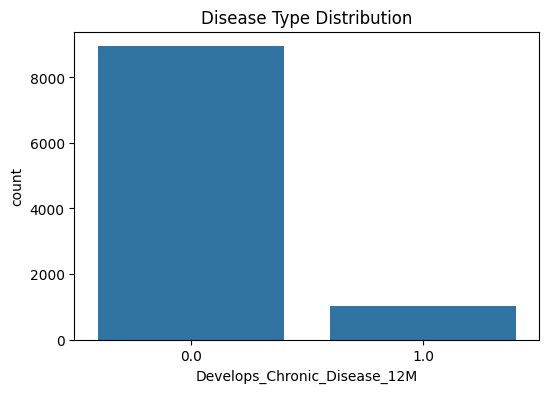

In [143]:
plt.figure(figsize=(6,4))

sns.countplot(

    data=member_level_df,

    x="Develops_Chronic_Disease_12M"

)

plt.title(
    "Disease Type Distribution"
)

plt.show()

In [144]:
from sklearn.preprocessing import LabelEncoder

disease_encoder = LabelEncoder()

y_multiclass = disease_encoder.fit_transform(

    member_level_df[
        "Disease_Type"
    ]

)

print(
    dict(
        zip(
            disease_encoder.classes_,
            range(
                len(
                    disease_encoder.classes_
                )
            )
        )
    )
)

{'Both': 0, 'Diabetes': 1, 'Hypertension': 2, 'None': 3}


In [145]:
# =====================================================
# Create Final ML Dataset
# =====================================================

ml_df = member_level_df.copy()
# Target Variable
TARGET = "Disease_Type"

# Columns to Remove
cols_to_drop = [

    # IDs
    "Member_ID",
    "Region_ID",
    "Home_Facility_ID",
    "Wellness_Record_ID",
    "Program_ID",
    "Screening_ID",
    "Facility_ID",
    "Claim_Record_ID",

    # Future Outcome Leakage
    "Develops_Diabetes_12M",
    "Develops_Hypertension_12M",

    # Date Fields
    "Member_Since_Date",
    "Record_Date",
    "Screening_Date",
    "Period_End_Date",
    "Snapshot_Date",

    # Helper Feature Columns
    "BMI_Norm",
    "Glucose_Norm",
    "HbA1c_Norm",
    "BP_Norm",
    "Cholesterol_Norm",

    # Replaced Feature
    "Blood_Pressure"

]

ml_df = ml_df.drop(columns=cols_to_drop, errors="ignore")

print("ML Dataset Shape:")
print(ml_df.shape)

ML Dataset Shape:
(9982, 65)


In [146]:
# =====================================================
# Final ML Imputation
# =====================================================

ml_df["SDOH_Vulnerability_Index"] = (pd.to_numeric(ml_df["SDOH_Vulnerability_Index"],errors="coerce"))

ml_df["Tenure_Years"] = (pd.to_numeric(ml_df["Tenure_Years"],errors="coerce"))

ml_df["SDOH_Vulnerability_Index"] = (ml_df["SDOH_Vulnerability_Index"].fillna(ml_df["SDOH_Vulnerability_Index"].median()))

ml_df["Tenure_Years"] = (ml_df["Tenure_Years"].fillna(ml_df["Tenure_Years"].median()))

In [147]:
ml_df[["SDOH_Vulnerability_Index", "Tenure_Years"]].isnull().sum()

SDOH_Vulnerability_Index    0
Tenure_Years                0
dtype: int64

In [148]:
# =====================================================
# Identify Numeric and Categorical Features
# =====================================================

numeric_features = ml_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = ml_df.select_dtypes(include=["object", "category"]).columns.tolist()

if TARGET in numeric_features:
    numeric_features.remove(TARGET)

if TARGET in categorical_features:
    categorical_features.remove(TARGET)

print("Numeric Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

Numeric Features: 40
Categorical Features: 18


In [149]:
# =====================================================
# Final Null Value Validation
# =====================================================

missing_summary = pd.DataFrame({
    "Missing_Count":ml_df.isnull().sum(),
    "Missing_Percent":(ml_df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary[missing_summary["Missing_Count"] > 0]
missing_summary.sort_values("Missing_Count", ascending=False)

,Missing_Count,Missing_Percent


In [150]:
# =====================================================
# One-Hot Encoding
# =====================================================

model_encoded = pd.get_dummies(ml_df, columns=categorical_features, drop_first=True)

print("Encoded Dataset Shape:")
print(model_encoded.shape)

Encoded Dataset Shape:
(9982, 124)


In [151]:
# =====================================================
# Create Feature Matrix and Target Vector
# =====================================================

X = model_encoded.drop(TARGET, axis=1)
y = y_multiclass

print("Feature Matrix:", X.shape)
print("Target Vector:", y.shape)

Feature Matrix: (9982, 123)
Target Vector: (9982,)


In [152]:
from sklearn.model_selection import train_test_split

# =====================================================
# Train-Test Split
# =====================================================

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

print("Training Set:", X_train.shape)
print("Testing Set :", X_test.shape)

Training Set: (7985, 123)
Testing Set : (1997, 123)


In [153]:
# =====================================================
# Training Target Distribution
# =====================================================

train_counts = pd.Series(y_train).value_counts().sort_index()
train_pct = pd.Series(y_train).value_counts(normalize=True).sort_index() * 100

class_distribution = pd.DataFrame({
    "Count": train_counts,
    "Percentage": train_pct.round(2)
})

# Optional: rename encoded class labels back to the original disease names
class_distribution.index = disease_encoder.inverse_transform(class_distribution.index.to_numpy())

class_distribution

,Count,Percentage
Both,20,0.25
Diabetes,349,4.37
Hypertension,460,5.76
None,7156,89.62


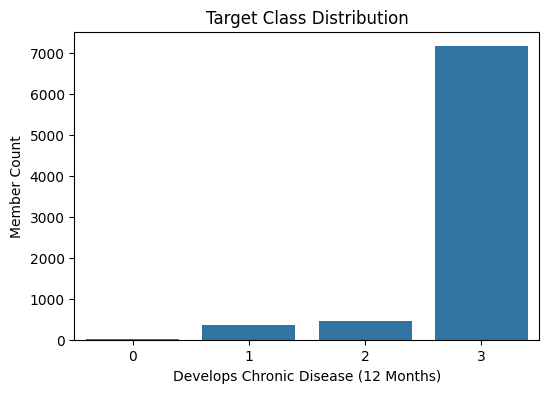

In [154]:
import matplotlib.pyplot as plt
import seaborn as sns

# =====================================================
# Visualize Class Distribution
# =====================================================

plt.figure(figsize=(6,4))
sns.countplot(x = y_train)
plt.title("Target Class Distribution")
plt.xlabel("Develops Chronic Disease (12 Months)")
plt.ylabel("Member Count")
plt.show()

## Class Imbalance Handling
The target variable exhibits class imbalance, with approximately 10% of members developing chronic disease within 12 months.

To improve the model's ability to identify high-risk members, SMOTE (Synthetic Minority Oversampling Technique) is applied to the training data only.

This helps ensure that disease cases receive sufficient representation during model training.

In [155]:
# =====================================================
# Import SMOTE
# =====================================================

from imblearn.over_sampling import SMOTE

# =====================================================
# Apply SMOTE ONLY on Training Data
# =====================================================

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Original Training Shape:")
print(X_train.shape)

print("\nSMOTE Training Shape:")
print(X_train_smote.shape)

Original Training Shape:
(7985, 123)

SMOTE Training Shape:
(28624, 123)


In [156]:
# =====================================================
# Verify Balanced Classes
# =====================================================

y_train_smote_series = pd.Series(y_train_smote)

balanced_distribution = pd.DataFrame({
    "Count": y_train_smote_series.value_counts().sort_index(),
    "Percentage": (y_train_smote_series.value_counts(normalize=True).sort_index() * 100).round(2)
})

balanced_distribution.index = disease_encoder.inverse_transform(
    balanced_distribution.index.to_numpy()
)

balanced_distribution

,Count,Percentage
Both,7156,25.0
Diabetes,7156,25.0
Hypertension,7156,25.0
None,7156,25.0


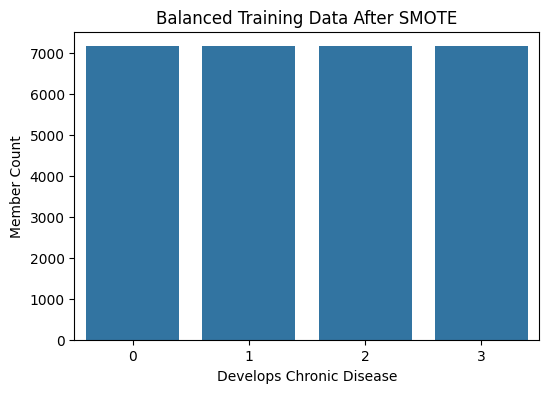

In [157]:
# =====================================================
# Class Distribution After SMOTE
# =====================================================

plt.figure(figsize=(6,4))
sns.countplot(x=y_train_smote)
plt.title("Balanced Training Data After SMOTE")
plt.xlabel("Develops Chronic Disease")
plt.ylabel("Member Count")
plt.show()

In [158]:
# =====================================================
# Machine Learning Evaluation Libraries
# =====================================================

import numpy as np
import pandas as pd

from itertools import product

from sklearn.metrics import (

    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,

    confusion_matrix,
    classification_report,

    roc_curve,
    precision_recall_curve

)

from sklearn.model_selection import (

    StratifiedKFold,
    cross_val_score

)

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [159]:
# =====================================================
# Generate All Hyperparameter Combinations
# =====================================================

def create_param_grid(param_dict):
    
    keys = list(param_dict.keys())
    
    values = list(param_dict.values())
    
    combinations = [
        
        dict(zip(keys, combo))
        
        for combo in product(*values)
        
    ]
    
    return combinations

In [160]:
# =====================================================
# Cross Validation
# =====================================================

def cross_validate_model(
    model,
    X_train,
    y_train
):
    
    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )
    
    cv_scores = cross_val_score(
        
        model,
        
        X_train,
        y_train,
        
        cv=skf,
        
        scoring="recall"
        
    )
    
    return cv_scores.mean()

In [161]:
# =====================================================
# Generic Experiment Runner
# =====================================================

def run_hyperparameter_experiment(

    model_class,

    parameter_grid,

    model_name,

    X_train,
    y_train,

    X_test,
    y_test

):
    
    results = []
    
    for params in parameter_grid:
        
        model = model_class(**params)
        
        model.fit(
            X_train,
            y_train
        )
        
        y_pred = model.predict(X_test)
        
        y_prob = model.predict_proba(
            X_test
        )
        
        cv_recall = np.nan
        
        results.append({
            
            "Model": model_name,
            
            **params,
            
            "Accuracy":
                accuracy_score(
                    y_test,
                    y_pred
                ),
            
            "Precision":
                precision_score(
                    y_test,
                    y_pred,
                    average = "weighted"
                ),
            
            "Recall":
                recall_score(
                    y_test,
                    y_pred,
                    average = "weighted"
                ),
            
            "F1":
                f1_score(
                    y_test,
                    y_pred,
                    average = "weighted"
                ),
            
            "ROC_AUC":
                roc_auc_score(
                    y_test,
                    y_prob,
                    multi_class = "ovr",
                    average = "weighted"
                ),
            
            "CV_Recall":
                cv_recall
            
        })
    
    return pd.DataFrame(results)

In [162]:
# =====================================================
# Store Experiments
# =====================================================

experiment_results = {}

# 1. LOGISTIC REGRESSION 
The impact of regularization strength on chronic disease prediction performance was evaluated.

Recall remains the primary metric because healthcare organizations prioritize identifying high-risk members.

In [163]:
# from sklearn.linear_model import LogisticRegression

# log_params = {

#     "C":[
#         0.01,
#         0.1,
#         1,
#         10
#     ],

#     "penalty":[
#         "l2"
#     ],

#     "solver":[
#         "saga"
#     ],

#     "class_weight":[
#         "balanced"
#     ],

#     "max_iter":[5000],

#     "random_state":[42]

# }

# log_grid = create_param_grid(
#     log_params
# )

# # Use full multiclass probability matrix for ROC-AUC
# log_experiment_results = run_hyperparameter_experiment(
#     LogisticRegression,
#     log_grid,
#     "Logistic Regression",
#     X_train_smote,
#     y_train_smote,
#     X_test,
#     y_test
# )

# experiment_results[
#     "Logistic Regression"
# ] = log_experiment_results

# display(
#     log_experiment_results
#     .sort_values(
#         "Recall",
#         ascending=False
#     )
# )

In [164]:
member_level_df["Disease_Type"].value_counts()

Disease_Type
None            8946
Hypertension     575
Diabetes         436
Both              25
Name: count, dtype: int64

# 2. DECISION TREE 

In [165]:
from sklearn.tree import DecisionTreeClassifier

tree_params = {

    "max_depth":[
        3,
        5,
        10,
        15
    ],

    "criterion":[
        "gini",
        "entropy"
    ],

    "min_samples_split":[
        2,
        5,
        10
    ],

    "class_weight":[
        "balanced"
    ],

    "random_state":[42]

}

tree_grid = create_param_grid(
    tree_params
)

tree_experiment_results = run_hyperparameter_experiment(

    DecisionTreeClassifier,

    tree_grid,

    "Decision Tree",

    X_train_smote,
    y_train_smote,

    X_test,
    y_test

)

experiment_results[
    "Decision Tree"
] = tree_experiment_results

display(
    tree_experiment_results
    .sort_values(
        "Recall",
        ascending=False
    )
)

,Model,max_depth,criterion,min_samples_split,class_weight,random_state,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Recall
18,Decision Tree,15,gini,2,balanced,42,0.983475,0.984240,0.983475,0.983784,0.993480,NaN
20,Decision Tree,15,gini,10,balanced,42,0.982474,0.983192,0.982474,0.982763,0.993464,NaN
12,Decision Tree,10,gini,2,balanced,42,0.981973,0.985336,0.981973,0.983342,0.997557,NaN
13,Decision Tree,10,gini,5,balanced,42,0.981973,0.985336,0.981973,0.983342,0.997557,NaN
19,Decision Tree,15,gini,5,balanced,42,0.980971,0.982360,0.980971,0.981524,0.992649,NaN
14,Decision Tree,10,gini,10,balanced,42,0.980971,0.984305,0.980971,0.982333,0.997018,NaN
16,Decision Tree,10,entropy,5,balanced,42,0.977967,0.978250,0.977967,0.977864,0.994730,NaN
15,Decision Tree,10,entropy,2,balanced,42,0.977967,0.978250,0.977967,0.977864,0.994730,NaN
17,Decision Tree,10,entropy,10,balanced,42,0.976965,0.975702,0.976965,0.976200,0.994208,NaN
23,Decision Tree,15,entropy,10,balanced,42,0.976965,0.976994,0.976965,0.976741,0.990205,NaN


In [166]:
# =====================================================
# Final Decision Tree Model
# =====================================================

from sklearn.tree import DecisionTreeClassifier

final_decision_tree = DecisionTreeClassifier(

    max_depth= 15,

    criterion="gini",

    min_samples_split=2,

    class_weight="balanced",

    random_state=42

)

final_decision_tree.fit(

    X_train_smote,

    y_train_smote

)

print("Final Decision Tree Trained")

Final Decision Tree Trained


# 3. RANDOM FOREST

In [167]:
from sklearn.ensemble import RandomForestClassifier

rf_params = {

    "n_estimators":[
        100,
        200
    ],

    "max_depth":[
        5,
        10,
        15
    ],

    "max_features":[
        "sqrt",
        "log2"
    ],

    "class_weight":[
        "balanced"
    ],

    "random_state":[42],

    "n_jobs":[-1]

}

rf_grid = create_param_grid(
    rf_params
)

rf_experiment_results = run_hyperparameter_experiment(

    RandomForestClassifier,

    rf_grid,

    "Random Forest",

    X_train_smote,
    y_train_smote,

    X_test,
    y_test

)

experiment_results[
    "Random Forest"
] = rf_experiment_results

display(
    rf_experiment_results
    .sort_values(
        "Recall",
        ascending=False
    )
)

C:\Users\P295295\AppData\Roaming\Python\Python310\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\P295295\AppData\Roaming\Python\Python310\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\P295295\AppData\Roaming\Python\Python310\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.c

,Model,n_estimators,max_depth,max_features,class_weight,random_state,n_jobs,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Recall
4,Random Forest,100,15,sqrt,balanced,42,-1,0.980471,0.978693,0.980471,0.979481,0.999167,NaN
10,Random Forest,200,15,sqrt,balanced,42,-1,0.980471,0.978693,0.980471,0.979481,0.999371,NaN
2,Random Forest,100,10,sqrt,balanced,42,-1,0.978968,0.979729,0.978968,0.978878,0.999129,NaN
8,Random Forest,200,10,sqrt,balanced,42,-1,0.977967,0.978403,0.977967,0.977666,0.999171,NaN
11,Random Forest,200,15,log2,balanced,42,-1,0.972459,0.969184,0.972459,0.970495,0.999060,NaN
5,Random Forest,100,15,log2,balanced,42,-1,0.970456,0.967009,0.970456,0.968118,0.998877,NaN
6,Random Forest,200,5,sqrt,balanced,42,-1,0.969454,0.973907,0.969454,0.971101,0.995239,NaN
9,Random Forest,200,10,log2,balanced,42,-1,0.966950,0.965076,0.966950,0.964941,0.998295,NaN
0,Random Forest,100,5,sqrt,balanced,42,-1,0.966450,0.970466,0.966450,0.967885,0.993559,NaN
7,Random Forest,200,5,log2,balanced,42,-1,0.963445,0.965850,0.963445,0.963145,0.988321,NaN


# 4. GRADIENT BOOSTING

In [168]:
# from sklearn.ensemble import GradientBoostingClassifier

# gb_params = {

#     "n_estimators":[
#         # 100,
#         200
#     ],

#     "learning_rate":[
#         0.01,
#         0.1
#     ],

#     "max_depth":[
#         3,
#         5
#     ],

#     "random_state":[42]

# }

# gb_grid = create_param_grid(
#     gb_params
# )

# gb_experiment_results = run_hyperparameter_experiment(

#     GradientBoostingClassifier,

#     gb_grid,
#     "Gradient Boosting",
#     X_train_smote,
#     y_train_smote,
#     X_test,
#     y_test

# )

# experiment_results[
#     "Gradient Boosting"
# ] = gb_experiment_results

# display(
#     gb_experiment_results
#     .sort_values(
#         "Recall",
#         ascending=False
#     )
# )

# XGBOOST

In [169]:
from xgboost import XGBClassifier

# =====================================================
# XGBoost Hyperparameter Grid
# =====================================================

xgb_params = {

    "n_estimators": [
        100,
        200
    ],

    "max_depth": [
        3,
        5
    ],

    "learning_rate": [
        0.05,
        0.1
    ],

    "subsample": [
        0.8
    ],

    "colsample_bytree": [
        0.8
    ],

    "random_state": [
        42
    ]

}

xgb_grid = create_param_grid(
    xgb_params
)

xgb_experiment_results = run_hyperparameter_experiment(

    XGBClassifier,

    xgb_grid,
    "XGBoost",
    X_train_smote,
    y_train_smote,
    X_test,
    y_test

)

experiment_results[
    "XGBoost"
] = xgb_experiment_results

display(
    xgb_experiment_results
    .sort_values(
        "Recall",
        ascending=False
    )
)

,Model,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,random_state,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Recall
3,XGBoost,100,5,0.10,0.8,0.8,42,0.982474,0.982556,0.982474,0.982496,0.999602,NaN
5,XGBoost,200,3,0.10,0.8,0.8,42,0.981472,0.981081,0.981472,0.981213,0.999594,NaN
7,XGBoost,200,5,0.10,0.8,0.8,42,0.980971,0.979387,0.980971,0.980161,0.999567,NaN
6,XGBoost,200,5,0.05,0.8,0.8,42,0.980471,0.980651,0.980471,0.980510,0.999600,NaN
2,XGBoost,100,5,0.05,0.8,0.8,42,0.979970,0.980490,0.979970,0.980027,0.999579,NaN
4,XGBoost,200,3,0.05,0.8,0.8,42,0.978968,0.980022,0.978968,0.979267,0.999587,NaN
1,XGBoost,100,3,0.10,0.8,0.8,42,0.978468,0.979438,0.978468,0.978765,0.999586,NaN
0,XGBoost,100,3,0.05,0.8,0.8,42,0.976965,0.980203,0.976965,0.978131,0.999551,NaN


In [170]:
best_models = []

for model_name, df in experiment_results.items():
    
    best_row = (
        
        df
        .sort_values(
            ["Recall", "ROC_AUC"],
            ascending=False
        )
        .head(1)
        
    )
    
    best_models.append(best_row)

best_models_df = pd.concat(
    best_models,
    ignore_index=True
)

display(best_models_df.round(4))

,Model,max_depth,criterion,min_samples_split,class_weight,random_state,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Recall,n_estimators,max_features,n_jobs,learning_rate,subsample,colsample_bytree
0,Decision Tree,15,gini,2.0,balanced,42,0.9835,0.9842,0.9835,0.9838,0.9935,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Random Forest,15,NaN,NaN,balanced,42,0.9805,0.9787,0.9805,0.9795,0.9994,NaN,200.0,sqrt,-1.0,NaN,NaN,NaN
2,XGBoost,5,NaN,NaN,NaN,42,0.9825,0.9826,0.9825,0.9825,0.9996,NaN,100.0,NaN,NaN,0.1,0.8,0.8


In [171]:
final_model_comparison = (

    best_models_df[

        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "CV_Recall"
        ]

    ]

    .sort_values(
        "Recall",
        ascending=False
    )

)

display(
    final_model_comparison.round(4)
)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Recall
0,Decision Tree,0.9835,0.9842,0.9835,0.9838,0.9935,NaN
2,XGBoost,0.9825,0.9826,0.9825,0.9825,0.9996,NaN
1,Random Forest,0.9805,0.9787,0.9805,0.9795,0.9994,NaN


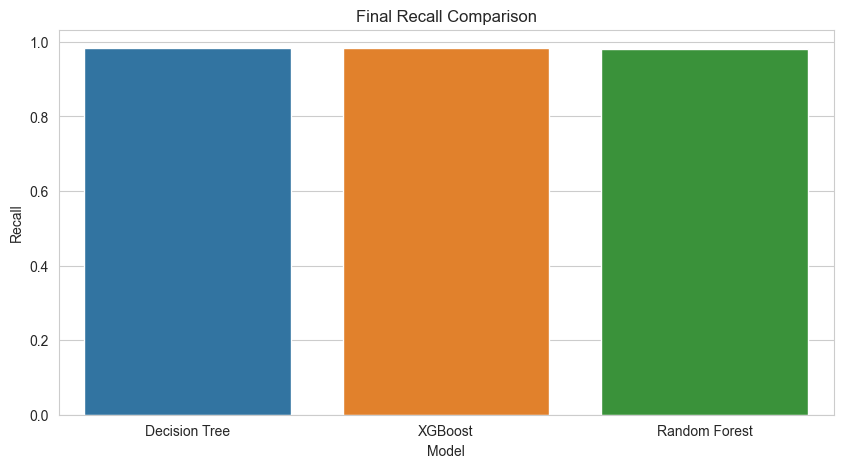

In [172]:
plt.figure(figsize=(10,5))

sns.barplot(

    data=final_model_comparison,

    x="Model",

    y="Recall",

    hue="Model",

    legend=False

)

plt.title(
    "Final Recall Comparison"
)

plt.show()

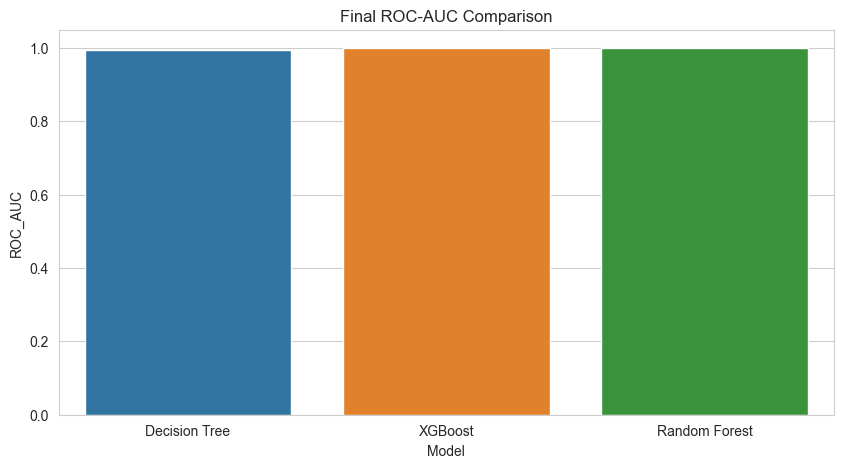

In [173]:
plt.figure(figsize=(10,5))

sns.barplot(

    data=final_model_comparison,

    x="Model",

    y="ROC_AUC",

    hue="Model",

    legend=False

)

plt.title(
    "Final ROC-AUC Comparison"
)

plt.show()

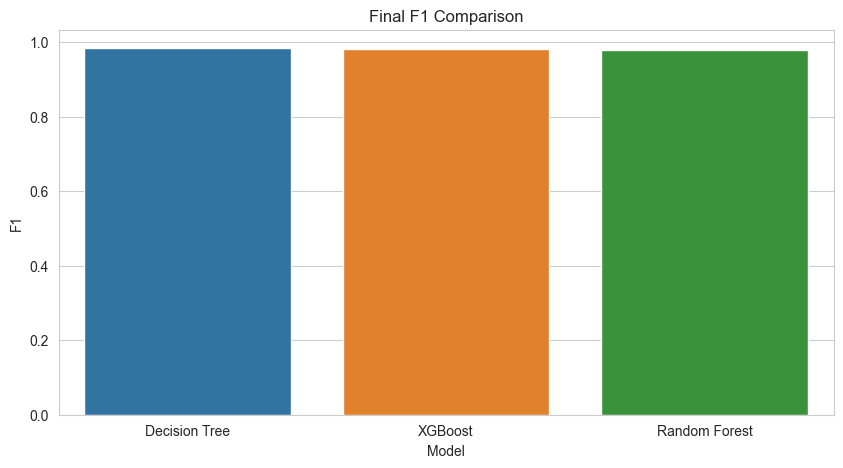

In [174]:
plt.figure(figsize=(10,5))

sns.barplot(

    data=final_model_comparison,

    x="Model",

    y="F1",

    hue="Model",

    legend=False

)

plt.title(
    "Final F1 Comparison"
)

plt.show()

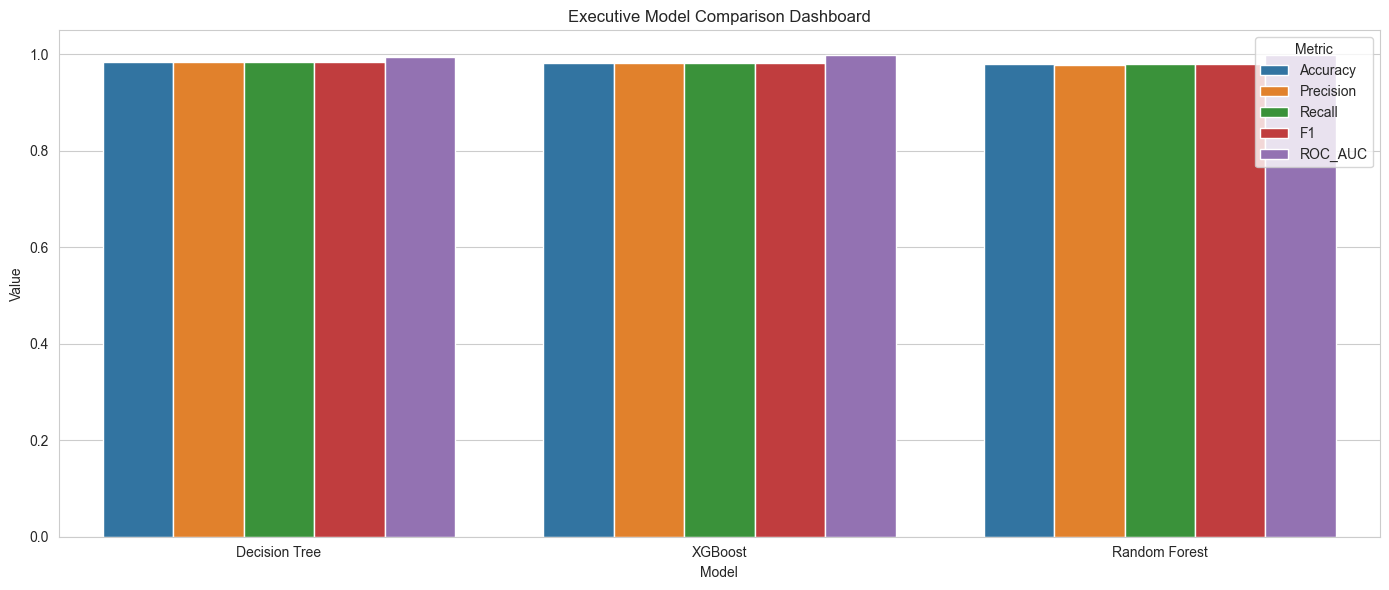

In [175]:
metrics_plot = final_model_comparison.melt(

    id_vars="Model",

    value_vars=[

        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC"

    ],

    var_name="Metric",

    value_name="Value"

)

plt.figure(figsize=(14,6))

sns.barplot(

    data=metrics_plot,

    x="Model",

    y="Value",

    hue="Metric"

)

plt.title(
    "Executive Model Comparison Dashboard"
)

plt.tight_layout()

plt.show()

In [176]:
best_model = (

    final_model_comparison
    .sort_values(
        ["Recall", "ROC_AUC"],
        ascending=False
    )
    .head(1)

)

display(best_model.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Recall
0,Decision Tree,0.9835,0.9842,0.9835,0.9838,0.9935,NaN


In [177]:
best_rf_params = {

    "n_estimators": 200,
    "max_depth": 10,
    "max_features": "sqrt",
    "class_weight": "balanced",
    "random_state": 42,
    "n_jobs": -1

}

In [178]:
# =====================================================
# Final Random Forest Model
# =====================================================

from sklearn.ensemble import RandomForestClassifier

final_rf = RandomForestClassifier(
    **best_rf_params
)

final_rf.fit(
    X_train_smote,
    y_train_smote
)

print("Final Random Forest Trained")

Final Random Forest Trained


In [179]:
# =====================================================
# Predict First 20 Test Members
# =====================================================

predictions = final_decision_tree.predict(
    X_test.iloc[:20]
)

probabilities = final_decision_tree.predict_proba(
    X_test.iloc[:20]
)

prediction_demo = pd.DataFrame({

    "Actual":

        disease_encoder.inverse_transform(
            y_test[:20]
        ),

    "Predicted":

        disease_encoder.inverse_transform(
            predictions
        )

})

display(prediction_demo)

,Actual,Predicted
0,None,None
1,None,None
2,None,None
3,None,None
4,None,None
5,Hypertension,Hypertension
6,None,None
7,None,None
8,None,None
9,None,None


In [180]:
# =====================================================
# Feature Importance Extraction
# =====================================================

dt_importance = pd.DataFrame({

    "Feature": X_train.columns,

    "Importance":
        final_decision_tree.feature_importances_

})

dt_importance = (

    dt_importance
    .sort_values(
        "Importance",
        ascending=False
    )

)

dt_importance.head(20)

,Feature,Importance
20,Develops_Chronic_Disease_12M,0.338512
111,Existing_Hypertension_Flag_Yes,0.222991
28,Chronic_Condition_Count,0.161181
119,Diabetes_Risk_Flag_Low Risk,0.070947
104,Existing_Diabetes_Flag_1,0.046143
0,Age,0.019262
17,Glucose,0.012618
16,Triglycerides,0.009086
57,Race_Ethnicity_Hispanic/Latino,0.008654
120,Diabetes_Risk_Flag_Moderate Risk,0.008017


In [181]:
dt_importance.head(20).to_csv(
    "feature_importance.csv",
    index=False
)

In [182]:
# =====================================================
# Multiple Member Predictions
# =====================================================

sample_members = X_test.iloc[:10]

pred_classes = final_decision_tree.predict(
    sample_members
)

pred_labels = disease_encoder.inverse_transform(
    pred_classes
)

summary = member_level_df.loc[
    sample_members.index,
    [
        "Member_ID",
        "Age",
        "BMI",
        "Glucose",
        "HbA1c",
        "Systolic_BP",
        "Medications",
        "Chronic_Condition_Count"
    ]
].copy()

summary["Predicted_Disease"] = pred_labels

display(summary)

,Member_ID,Age,BMI,Glucose,HbA1c,Systolic_BP,Medications,Chronic_Condition_Count,Predicted_Disease
7579,KPM02500,30.0,27.5,76.0,4.9,102.0,1.0,0.0,None
641,KPM03935,23.0,28.6,71.0,5.0,106.0,0.0,0.0,None
3828,KPM04213,37.0,25.3,82.0,5.2,105.0,0.0,0.0,None
3838,KPM00157,56.0,29.7,90.0,5.2,115.0,1.0,0.0,None
1566,KPM07720,39.0,18.5,95.0,4.6,90.0,1.0,0.0,None
6466,KPM00059,70.0,18.8,80.0,4.5,138.0,9.0,2.0,Hypertension
3931,KPM02852,78.0,27.2,111.0,5.2,130.0,2.0,1.0,None
5117,KPM04836,44.0,31.0,88.0,5.2,121.0,0.0,0.0,None
7142,KPM00969,61.0,20.5,103.0,6.1,119.0,0.0,0.0,None
7014,KPM01743,56.0,28.3,127.0,6.3,128.0,6.0,1.0,None


C:\Users\P295295\AppData\Local\Temp\ipykernel_13264\4292386469.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


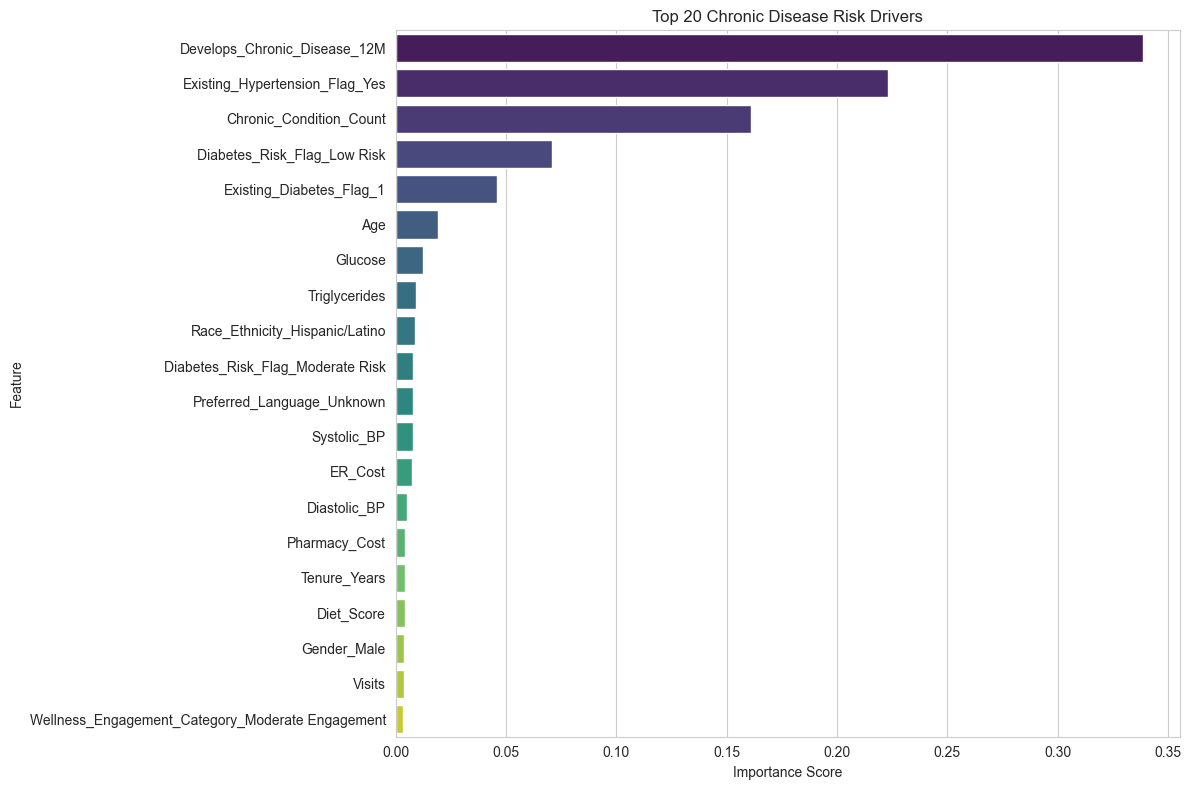

In [183]:
# =====================================================
# Top 20 Feature Importance
# =====================================================

top_features = dt_importance.head(20)

plt.figure(figsize=(12,8))

sns.barplot(

    data=top_features,

    x="Importance",

    y="Feature",

    palette="viridis"

)

plt.title(
    "Top 20 Chronic Disease Risk Drivers"
)

plt.xlabel(
    "Importance Score"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()

plt.show()

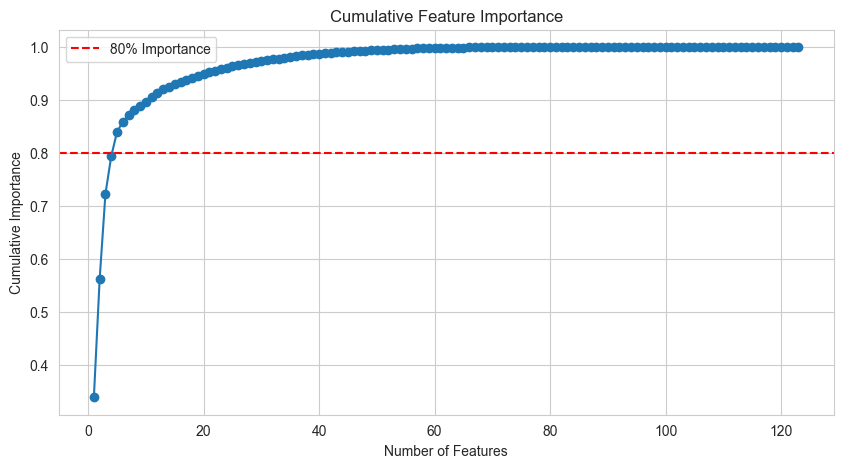

In [184]:
# =====================================================
# Cumulative Feature Importance
# =====================================================

dt_importance["Cumulative"] = (
    dt_importance["Importance"]
    .cumsum()
)

plt.figure(figsize=(10,5))

plt.plot(

    range(1, len(dt_importance)+1),

    dt_importance["Cumulative"],

    marker="o"

)

plt.axhline(
    0.80,
    color="red",
    linestyle="--",
    label="80% Importance"
)

plt.title(
    "Cumulative Feature Importance"
)

plt.xlabel(
    "Number of Features"
)

plt.ylabel(
    "Cumulative Importance"
)

plt.legend()

plt.show()

In [185]:
top_risk_drivers = (
    dt_importance
    .head(10)
    .reset_index(drop=True)
)

top_risk_drivers

,Feature,Importance,Cumulative
0,Develops_Chronic_Disease_12M,0.338512,0.338512
1,Existing_Hypertension_Flag_Yes,0.222991,0.561503
2,Chronic_Condition_Count,0.161181,0.722684
3,Diabetes_Risk_Flag_Low Risk,0.070947,0.793631
4,Existing_Diabetes_Flag_1,0.046143,0.839774
5,Age,0.019262,0.859037
6,Glucose,0.012618,0.871655
7,Triglycerides,0.009086,0.880741
8,Race_Ethnicity_Hispanic/Latino,0.008654,0.889395
9,Diabetes_Risk_Flag_Moderate Risk,0.008017,0.897412


In [186]:
dt_importance.tail(20)

,Feature,Importance,Cumulative
55,Region_Washington,0.0,1.0
56,Race_Ethnicity_Black/African American,0.0,1.0
59,Race_Ethnicity_Native Hawaiian/Pacific Islander,0.0,1.0
62,Plan_Type_Employer Group,0.0,1.0
63,Plan_Type_Federal Employee (FEHB),0.0,1.0
65,Plan_Type_Medicaid,0.0,1.0
66,Plan_Type_Medicare Advantage,0.0,1.0
67,Digital_Engagement_Low,0.0,1.0
69,Digital_Engagement_No Usage,0.0,1.0
70,Digital_Engagement_Unknown,0.0,1.0


In [187]:
# =====================================================
# Bottom 20 Least Important Features
# =====================================================

least_important_features = (

    dt_importance
    .sort_values(
        "Importance",
        ascending=True
    )
    .head(20)

)

display(
    least_important_features
)

,Feature,Importance,Cumulative
122,Wellness_Engagement_Category_High Engagement,0.0,1.0
19,Model_Eligible_Flag,0.0,1.0
4,Program_Enrolled_Flag,0.0,1.0
87,Screening_Participation_Unknown,0.0,1.0
61,Race_Ethnicity_White,0.0,1.0
113,Age_Group_46-60,0.0,1.0
108,Existing_Diabetes_Flag_TRUE,0.0,1.0
105,Existing_Diabetes_Flag_FALSE,0.0,1.0
109,Existing_Diabetes_Flag_Y,0.0,1.0
102,Screening_Type_preventive wellness visit,0.0,1.0


C:\Users\P295295\AppData\Local\Temp\ipykernel_13264\3030906671.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


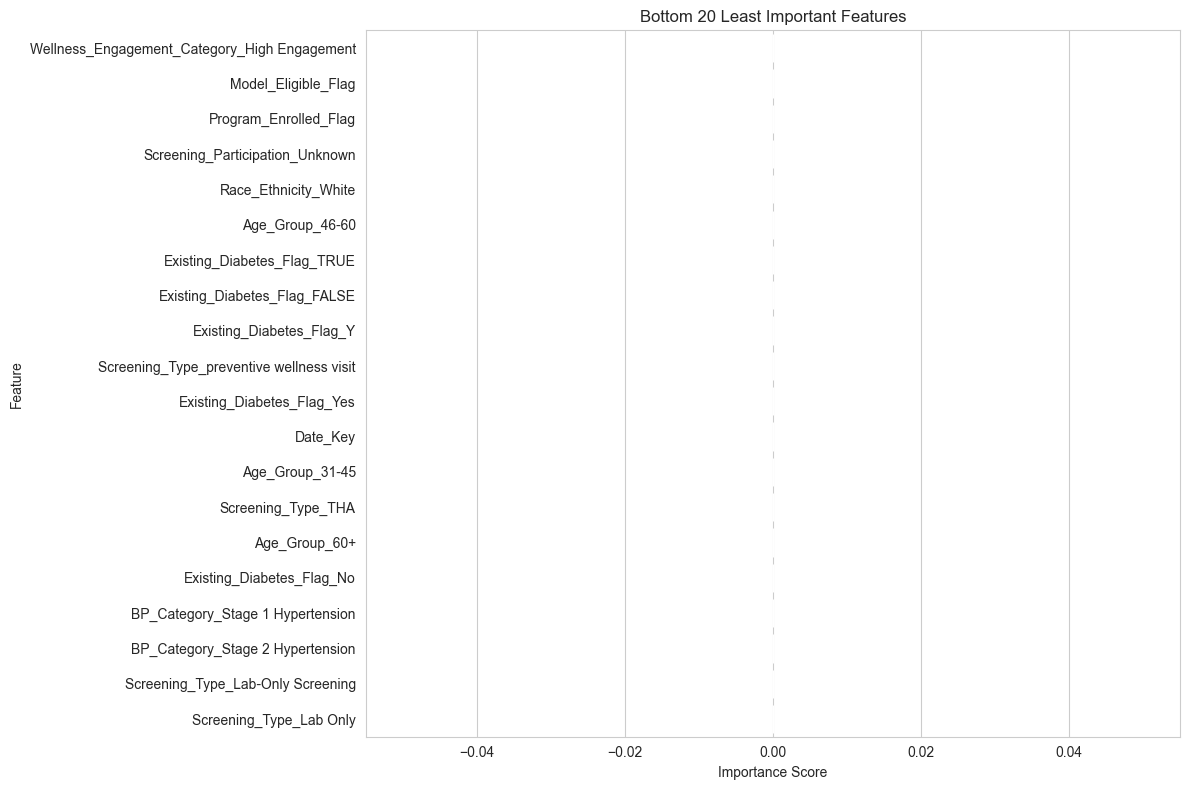

In [188]:
# =====================================================
# Least Important Features Visualization
# =====================================================

bottom_features = (

    dt_importance
    .sort_values(
        "Importance",
        ascending=True
    )
    .head(20)

)

plt.figure(figsize=(12,8))

sns.barplot(

    data=bottom_features,

    x="Importance",

    y="Feature",

    palette="Reds"

)

plt.title(
    "Bottom 20 Least Important Features"
)

plt.xlabel(
    "Importance Score"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()

plt.show()

In [189]:
# =====================================================
# Features With Very Low Importance
# =====================================================

low_importance_features = (

    dt_importance[
        dt_importance["Importance"] < 0.001
    ]

)

display(
    low_importance_features
)

print(
    "Number of Low Importance Features:",
    len(low_importance_features)
)

,Feature,Importance,Cumulative
2,SDOH_Vulnerability_Index,0.000996,0.988850
33,Costs,0.000881,0.989731
54,Region_Southern California,0.000747,0.990478
106,Existing_Diabetes_Flag_N,0.000746,0.991224
36,Smoking_Risk,0.000663,0.991887
3,Date_Key_x,0.000588,0.992474
97,Screening_Type_Preventive Wellness Visit,0.000571,0.993045
100,Screening_Type_annual physical,0.000563,0.993608
6,Exercise_Frequency,0.000550,0.994159
35,Wellness_Score,0.000516,0.994675


Number of Low Importance Features: 83


In [190]:
high_risk = member_level_df[
    member_level_df["Develops_Chronic_Disease_12M"] == 1
]

low_risk = member_level_df[
    member_level_df["Develops_Chronic_Disease_12M"] == 0
]

In [191]:
risk_profile = pd.DataFrame({

    "High Risk Avg": high_risk[[
        "Age",
        "BMI",
        "Glucose",
        "HbA1c",
        "Medications",
        "Chronic_Condition_Count"
    ]].mean(),

    "Low Risk Avg": low_risk[[
        "Age",
        "BMI",
        "Glucose",
        "HbA1c",
        "Medications",
        "Chronic_Condition_Count"
    ]].mean()

})

risk_profile

,High Risk Avg,Low Risk Avg
Age,58.494208,50.815560
BMI,30.161293,28.501051
Glucose,100.958494,95.478203
HbA1c,5.439093,5.260239
Medications,2.962355,2.096579
Chronic_Condition_Count,1.076255,0.634138


# MEMBER SEGMENTATION (CLUSTERING)

Can we group members into meaningful population segments?
Instead of Will this member develop disease?

In [192]:
cluster_features = [

    "Age",
    "BMI",
    "Glucose",
    "HbA1c",
    "Systolic_BP",
    "Diastolic_BP",
    "Medications",
    "Chronic_Condition_Count",
    "Costs",
    "Visits",
    "ER_Visits",
    "Hospital_Admissions",
    "Wellness_Score",
    "Lifestyle_Risk_Score"

]

In [193]:
from sklearn.preprocessing import StandardScaler

X_cluster = member_level_df[
    cluster_features
].copy()

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_cluster
)

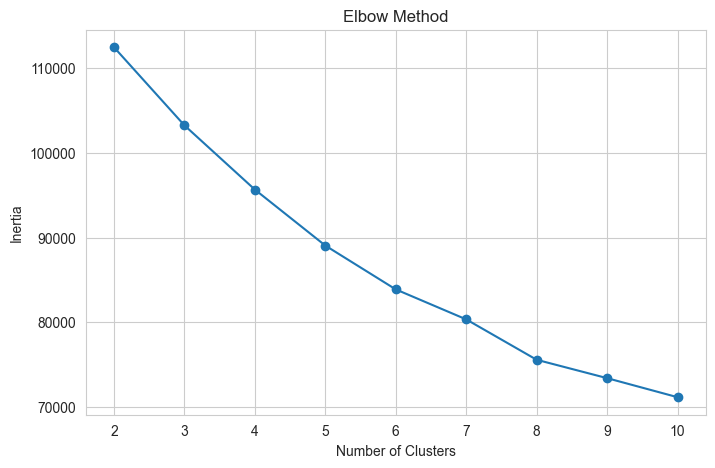

In [194]:
# Elbow method to determine optimal number of clusters

from sklearn.cluster import KMeans

inertia = []

for k in range(2,11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia.append(
        model.inertia_
    )

plt.figure(figsize=(8,5))

plt.plot(
    range(2,11),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters")

plt.ylabel("Inertia")

plt.title("Elbow Method")

plt.show()

In [195]:
# Silhouette Score to determine optimal number of clusters

from sklearn.metrics import silhouette_score

scores = []

for k in range(2,11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(
        X_scaled
    )

    score = silhouette_score(
        X_scaled,
        labels
    )

    scores.append(score)

pd.DataFrame({

    "Clusters": range(2,11),

    "Silhouette_Score": scores

})

,Clusters,Silhouette_Score
0,2,0.207200
1,3,0.148228
2,4,0.154540
3,5,0.156270
4,6,0.132903
5,7,0.110911
6,8,0.109723
7,9,0.107624
8,10,0.107255


In [196]:
# Cluster creation

optimal_k = 4

kmeans = KMeans(

    n_clusters=optimal_k,

    random_state=42,

    n_init=10

)

member_level_df["Cluster"] = (

    kmeans.fit_predict(
        X_scaled
    )

)

In [197]:
# Cluster profiling

cluster_profile = (

    member_level_df
    .groupby("Cluster")[

        cluster_features

    ]
    .mean()

)

display(
    cluster_profile.round(2)
)

,Age,BMI,Glucose,HbA1c,Systolic_BP,Diastolic_BP,Medications,Chronic_Condition_Count,Costs,Visits,ER_Visits,Hospital_Admissions,Wellness_Score,Lifestyle_Risk_Score
Cluster,,,,,,,,,,,,,,
0,66.31,33.23,125.75,6.30,130.29,79.92,4.66,1.74,7232.58,7.98,0.22,0.01,51.09,49.31
1,38.82,25.52,87.85,5.01,108.53,68.10,0.96,0.19,2297.86,3.74,0.14,0.00,49.78,24.21
2,58.48,30.14,93.38,5.18,128.60,79.98,2.48,0.77,3625.31,5.44,0.16,0.00,51.92,40.95
3,60.08,29.98,100.33,5.43,125.27,76.86,2.92,0.98,45323.70,5.99,0.12,1.05,50.72,41.74


In [198]:
member_level_df[
    "Cluster"
].value_counts()

Cluster
1    4091
2    3940
0    1404
3     547
Name: count, dtype: int64

In [199]:
from sklearn.cluster import AgglomerativeClustering

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

from scipy.cluster.hierarchy import (
    dendrogram,
    linkage
)

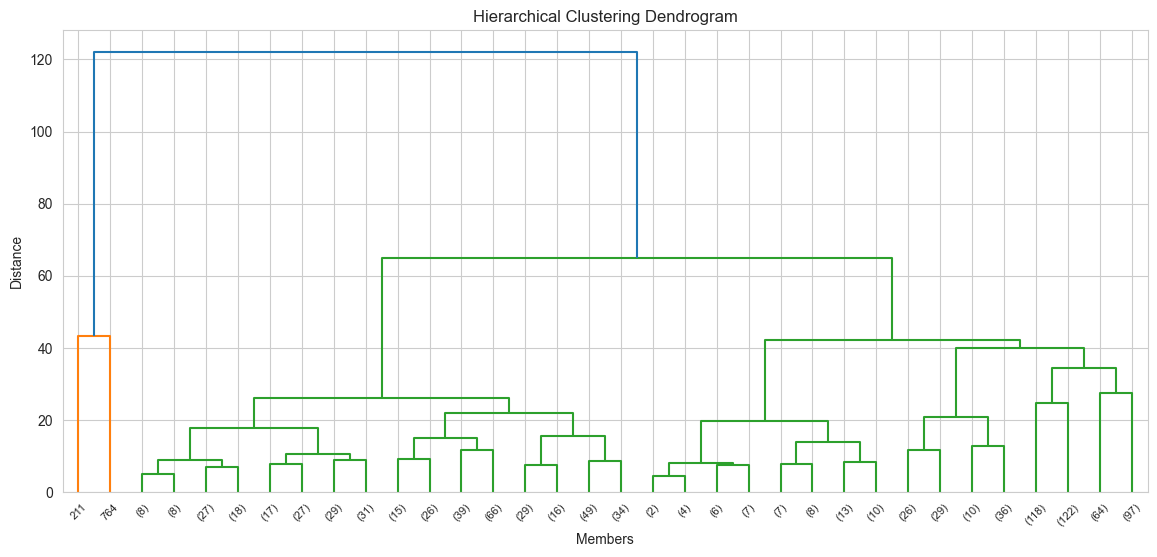

In [200]:
# =====================================================
# Hierarchical Clustering Dendrogram
# =====================================================

X_scaled_df = pd.DataFrame(X_scaled)

sample_df = X_scaled_df.sample(
    min(1000, len(X_scaled_df)),
    random_state=42
)

linked = linkage(
    sample_df,
    method='ward'
)

plt.figure(figsize=(14,6))

dendrogram(

    linked,

    truncate_mode='level',

    p=5

)

plt.title(
    "Hierarchical Clustering Dendrogram"
)

plt.xlabel(
    "Members"
)

plt.ylabel(
    "Distance"
)

plt.show()

In [201]:
# =====================================================
# Agglomerative Clustering
# =====================================================

hierarchical = AgglomerativeClustering(

    n_clusters=4,

    linkage='ward'

)

hier_cluster_labels = hierarchical.fit_predict(
    X_scaled
)

In [202]:
# =====================================================
# Hierarchical Metrics
# =====================================================

hier_silhouette = silhouette_score(

    X_scaled,

    hier_cluster_labels

)

hier_db = davies_bouldin_score(

    X_scaled,

    hier_cluster_labels

)

print(
    "Silhouette Score:",
    round(hier_silhouette,4)
)

print(
    "Davies-Bouldin Score:",
    round(hier_db,4)
)

Silhouette Score: 0.1507
Davies-Bouldin Score: 1.8652


In [203]:
hier_cluster_sizes = pd.Series(

    hier_cluster_labels

).value_counts()

display(
    hier_cluster_sizes
)

1    4674
0    3606
3    1138
2     564
Name: count, dtype: int64

In [204]:
member_level_df[
    "Hierarchical_Cluster"
] = hier_cluster_labels

In [205]:
hier_cluster_profile = (

    member_level_df

    .groupby(
        "Hierarchical_Cluster"
    )

    [

        [

            "Age",
            "BMI",
            "Glucose",
            "HbA1c",
            "Costs",
            "Visits",
            "Chronic_Condition_Count",
            "Lifestyle_Risk_Score"

        ]

    ]

    .mean()

)

display(
    hier_cluster_profile.round(2)
)

,Age,BMI,Glucose,HbA1c,Costs,Visits,Chronic_Condition_Count,Lifestyle_Risk_Score
Hierarchical_Cluster,,,,,,,,
0,61.49,31.41,105.62,5.60,4445.58,6.42,1.18,43.38
1,43.37,26.54,88.77,5.04,2162.66,4.11,0.27,28.07
2,60.00,30.07,101.39,5.47,44790.99,6.10,0.99,41.52
3,50.01,28.06,92.98,5.16,6353.02,4.76,0.62,36.39


In [206]:
# =====================================================
# Clustering Comparison
# =====================================================

kmeans_silhouette = silhouette_score(X_scaled, kmeans.labels_)
kmeans_db = davies_bouldin_score(X_scaled, kmeans.labels_)

cluster_comparison = pd.DataFrame({

    "Model": [

        "K-Means",

        "Hierarchical"

    ],

    "Silhouette": [

        kmeans_silhouette,

        hier_silhouette

    ],

    "Davies_Bouldin": [

        kmeans_db,

        hier_db

    ]

})

display(
    cluster_comparison.round(4)
)

,Model,Silhouette,Davies_Bouldin
0,K-Means,0.1545,1.8512
1,Hierarchical,0.1507,1.8652


In [207]:
best_cluster_model = (

    "K-Means"

    if kmeans_silhouette >

       hier_silhouette

    else

    "Hierarchical"

)

print(

    f"Best Segmentation Approach:"
    f" {best_cluster_model}"

)

Best Segmentation Approach: K-Means


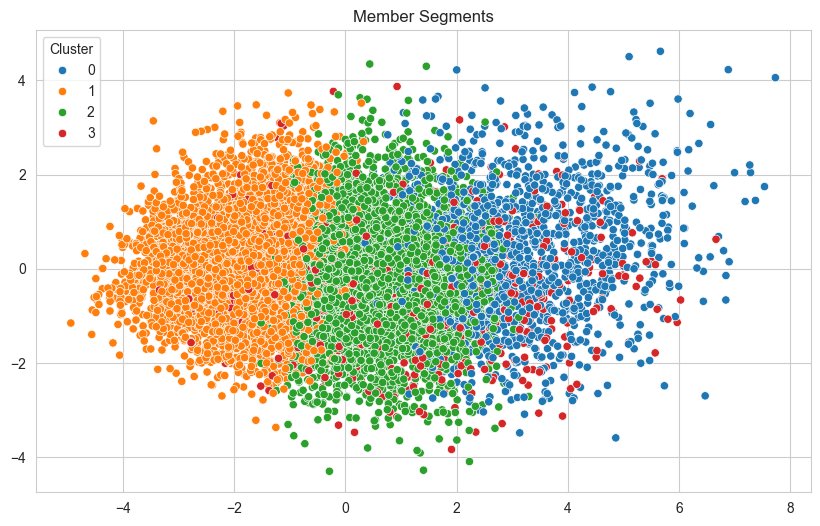

In [208]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

cluster_pca = pca.fit_transform(
    X_scaled
)

plt.figure(figsize=(10,6))

sns.scatterplot(

    x=cluster_pca[:,0],

    y=cluster_pca[:,1],

    hue=member_level_df["Cluster"],

    palette="tab10"

)

plt.title(
    "Member Segments"
)

plt.show()

# DEEP LEARNING

In [209]:
# =====================================================
# Deep Learning Dataset Preparation
# =====================================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_dl = scaler.fit_transform(
    X_train_smote
)

X_test_dl = scaler.transform(
    X_test
)

print("Train Shape:", X_train_dl.shape)
print("Test Shape :", X_test_dl.shape)

Train Shape: (28624, 123)
Test Shape : (1997, 123)


In [210]:
# =====================================================
# Deep Learning Libraries
# =====================================================

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (

    Dense,
    Dropout,
    BatchNormalization

)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import EarlyStopping

from itertools import product

from sklearn.metrics import (

    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score

)

print(tf.__version__)

2.21.0


In [211]:
import tensorflow as tf

def weighted_binary_crossentropy(
        weight_for_0=1.0,
        weight_for_1=5.0):

    def loss(y_true, y_pred):

        bce = tf.keras.backend.binary_crossentropy(
            y_true,
            y_pred
        )

        weights = (
            y_true * weight_for_1 +
            (1 - y_true) * weight_for_0
        )

        return bce * weights

    return loss

In [212]:
# =====================================================
# Neural Network Builder
# =====================================================

def build_dl_model(

    hidden_units,
    dropout_rate,
    learning_rate

):

    model = Sequential([

        Dense(

            hidden_units,

            activation="tanh",

            input_shape=(
                X_train_dl.shape[1],
            )

        ),

        BatchNormalization(),

        Dropout(
            dropout_rate
        ),

        Dense(

            hidden_units // 2,

            activation="tanh"

        ),

        Dense(

    len(
        disease_encoder.classes_
    ),

    activation="softmax"

)

    ])

    model.compile(

        optimizer=Adam(learning_rate=learning_rate
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]

    )

#     model.compile(

#     optimizer="adam",

#     loss=weighted_binary_crossentropy(
#         weight_for_0=1,
#         weight_for_1=5
#     ),

#     metrics=["accuracy"]

# )

    return model

In [213]:
# =====================================================
# Prevent Overfitting
# =====================================================

early_stop = EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True

)

In [214]:
# =====================================================
# Deep Learning Experiments
# =====================================================

units_grid = [

    64,
    128

]

dropout_grid = [

    0.20,
    0.30

]

learning_rate_grid = [

    0.001

]

dl_results = []

In [215]:
# =====================================================
# Run Experiments
# =====================================================

for units, dropout, lr in product(

    units_grid,
    dropout_grid,
    learning_rate_grid

):

    print(
        f"Running: Units={units}, "
        f"Dropout={dropout}, "
        f"LR={lr}"
    )

    model = build_dl_model(

        hidden_units=units,

        dropout_rate=dropout,

        learning_rate=lr

    )

    history = model.fit(

        X_train_dl,

        y_train_smote,

        validation_split=0.20,

        epochs=30,

        batch_size=32,

        callbacks=[early_stop],

        verbose=0

    )

    y_prob = model.predict(

        X_test_dl,

        verbose=0

    )

    y_pred = np.argmax(y_prob, axis=1)

    dl_results.append({

        "Units": units,

        "Dropout": dropout,

        "Learning_Rate": lr,

        "Accuracy":
            accuracy_score(
                y_test,
                y_pred
            ),

        "Precision":
            precision_score(
                y_test,
                y_pred,
                average = "weighted"
            ),

        "Recall":
            recall_score(
                y_test,
                y_pred,
                average = "weighted"
            ),

        "F1":
            f1_score(
                y_test,
                y_pred,
                average = "weighted"
            ),

        "ROC_AUC":
            roc_auc_score(
                y_test,
                y_prob,
                multi_class= "ovr",
                average = "weighted"
                
            )

    })

Running: Units=64, Dropout=0.2, LR=0.001


C:\Users\P295295\AppData\Roaming\Python\Python310\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Running: Units=64, Dropout=0.3, LR=0.001


C:\Users\P295295\AppData\Roaming\Python\Python310\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Running: Units=128, Dropout=0.2, LR=0.001


C:\Users\P295295\AppData\Roaming\Python\Python310\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Running: Units=128, Dropout=0.3, LR=0.001


C:\Users\P295295\AppData\Roaming\Python\Python310\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [216]:
# =====================================================
# Results Table
# =====================================================

dl_results = pd.DataFrame(
    dl_results
)

display(

    dl_results
    .sort_values(
        "Recall",
        ascending=False
    )
    .round(4)

)

,Units,Dropout,Learning_Rate,Accuracy,Precision,Recall,F1,ROC_AUC
0,64,0.2,0.001,0.9815,0.9797,0.9815,0.9805,0.9979
2,128,0.2,0.001,0.9805,0.9789,0.9805,0.9797,0.9985
3,128,0.3,0.001,0.9800,0.9798,0.9800,0.9798,0.9987
1,64,0.3,0.001,0.9755,0.9750,0.9755,0.9752,0.9973


In [217]:
# =====================================================
# Final Selected Deep Learning Model
# =====================================================

final_deep_nn = build_dl_model(

    hidden_units=128,

    dropout_rate=0.30,

    learning_rate=0.001

)

history = final_deep_nn.fit(

    X_train_dl,

    y_train_smote,

    validation_split=0.20,

    epochs=30,

    batch_size=32,

    callbacks=[early_stop],

    verbose=1

)

C:\Users\P295295\AppData\Roaming\Python\Python310\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
716/716 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.9409 - loss: 0.1724 - val_accuracy: 0.8454 - val_loss: 0.4178
Epoch 2/30
716/716 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9828 - loss: 0.0498 - val_accuracy: 0.8854 - val_loss: 0.2928
Epoch 3/30
716/716 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9869 - loss: 0.0366 - val_accuracy: 0.9474 - val_loss: 0.1411
Epoch 4/30
716/716 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9903 - loss: 0.0281 - val_accuracy: 0.9656 - val_loss: 0.1060
Epoch 5/30
716/716 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9912 - loss: 0.0240 - val_accuracy: 0.9516 - val_loss: 0.1361


In [218]:
# =====================================================
# Best Neural Network
# =====================================================

best_dl = (

    dl_results
    .sort_values(

        ["Recall", "ROC_AUC"],

        ascending=False

    )

    .head(1)

)

display(
    best_dl.round(4)
)

,Units,Dropout,Learning_Rate,Accuracy,Precision,Recall,F1,ROC_AUC
0,64,0.2,0.001,0.9815,0.9797,0.9815,0.9805,0.9979


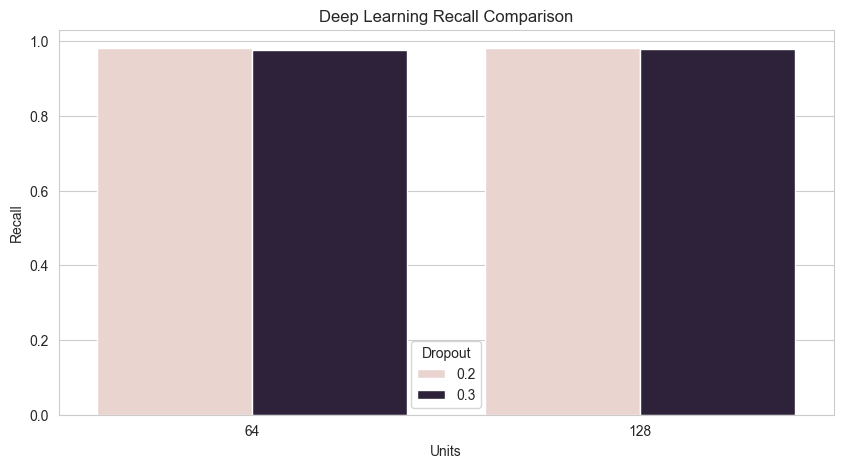

In [219]:
plt.figure(figsize=(10,5))

sns.barplot(

    data=dl_results,

    x="Units",

    y="Recall",

    hue="Dropout"

)

plt.title(
    "Deep Learning Recall Comparison"
)

plt.show()

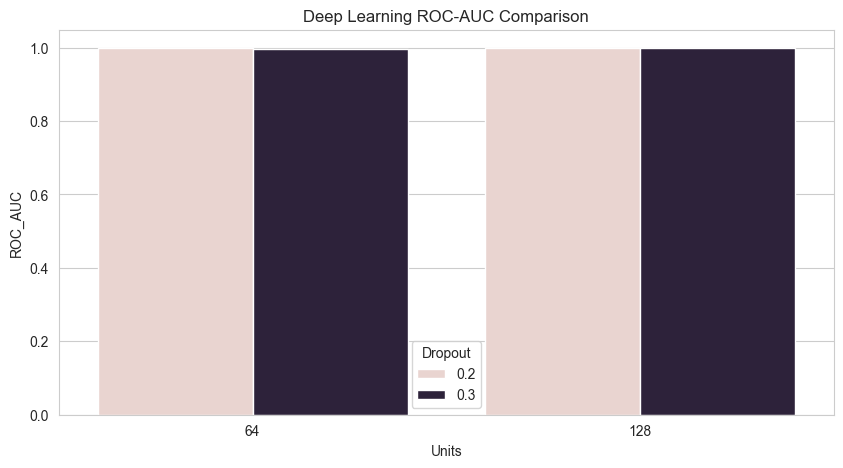

In [220]:
plt.figure(figsize=(10,5))

sns.barplot(

    data=dl_results,

    x="Units",

    y="ROC_AUC",

    hue="Dropout"

)

plt.title(
    "Deep Learning ROC-AUC Comparison"
)

plt.show()

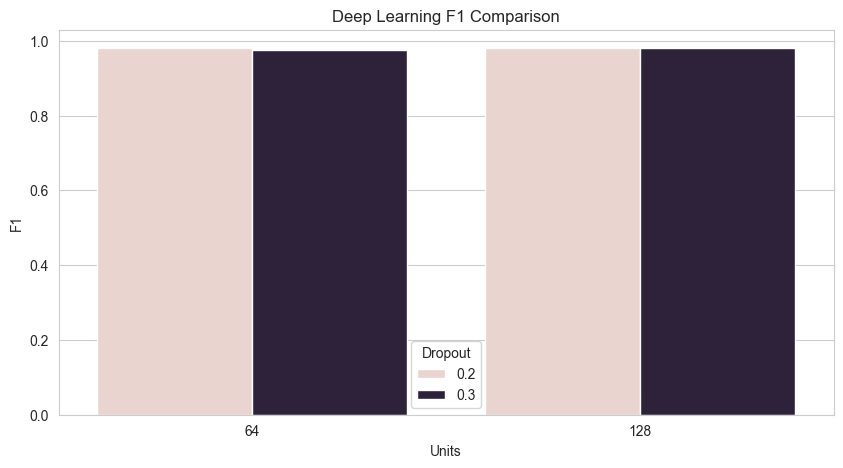

In [221]:
plt.figure(figsize=(10,5))

sns.barplot(

    data=dl_results,

    x="Units",

    y="F1",

    hue="Dropout"

)

plt.title(
    "Deep Learning F1 Comparison"
)

plt.show()

In [222]:
display(
    dl_results
    .sort_values(
        ["Recall","ROC_AUC"],
        ascending=False
    )
)

,Units,Dropout,Learning_Rate,Accuracy,Precision,Recall,F1,ROC_AUC
0,64,0.2,0.001,0.981472,0.979744,0.981472,0.980476,0.997863
2,128,0.2,0.001,0.980471,0.978894,0.980471,0.979680,0.998501
3,128,0.3,0.001,0.979970,0.979752,0.979970,0.979821,0.998667
1,64,0.3,0.001,0.975463,0.974993,0.975463,0.975214,0.997251


In [223]:
best_dl_final = best_dl.copy()

best_dl_final["Model"] = (
    "Deep Neural Network"
)

best_dl_final = best_dl_final[

    [

        "Model",

        "Accuracy",

        "Precision",

        "Recall",

        "F1",

        "ROC_AUC"

    ]

]

In [225]:
member_sample = X_test_dl[0:1]

risk_score = final_deep_nn.predict(
    member_sample,
    verbose=0
).flatten()[0]

print(
    f"Predicted Probability: {risk_score:.2%}"
)

Predicted Probability: 0.00%


In [229]:
final_ml_dl_comparison = pd.concat([

    final_model_comparison,

    best_dl_final

], ignore_index=True)

display(
    final_ml_dl_comparison
    .round(4)
)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,CV_Recall
0,Decision Tree,0.9835,0.9842,0.9835,0.9838,0.9935,NaN
1,XGBoost,0.9825,0.9826,0.9825,0.9825,0.9996,NaN
2,Random Forest,0.9805,0.9787,0.9805,0.9795,0.9994,NaN
3,Deep Neural Network,0.9815,0.9797,0.9815,0.9805,0.9979,NaN


In [230]:
final_ml_dl_comparison.to_csv(
    "model_comparison.csv",
    index=False
)

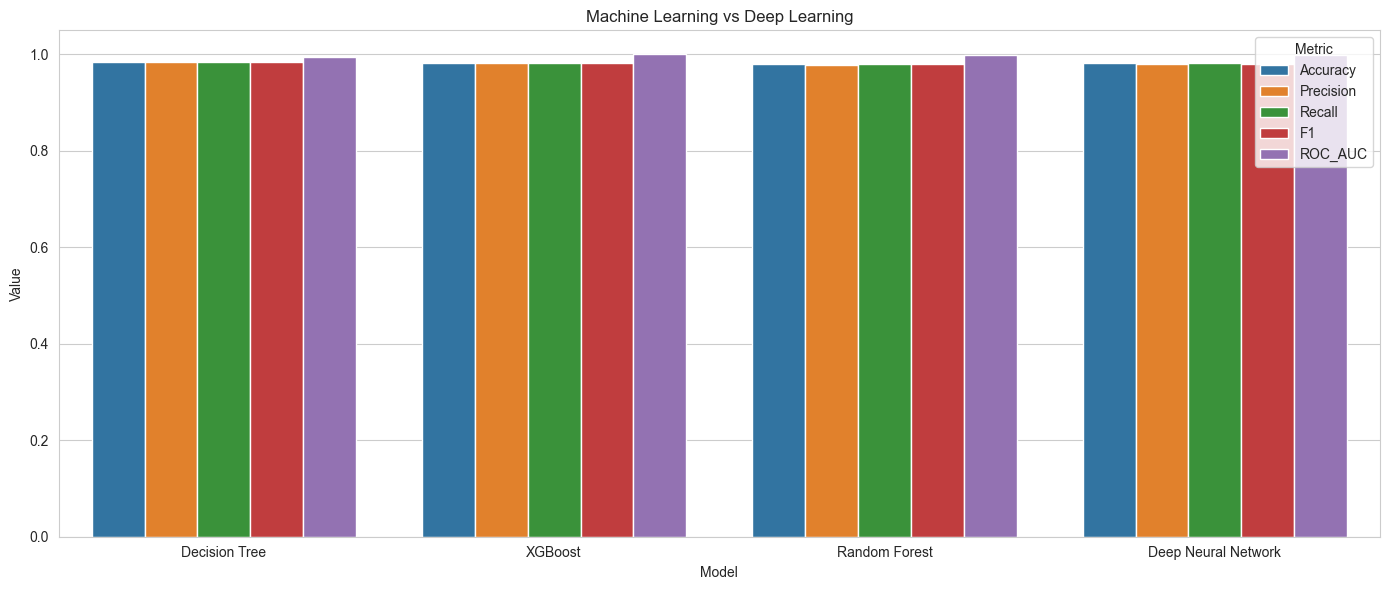

In [231]:
comparison_plot = final_ml_dl_comparison.melt(

    id_vars="Model",

    value_vars=[

        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC"

    ],

    var_name="Metric",

    value_name="Value"

)

plt.figure(figsize=(14,6))

sns.barplot(

    data=comparison_plot,

    x="Model",

    y="Value",

    hue="Metric"

)

plt.title(
    "Machine Learning vs Deep Learning"
)

plt.tight_layout()

plt.show()

# NEW NLP

In [232]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (

    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix

)

from sklearn.decomposition import LatentDirichletAllocation

import nltk

nltk.download("punkt")
nltk.download("stopwords")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\P295295\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\P295295\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [233]:
# =====================================================
# Load Dataset
# =====================================================

nlp_df = pd.read_csv("hospital.csv")

nlp_df = nlp_df.drop(
    columns=["Unnamed: 3"],
    errors="ignore"
)

print(nlp_df.shape)

display(nlp_df.head())

(996, 3)


,Feedback,Sentiment Label,Ratings
0,Good and clean hospital. There is great team o...,1,5
1,Had a really bad experience during discharge. ...,1,5
2,I have visited to take my second dose and Proc...,1,4
3,That person was slightly clueless and offered...,1,3
4,There is great team of doctors and good OT fac...,0,1


In [234]:
# =====================================================
# Correct Sentiment Labels
# =====================================================

def corrected_sentiment(rating):

    if rating <= 2:
        return "Negative"

    elif rating == 3:
        return "Neutral"

    else:
        return "Positive"

nlp_df["Corrected_Sentiment"] = (
    nlp_df["Ratings"]
    .apply(corrected_sentiment)
)

nlp_df[
    "Corrected_Sentiment"
].value_counts()

Corrected_Sentiment
Positive    605
Negative    268
Neutral     123
Name: count, dtype: int64

In [235]:
nlp_df

,Feedback,Sentiment Label,Ratings,Corrected_Sentiment
0,Good and clean hospital. There is great team o...,1,5,Positive
1,Had a really bad experience during discharge. ...,1,5,Positive
2,I have visited to take my second dose and Proc...,1,4,Positive
3,That person was slightly clueless and offered...,1,3,Neutral
4,There is great team of doctors and good OT fac...,0,1,Negative
...,...,...,...,...
991,very careful about safety measures every one i...,1,4,Positive
992,I do not trust in their reports I got same tes...,0,2,Negative
993,They just want the patients to return to their...,0,1,Negative
994,I suggest you not to visit this hospital if yo...,0,2,Negative


In [236]:
nlp_df["Corrected_Sentiment"].to_csv(

    "sentiment_distribution.csv",

    index=True

)

print(
    "sentiment_distribution.csv saved successfully."
)

sentiment_distribution.csv saved successfully.


In [237]:
# =====================================================
# Check Rating vs Sentiment
# =====================================================

comparision_ratings=pd.crosstab(

    nlp_df["Corrected_Sentiment"],

    nlp_df["Ratings"]

)

display(comparision_ratings)

Ratings,1,2,3,4,5
Corrected_Sentiment,,,,,
Negative,123,145,0,0,0
Neutral,0,0,123,0,0
Positive,0,0,0,254,351


In [238]:
comparision_ratings.to_csv(

    "ratings_sentiments.csv",

    index=True

)

print(
    "ratings_sentiments.csv saved successfully."
)

ratings_sentiments.csv saved successfully.


In [239]:
# =====================================================
# Clean Text
# =====================================================

def clean_text(text):

    text = str(text).lower()

    text = re.sub(
        r"[^a-zA-Z\\s]",
        " ",
        text
    )

    text = re.sub(
        r"\\s+",
        " ",
        text
    )

    return text.strip()

nlp_df["Clean_Feedback"] = (

    nlp_df["Feedback"]

    .apply(clean_text)

)

display(

    nlp_df[

        [

            "Feedback",

            "Clean_Feedback"

        ]

    ].head()

)

,Feedback,Clean_Feedback
0,Good and clean hospital. There is great team o...,good and clean hospital there is great team o...
1,Had a really bad experience during discharge. ...,had a really bad experience during discharge ...
2,I have visited to take my second dose and Proc...,i have visited to take my second dose and proc...
3,That person was slightly clueless and offered...,that person was slightly clueless and offered ...
4,There is great team of doctors and good OT fac...,there is great team of doctors and good ot fac...


In [240]:
# =====================================================
# Tokenization
# =====================================================

nlp_df["Tokens"] = (

    nlp_df["Clean_Feedback"]

    .apply(word_tokenize)

)

In [241]:
# =====================================================
# Remove Stopwords
# =====================================================

stop_words = set(
    stopwords.words("english")
)

nlp_df["Tokens_Clean"] = (

    nlp_df["Tokens"]

    .apply(

        lambda x:

        [

            word

            for word in x

            if word not in stop_words

        ]

    )

)

In [242]:
negative_reviews = nlp_df[

    nlp_df["Corrected_Sentiment"]
    == "Negative"

]

In [243]:
def complaint_category(text):

    text = str(text).lower()

    if any(word in text for word in
           ["appointment","schedule"]):

        return "Appointment Access"

    elif any(word in text for word in
             ["billing","charges","payment"]):

        return "Billing Issues"

    elif any(word in text for word in
             ["wait","waiting","delay"]):

        return "Waiting Time"

    elif any(word in text for word in
             ["emergency","er"]):

        return "Emergency Services"

    elif any(word in text for word in
             ["staff","nurse"]):

        return "Staff Experience"

    else:

        return "Other"

In [244]:
negative_reviews[
    "Complaint_Category"
] = (

    negative_reviews["Clean_Feedback"]

    .apply(
        complaint_category
    )

)

C:\Users\P295295\AppData\Local\Temp\ipykernel_13264\1688068176.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  negative_reviews[


In [245]:
complaint_summary = (

    negative_reviews

    ["Complaint_Category"]

    .value_counts()

    .reset_index()

)

complaint_summary.columns = [

    "Concern",

    "Count"

]

display(
    complaint_summary
)

,Concern,Count
0,Emergency Services,155
1,Other,40
2,Waiting Time,25
3,Appointment Access,25
4,Billing Issues,13
5,Staff Experience,10


In [246]:
complaint_summary.to_csv(

    "common_concerns.csv",

    index=False

)

In [247]:
# =====================================================
# TF-IDF
# =====================================================

tfidf = TfidfVectorizer(

    stop_words="english",

    max_features=100

)

X_tfidf = tfidf.fit_transform(
    nlp_df["Clean_Feedback"]
)

feature_names = tfidf.get_feature_names_out()

scores = np.asarray(
    X_tfidf.mean(axis=0)
).ravel()

tfidf_df = pd.DataFrame({

    "Word": feature_names,

    "Importance": scores

})

tfidf_df = tfidf_df.sort_values(

    "Importance",

    ascending=False

)

display(
    tfidf_df.head(20)
)

,Word,Importance
39,hospital,0.104309
31,good,0.088543
80,staff,0.063446
19,dr,0.056590
22,experience,0.052561
76,service,0.052219
17,doctors,0.048372
16,doctor,0.047793
93,treatment,0.045104
63,patient,0.043676


In [248]:
# =====================================================
# Positive Keywords
# =====================================================

positive_reviews = nlp_df[
    nlp_df["Corrected_Sentiment"] == "Positive"
]

In [249]:
positive_tfidf = TfidfVectorizer(

    stop_words="english",

    max_features= 20

)

positive_matrix = positive_tfidf.fit_transform(

    positive_reviews["Clean_Feedback"]

)

positive_words = pd.DataFrame({

    "Word":
        positive_tfidf.get_feature_names_out(),

    "Score":
        np.asarray(
            positive_matrix.mean(axis=0)
        ).ravel()

})

positive_words.sort_values(
    "Score",
    ascending=False
)

,Word,Score
10,hospital,0.164307
7,good,0.158022
4,dr,0.123585
15,staff,0.105668
13,service,0.087701
6,experience,0.081371
1,care,0.081205
19,treatment,0.081141
3,doctors,0.075827
2,doctor,0.067222


In [250]:
neutral_reviews = nlp_df[
    nlp_df["Corrected_Sentiment"] == "Neutral"
]

In [251]:
neutral_tfidf = TfidfVectorizer(

    stop_words="english",

    max_features=20

)

neutral_matrix = neutral_tfidf.fit_transform(

    neutral_reviews["Clean_Feedback"]

)

neutral_words = pd.DataFrame({

    "Word":
        neutral_tfidf.get_feature_names_out(),

    "Score":
        np.asarray(
            neutral_matrix.mean(axis=0)
        ).ravel()

})

neutral_words.sort_values(
    "Score",
    ascending=False
)

,Word,Score
9,hospital,0.173958
8,good,0.118688
5,doctors,0.115042
16,staff,0.093676
14,service,0.086064
4,doctor,0.072061
12,parking,0.067761
11,management,0.062579
18,time,0.062168
19,treatment,0.049431


In [252]:
neutral_words.to_csv(

    "neutral_drivers.csv",

    index=True

)

print(
    "neutral_drivers.csv saved successfully."
)

neutral_drivers.csv saved successfully.


In [253]:
negative_reviews = nlp_df[
    nlp_df["Corrected_Sentiment"] == "Negative"
]

In [254]:
negative_tfidf = TfidfVectorizer(

    stop_words="english",

    max_features=20

)

negative_matrix = negative_tfidf.fit_transform(

    negative_reviews["Clean_Feedback"]

)

negative_words = pd.DataFrame({

    "Word":
        negative_tfidf.get_feature_names_out(),

    "Score":
        np.asarray(
            negative_matrix.mean(axis=0)
        ).ravel()

})

negative_words.sort_values(
    "Score",
    ascending=False
)

,Word,Score
9,hospital,0.181948
19,worst,0.125009
16,staff,0.103297
12,patient,0.086552
7,experience,0.082892
3,doctor,0.075722
13,patients,0.062366
6,emergency,0.061072
5,don,0.060495
17,time,0.057905


# TOPIC MODELING


In [255]:
# =====================================================
# Topic Modeling
# =====================================================

lda = LatentDirichletAllocation(

    n_components=5,

    random_state=42

)

lda.fit(X_tfidf)

feature_names = tfidf.get_feature_names_out()

for topic_idx, topic in enumerate(
    lda.components_
):

    print(
        f"\nTopic {topic_idx+1}"
    )

    print(

        ", ".join(

            [

                feature_names[i]

                for i in topic.argsort()[-100:]

            ]

        )

    )


Topic 1
nice, sir, caring, thanks, staffs, manipal, polite, helped, experienced, treated, lab, issues, fortis, smooth, happy, job, friendly, maintained, facilities, satisfied, nursing, tests, people, room, process, dr, surgery, checkup, parking, department, taken, thank, helpful, given, team, great, food, health, aster, help, did, went, management, treatment, best, really, visited, consultation, insurance, father, amazing, visit, support, good, better, professional, money, lot, overall, kind, extremely, reception, took, service, doctors, worst, issue, admitted, clean, hospitality, ward, appointment, excellent, test, nurses, services, like, emergency, care, doctor, come, got, medical, hours, experience, staff, hospitals, billing, rude, time, just, bad, recommend, wait, hospital, don, provided, nu, patient, patients

Topic 2
wait, just, visit, better, lab, bad, manipal, don, appointment, emergency, people, hours, reception, worst, process, billing, rude, parking, issue, smooth, room, lo

In [256]:
topic_mapping = {

    1: "Billing & Administration",

    2: "Service Quality & Doctors",

    3: "Emergency Services & Wait Time",

    4: "Clinical Care & Surgery",

    5: "Appointment Scheduling & Access"

}

In [257]:
def predict_topic(review):

    cleaned = clean_text(
        review
    )

    vector = tfidf.transform(
        [cleaned]
    )

    topic_probs = lda.transform(
        vector
    )

    topic_id = (
        topic_probs.argmax()
        + 1
    )

    print(
        "Assigned Topic:"
    )

    print(
        topic_mapping[
            topic_id
        ]
    )

In [258]:
predict_topic(

    "Billing charges were confusing."

)

Assigned Topic:
Billing & Administration


In [259]:
predict_topic(

    "The doctors and nurses were excellent."

)

Assigned Topic:
Emergency Services & Wait Time


In [260]:
predict_topic(

    "The knee surgery was well performed and comfortable dicharge."

)

Assigned Topic:
Clinical Care & Surgery


# SENTIMENT MODEL

In [261]:
sentiment_encoder = LabelEncoder()

y_sentiment = sentiment_encoder.fit_transform(

    nlp_df["Corrected_Sentiment"]

)

print(
    sentiment_encoder.classes_
)

['Negative' 'Neutral' 'Positive']


In [262]:
X_train,
X_test,
y_train,
y_test = train_test_split(

    nlp_df["Clean_Feedback"],

    y_sentiment,

    test_size=0.20,

    random_state=42,

    stratify=y_sentiment

)

In [263]:
tfidf_model = TfidfVectorizer(

    stop_words="english",

    max_features=2000

)

X_train_tfidf = tfidf_model.fit_transform(
    X_train
)

X_test_tfidf = tfidf_model.transform(
    X_test
)

In [264]:
sentiment_model = LogisticRegression(

    class_weight="balanced",

    max_iter=5000,

    random_state=42

)

X_train, X_test, y_train, y_test = train_test_split(
    nlp_df["Clean_Feedback"],
    y_sentiment,
    test_size=0.20,
    random_state=42,
    stratify=y_sentiment
)

X_train_tfidf = tfidf_model.fit_transform(X_train)
X_test_tfidf = tfidf_model.transform(X_test)

sentiment_model = LogisticRegression(
    class_weight="balanced",
    max_iter=5000,
    random_state=42
)

sentiment_model.fit(X_train_tfidf, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,5000
,multi_class,'deprecated'


In [265]:
pred_lr = sentiment_model.predict(
    X_test_tfidf
)

print(

    classification_report(

        y_test,

        pred_lr,

        target_names=
            sentiment_encoder.classes_

    )

)



              precision    recall  f1-score   support

    Negative       0.75      0.81      0.78        54
     Neutral       0.57      0.48      0.52        25
    Positive       0.90      0.89      0.90       121

    accuracy                           0.82       200
   macro avg       0.74      0.73      0.73       200
weighted avg       0.82      0.82      0.82       200



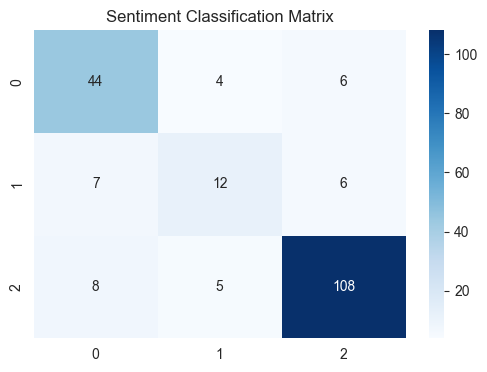

In [266]:
cm = confusion_matrix(
    y_test,
    pred_lr
)

plt.figure(figsize=(6,4))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues"

)

plt.title(
    "Sentiment Classification Matrix"
)

plt.show()

# CNN model

In [267]:
# =====================================================
# CNN Sentiment Model
# =====================================================

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 5000
MAX_LEN = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(
    nlp_df["Clean_Feedback"]
)

X_sequences = tokenizer.texts_to_sequences(
    nlp_df["Clean_Feedback"]
)

X_padded = pad_sequences(

    X_sequences,

    maxlen=MAX_LEN,

    padding="post"

)

In [268]:
# Split data

X_train_cnn,\
X_test_cnn,\
y_train_cnn,\
y_test_cnn = train_test_split(

    X_padded,

    y_sentiment,

    test_size=0.20,

    random_state=42,

    stratify=y_sentiment

)

In [269]:
# CNN Architecture

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (

    Embedding,
    Conv1D,
    GlobalMaxPooling1D,
    Dense,
    Dropout

)

cnn_model = Sequential([

    Embedding(

        input_dim=MAX_WORDS,

        output_dim= 128,

        input_length=MAX_LEN

    ),

    Conv1D(

        filters=128,

        kernel_size=3,

        activation="relu"

    ),

    GlobalMaxPooling1D(),

    Dropout(0.20),

    Dense(
        64,
        activation="relu"
    ),

    Dense(
        3,
        activation="softmax"
    )

])

C:\Users\P295295\AppData\Roaming\Python\Python310\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [270]:
# Compile

cnn_model.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

In [271]:
# Train

history = cnn_model.fit(

    X_train_cnn,

    y_train_cnn,

    validation_split=0.20,

    epochs=20,

    batch_size=32,

    verbose=1

)

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.6148 - loss: 0.9674 - val_accuracy: 0.5813 - val_loss: 0.9211
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.6148 - loss: 0.8280 - val_accuracy: 0.5813 - val_loss: 0.8304
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.6918 - loss: 0.6827 - val_accuracy: 0.7250 - val_loss: 0.6942
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.8365 - loss: 0.4802 - val_accuracy: 0.7563 - val_loss: 0.5889
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.8726 - loss: 0.3200 - val_accuracy: 0.7625 - val_loss: 0.5859
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.9245 - loss: 0.2154 - val_accuracy: 0.8000 - val_loss: 0.5605
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.9733 - loss: 0.1346 - val_accuracy: 0.7375 - val_loss: 0.6669
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9796 - loss: 0.0909 - val_accuracy: 0.7750 - v

In [272]:
# Evaluate CNN model

cnn_probs = cnn_model.predict(
    X_test_cnn
)

cnn_pred = cnn_probs.argmax(
    axis=1
)

1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/stepWARNING:tensorflow:5 out of the last 71 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x00000158DFA423B0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


In [273]:
cnn_results = {

    "Model":
        "Embedding + CNN",

    "Accuracy":
        accuracy_score(
            y_test_cnn,
            cnn_pred
        ),

    "Precision":
        precision_score(
            y_test_cnn,
            cnn_pred,
            average="weighted"
        ),

    "Recall":
        recall_score(
            y_test_cnn,
            cnn_pred,
            average="weighted"
        ),

    "F1":
        f1_score(
            y_test_cnn,
            cnn_pred,
            average="weighted"
        )

}

In [274]:
# NLP model Comparision
logistic_results = {

    "Model":
        "TF-IDF + Logistic Regression",

    "Accuracy":
        accuracy_score(
            y_test,
            pred_lr
        ),

    "Precision":
        precision_score(
            y_test,
            pred_lr,
            average="weighted"
        ),

    "Recall":
        recall_score(
            y_test,
            pred_lr,
            average="weighted"
        ),

    "F1":
        f1_score(
            y_test,
            pred_lr,
            average="weighted"
        )

}

In [275]:
nlp_model_comparison = pd.DataFrame([

    logistic_results,

    cnn_results

])

display(
    nlp_model_comparison.round(4)
)

,Model,Accuracy,Precision,Recall,F1
0,TF-IDF + Logistic Regression,0.82,0.8173,0.82,0.8177
1,Embedding + CNN,0.84,0.8364,0.84,0.8319


In [276]:
# =====================================================
# Test New Reviews
# =====================================================

def predict_sentiment(review):

    clean_review = clean_text(
        review
    )

    vector = tfidf_model.transform(
        [clean_review]
    )

    pred = sentiment_model.predict(
        vector
    )

    probs = sentiment_model.predict_proba(
        vector
    )[0]

    sentiment = (
        sentiment_encoder
        .inverse_transform(
            pred
        )[0]
    )

    print("="*60)

    print("Review")

    print("="*60)

    print(review)

    print("\nPredicted Sentiment:")

    print(sentiment)

    print(
        "\nConfidence:",
        round(
            max(probs)*100,
            2
        ),
        "%"
    )

    display(

        pd.DataFrame({

            "Sentiment":
                sentiment_encoder.classes_,

            "Probability":
                probs

        })

        .sort_values(
            "Probability",
            ascending=False
        )

    )

In [277]:
predict_sentiment(

    "Doctors were excellent and treatment quality was outstanding."

)

Review
Doctors were excellent and treatment quality was outstanding.

Predicted Sentiment:
Positive

Confidence: 60.9 %


,Sentiment,Probability
2,Positive,0.609022
1,Neutral,0.234173
0,Negative,0.156805


In [278]:
predict_sentiment(

    "Waiting time was very long and billing process was confusing."

)

Review
Waiting time was very long and billing process was confusing.

Predicted Sentiment:
Negative

Confidence: 56.75 %


,Sentiment,Probability
0,Negative,0.567539
1,Neutral,0.299289
2,Positive,0.133172


In [279]:
predict_sentiment(

    "Waiting time was very long and billing process was confusing."

)

Review
Waiting time was very long and billing process was confusing.

Predicted Sentiment:
Negative

Confidence: 56.75 %


,Sentiment,Probability
0,Negative,0.567539
1,Neutral,0.299289
2,Positive,0.133172


In [280]:
predict_sentiment("The overall experience was average and acceptable")

Review
The overall experience was average and acceptable

Predicted Sentiment:
Neutral

Confidence: 42.49 %


,Sentiment,Probability
1,Neutral,0.424927
2,Positive,0.393157
0,Negative,0.181916


In [281]:
# =====================================================
# Predict Sentiment Using CNN
# =====================================================

def predict_sentiment_cnn(review):

    # ---------------------------------------------
    # Clean incoming review
    # ---------------------------------------------
    clean_review = clean_text(review)

    # ---------------------------------------------
    # Convert review to sequence
    # ---------------------------------------------
    sequence = tokenizer.texts_to_sequences(
        [clean_review]
    )

    # ---------------------------------------------
    # Pad sequence
    # ---------------------------------------------
    padded = pad_sequences(

        sequence,

        maxlen=MAX_LEN,

        padding="post"

    )

    # ---------------------------------------------
    # Predict probabilities
    # ---------------------------------------------
    probs = cnn_model.predict(
        padded,
        verbose=0
    )[0]

    # ---------------------------------------------
    # Predicted class
    # ---------------------------------------------
    pred_class = np.argmax(probs)

    sentiment = (
        sentiment_encoder
        .inverse_transform(
            [pred_class]
        )[0]
    )

    # ---------------------------------------------
    # Output
    # ---------------------------------------------
    print("=" * 70)
    print("REVIEW")
    print("=" * 70)
    print(review)

    print("\nPredicted Sentiment:")
    print(sentiment)

    print(
        f"\nConfidence: {max(probs) * 100:.2f}%"
    )

    probability_table = pd.DataFrame({

        "Sentiment":
            sentiment_encoder.classes_,

        "Probability (%)":
            (probs * 100).round(2)

    })

    display(

        probability_table

        .sort_values(

            "Probability (%)",

            ascending=False

        )

    )

    return sentiment

In [282]:
predict_sentiment_cnn("The overall experience was average and acceptable.")

REVIEW
The overall experience was average and acceptable.

Predicted Sentiment:
Positive

Confidence: 96.92%


,Sentiment,Probability (%)
2,Positive,96.919998
1,Neutral,3.070000
0,Negative,0.010000


'Positive'

In [283]:
cnn_probs = cnn_model.predict(
    X_test_cnn
)

cnn_pred = np.argmax(
    cnn_probs,
    axis=1
)

print(

    classification_report(

        y_test_cnn,

        cnn_pred,

        target_names=
            sentiment_encoder.classes_

    )

)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
              precision    recall  f1-score   support

    Negative       0.88      0.67      0.76        54
     Neutral       0.59      0.52      0.55        25
    Positive       0.87      0.98      0.92       121

    accuracy                           0.84       200
   macro avg       0.78      0.72      0.74       200
weighted avg       0.84      0.84      0.83       200



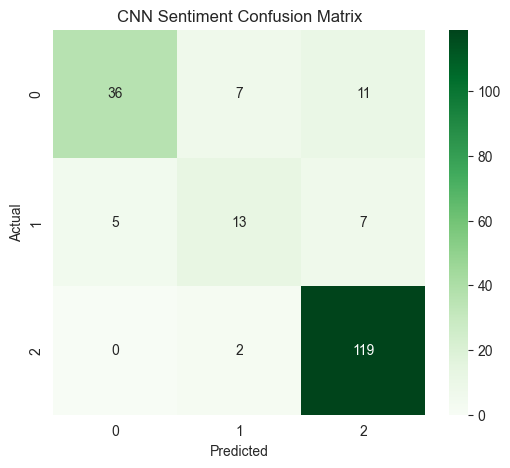

In [284]:
cm = confusion_matrix(
    y_test_cnn,
    cnn_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Greens"

)

plt.title(
    "CNN Sentiment Confusion Matrix"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.show()

# NLP ENDED

In [285]:
print(member_level_df.shape)

print(member_level_df["Develops_Chronic_Disease_12M"].value_counts())

print(member_level_df["Develops_Chronic_Disease_12M"].value_counts(normalize=True)*100)

(9982, 88)
Develops_Chronic_Disease_12M
0.0    8946
1.0    1036
Name: count, dtype: int64
Develops_Chronic_Disease_12M
0.0    89.621318
1.0    10.378682
Name: proportion, dtype: float64


In [286]:
# Member Analytics Table

powerbi_members = member_level_df.copy()

powerbi_members["Cluster"] = labels

powerbi_members["Cluster_Name"] = powerbi_members["Cluster"].map({

    0: "High-Risk Chronic Members",
    1: "Healthy Low-Risk Members",
    2: "Emerging Risk Members",
    3: "High-Cost Utilization Members"

})

In [287]:
# Adding risk categories

powerbi_members["Risk_Category"] = np.where(

    powerbi_members[
        "Develops_Chronic_Disease_12M"
    ] == 1,

    "High Risk",

    "Low Risk"

)

In [288]:
powerbi_members.to_csv(
    "powerbi_members.csv",
    index=False
)

In [289]:
# Creating clustering dimension for analysis

cluster_dimension = pd.DataFrame({

    "Cluster":[0,1,2,3],

    "Cluster_Name":[

        "High-Risk Chronic Members",

        "Healthy Low-Risk Members",

        "Emerging Risk Members",

        "High-Cost Utilization Members"

    ]

})

In [290]:
cluster_dimension.to_csv(
    "dim_cluster.csv",
    index=False
)

In [291]:
# Topic Naming

topic_dimension = pd.DataFrame({

    "Topic_ID":[1,2,3,4,5],

    "Topic_Name":[

        "Billing & Administration",

        "Service Quality & Doctors",

        "Emergency Services & Wait Time",

        "Clinical Care & Surgery",

        "Appointment Scheduling & Access"

    ]

})

topic_dimension.to_csv(
    "dim_topic.csv",
    index=False
)

In [292]:
powerbi_feedback = nlp_df.copy()



In [293]:
topic_probabilities = lda.transform(
    tfidf.transform(powerbi_feedback["Clean_Feedback"])
)

powerbi_feedback["Topic_ID"] = (
    topic_probabilities.argmax(axis=1) + 1
)

powerbi_feedback["Topic_Name"] = (
    powerbi_feedback["Topic_ID"]
    .map(topic_dimension.set_index("Topic_ID")["Topic_Name"])
)

powerbi_feedback.to_csv(
    "powerbi_feedback.csv",
    index=False
)

# important files/ tables 

In [294]:
# Feature Importance table 

feature_importance_powerbi = (
    dt_importance
    .head(15)
)

In [295]:
feature_importance_powerbi.to_csv(
    "feature_importance.csv",
    index=False
)

In [296]:
sample = {

    "Age": 65,

    "BMI": 34,

    "Glucose": 135,

    "HbA1c": 6.8,

    "Systolic_BP": 145,

    "Exercise_Frequency": 1,

    "Chronic_Condition_Count": 2,

    "Medications": 5

}

In [297]:
member_level_df[[
    "Develops_Diabetes_12M",
    "Develops_Hypertension_12M",
    "Develops_Chronic_Disease_12M"
]].sum()

Develops_Diabetes_12M            461.0
Develops_Hypertension_12M        600.0
Develops_Chronic_Disease_12M    1036.0
dtype: float64

In [298]:
for col in [

    "Develops_Diabetes_12M",
    "Develops_Hypertension_12M"

]:

    print("\n", col)

    print(
        member_level_df[col]
        .value_counts(normalize=True)
        * 100
    )


 Develops_Diabetes_12M
Develops_Diabetes_12M
0    95.381687
1     4.618313
Name: proportion, dtype: float64

 Develops_Hypertension_12M
Develops_Hypertension_12M
0    93.989181
1     6.010819
Name: proportion, dtype: float64


In [299]:
# =====================================================
# Recommended Wellness Campaign Assignment
# =====================================================

def recommend_campaign(row):

    # High glucose / diabetes-related risk
    if (
        row["Glucose"] >= 110
        or row["HbA1c"] >= 5.7
    ):
        return "Diabetes Prevention Program"

    # Older population
    elif row["Age"] >= 60:
        return "Healthy Aging Program"

    # Obesity / weight management
    elif row["BMI"] >= 30:
        return "Weight Management Program"

    # Lifestyle related risk
    elif row["Lifestyle_Risk_Score"] >= 40:
        return "Active Lifestyle Initiative"

    # Chronic disease burden
    elif row["Chronic_Condition_Count"] >= 2:
        return "Care Management Program"

    # Blood pressure risk
    elif row["Systolic_BP"] >= 130:
        return "Hypertension Awareness Program"

    else:
        return "General Wellness Program"


member_level_df["Recommended_Wellness_Campaign"] = (

    member_level_df.apply(
        recommend_campaign,
        axis=1
    )

)

In [300]:
# =====================================================
# Add Business Friendly Cluster Names
# =====================================================

cluster_mapping = {

    0: "High-Risk Chronic Members",

    1: "Healthy Low-Risk Members",

    2: "Emerging Risk Members",

    3: "High-Cost Utilization Members"

}

member_level_df["Cluster_Name"] = (
    member_level_df["Cluster"]
    .map(cluster_mapping)
)

member_level_df[
    ["Cluster", "Cluster_Name"]
].head()

,Cluster,Cluster_Name
0,1,Healthy Low-Risk Members
1,1,Healthy Low-Risk Members
2,2,Emerging Risk Members
3,2,Emerging Risk Members
4,1,Healthy Low-Risk Members


In [301]:
# =====================================================
# Disease Probability Breakdown
# =====================================================

prob_df = pd.DataFrame(

    probabilities,

    columns=disease_encoder.classes_

)

display(
    prob_df.head(10)
)

,Both,Diabetes,Hypertension,None
0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,1.0
2,0.0,0.0,0.0,1.0
3,0.0,0.0,0.0,1.0
4,0.0,0.0,0.0,1.0
5,0.0,0.0,1.0,0.0
6,0.0,0.0,0.0,1.0
7,0.0,0.0,0.0,1.0
8,0.0,0.0,0.0,1.0
9,0.0,0.0,0.0,1.0


In [302]:
# =====================================================
# Prediction Output Dataset
# =====================================================

all_predictions = final_decision_tree.predict(
    X
)

all_prediction_labels = (
    disease_encoder.inverse_transform(
        all_predictions
    )
)

prediction_output = pd.DataFrame({

    "Member_ID":
        member_level_df["Member_ID"],

    "Age":
        member_level_df["Age"],

    "BMI":
        member_level_df["BMI"],

    "Glucose":
        member_level_df["Glucose"],

    "HbA1c":
        member_level_df["HbA1c"],

    "Cluster_Name":
        member_level_df["Cluster_Name"],

    "Recommended_Wellness_Campaign":
        member_level_df[
            "Recommended_Wellness_Campaign"
        ],

    "Predicted_Disease":
        all_prediction_labels

})

display(
    prediction_output.head(100)
)

,Member_ID,Age,BMI,Glucose,HbA1c,Cluster_Name,Recommended_Wellness_Campaign,Predicted_Disease
0,KPM06309,51.0,31.6,98.0,5.6,Healthy Low-Risk Members,Weight Management Program,None
1,KPM05351,20.0,18.8,88.0,4.9,Healthy Low-Risk Members,General Wellness Program,None
2,KPM02008,62.0,26.9,90.0,5.2,Emerging Risk Members,Healthy Aging Program,None
3,KPM04803,72.0,25.1,90.0,4.9,Emerging Risk Members,Healthy Aging Program,None
4,KPM09903,30.0,44.2,98.0,5.2,Healthy Low-Risk Members,Weight Management Program,None
5,KPM05350,31.0,27.5,87.0,5.4,Healthy Low-Risk Members,General Wellness Program,None
6,KPM05973,52.0,27.8,97.0,5.6,High-Risk Chronic Members,Care Management Program,None
7,KPM06965,42.0,30.3,112.0,5.9,Healthy Low-Risk Members,Diabetes Prevention Program,None
8,KPM04958,53.0,23.6,90.0,4.8,Healthy Low-Risk Members,General Wellness Program,None
9,KPM04766,57.0,33.8,80.0,4.5,Healthy Low-Risk Members,Weight Management Program,None


In [303]:
# =====================================================
# Disease Prediction Output Dataset
# =====================================================

prediction_output = pd.DataFrame({

    "Member_ID":
        member_level_df["Member_ID"],

    "Age":
        member_level_df["Age"],

    "Gender":
        member_level_df["Gender"],

    "Region":
        member_level_df["Region"],

    "BMI":
        member_level_df["BMI"],

    "Glucose":
        member_level_df["Glucose"],

    "HbA1c":
        member_level_df["HbA1c"],

    "Systolic_BP":
        member_level_df["Systolic_BP"],

    "Chronic_Condition_Count":
        member_level_df["Chronic_Condition_Count"],

    "Cluster_Name":
        member_level_df["Cluster_Name"],

    "Recommended_Wellness_Campaign":
        member_level_df["Recommended_Wellness_Campaign"],

    "Predicted_Disease":
        all_prediction_labels

})

display(
    prediction_output.head(100)
)

,Member_ID,Age,Gender,Region,BMI,Glucose,HbA1c,Systolic_BP,Chronic_Condition_Count,Cluster_Name,Recommended_Wellness_Campaign,Predicted_Disease
0,KPM06309,51.0,Male,Nevada,31.6,98.0,5.6,109.0,0.0,Healthy Low-Risk Members,Weight Management Program,None
1,KPM05351,20.0,Female,Southern California,18.8,88.0,4.9,97.0,0.0,Healthy Low-Risk Members,General Wellness Program,None
2,KPM02008,62.0,Female,Colorado,26.9,90.0,5.2,114.0,1.0,Emerging Risk Members,Healthy Aging Program,None
3,KPM04803,72.0,Male,Southern California,25.1,90.0,4.9,138.0,1.0,Emerging Risk Members,Healthy Aging Program,None
4,KPM09903,30.0,Male,Northern California,44.2,98.0,5.2,116.0,0.0,Healthy Low-Risk Members,Weight Management Program,None
5,KPM05350,31.0,Female,Southern California,27.5,87.0,5.4,108.0,0.0,Healthy Low-Risk Members,General Wellness Program,None
6,KPM05973,52.0,Male,Hawaii,27.8,97.0,5.6,116.0,2.0,High-Risk Chronic Members,Care Management Program,None
7,KPM06965,42.0,Female,Southern California,30.3,112.0,5.9,113.0,0.0,Healthy Low-Risk Members,Diabetes Prevention Program,None
8,KPM04958,53.0,Female,Southern California,23.6,90.0,4.8,115.0,0.0,Healthy Low-Risk Members,General Wellness Program,None
9,KPM04766,57.0,Male,Southern California,33.8,80.0,4.5,112.0,0.0,Healthy Low-Risk Members,Weight Management Program,None


In [304]:
prediction_probs = final_decision_tree.predict_proba(X)

In [305]:
# =====================================================
# Disease Prediction Output Dataset
# =====================================================

all_predictions = final_decision_tree.predict(X)

all_prediction_labels = (
    disease_encoder.inverse_transform(
        all_predictions
    )
)

prediction_output = pd.DataFrame({

    "Member_ID":
        member_level_df["Member_ID"],

    "Age":
        member_level_df["Age"],

    "Gender":
        member_level_df["Gender"],

    "Region":
        member_level_df["Region"],

    "BMI":
        member_level_df["BMI"],

    "Glucose":
        member_level_df["Glucose"],

    "Smoking Status":
        member_level_df["Smoking_Status"],

    "HbA1c":
        member_level_df["HbA1c"],

    "Systolic_BP":
        member_level_df["Systolic_BP"],

    "Medications":
        member_level_df["Medications"],

    "Chronic_Condition_Count":
        member_level_df["Chronic_Condition_Count"],

    "Cluster_Name":
        member_level_df["Cluster_Name"],

    "Recommended_Wellness_Campaign":
        member_level_df["Recommended_Wellness_Campaign"],

    "Predicted_Disease":
        all_prediction_labels

})

display(
    prediction_output.head()
)

,Member_ID,Age,Gender,Region,BMI,Glucose,Smoking Status,HbA1c,Systolic_BP,Medications,Chronic_Condition_Count,Cluster_Name,Recommended_Wellness_Campaign,Predicted_Disease
0,KPM06309,51.0,Male,Nevada,31.6,98.0,Non-Smoker,5.6,109.0,1.0,0.0,Healthy Low-Risk Members,Weight Management Program,None
1,KPM05351,20.0,Female,Southern California,18.8,88.0,Smoker,4.9,97.0,0.0,0.0,Healthy Low-Risk Members,General Wellness Program,None
2,KPM02008,62.0,Female,Colorado,26.9,90.0,Non-Smoker,5.2,114.0,4.0,1.0,Emerging Risk Members,Healthy Aging Program,None
3,KPM04803,72.0,Male,Southern California,25.1,90.0,Non-Smoker,4.9,138.0,7.0,1.0,Emerging Risk Members,Healthy Aging Program,None
4,KPM09903,30.0,Male,Northern California,44.2,98.0,Non-Smoker,5.2,116.0,0.0,0.0,Healthy Low-Risk Members,Weight Management Program,None


In [306]:
# =====================================================
# Export for Power BI
# =====================================================

prediction_output.to_csv(

    "disease_prediction_output.csv",

    index=False

)

print(
    "disease_prediction_output.csv created successfully."
)

disease_prediction_output.csv created successfully.


In [307]:
prediction_probs = final_decision_tree.predict_proba(X)

probability_output = pd.DataFrame({

    "Member_ID":
        member_level_df["Member_ID"],

    "Predicted_Disease":
        all_prediction_labels

})

prob_df = pd.DataFrame(

    prediction_probs,

    columns=disease_encoder.classes_

)

probability_output = pd.concat(

    [
        probability_output.reset_index(drop=True),

        prob_df.reset_index(drop=True)

    ],

    axis=1

)

display(
    probability_output.head()
)

,Member_ID,Predicted_Disease,Both,Diabetes,Hypertension,None
0,KPM06309,None,0.0,0.0,0.0,1.0
1,KPM05351,None,0.0,0.0,0.0,1.0
2,KPM02008,None,0.0,0.0,0.0,1.0
3,KPM04803,None,0.0,0.0,0.0,1.0
4,KPM09903,None,0.0,0.0,0.0,1.0


In [308]:
# =====================================================
# Overall Predicted Disease Distribution
# =====================================================

disease_distribution = pd.DataFrame({

    "Predicted_Disease":
        all_prediction_labels

})

disease_distribution = (

    disease_distribution[
        "Predicted_Disease"
    ]

    .value_counts()

    .reset_index()

)

disease_distribution.columns = [

    "Disease_Type",

    "Member_Count"

]

disease_distribution["Percent"] = (

    disease_distribution[
        "Member_Count"
    ]

    /

    disease_distribution[
        "Member_Count"
    ].sum()

    * 100

).round(2)

display(
    disease_distribution
)

,Disease_Type,Member_Count,Percent
0,None,8946,89.62
1,Hypertension,577,5.78
2,Diabetes,421,4.22
3,Both,38,0.38


In [309]:
disease_distribution.to_csv(

    "disease_distribution.csv",

    index=False

)

In [310]:
# =====================================================
# Population Average Profile
# =====================================================

population_profile = (
    member_level_df[
        [
            "Age",
            "BMI",
            "Glucose",
            "HbA1c",
            "Systolic_BP",
            "Diastolic_BP",
            "Medications",
            "Chronic_Condition_Count",
            "Costs",
            "Visits",
            "ER_Visits",
            "Hospital_Admissions",
            "Wellness_Score",
            "Lifestyle_Risk_Score"
        ]
    ]
    .mean()
)

display(
    population_profile.round(2)
)

Age                          51.61
BMI                          28.67
Glucose                      96.05
HbA1c                         5.28
Systolic_BP                 120.43
Diastolic_BP                 74.93
Medications                   2.19
Chronic_Condition_Count       0.68
Costs                      5873.66
Visits                        5.13
ER_Visits                     0.16
Hospital_Admissions           0.06
Wellness_Score               50.86
Lifestyle_Risk_Score         35.31
dtype: float64

In [311]:
# =====================================================
# Cluster Driver Analysis
# =====================================================

cluster_driver_analysis = cluster_profile.copy()

for col in cluster_driver_analysis.columns:

    cluster_driver_analysis[col] = (
        cluster_driver_analysis[col]
        - population_profile[col]
    )

display(
    cluster_driver_analysis.round(2)
)

,Age,BMI,Glucose,HbA1c,Systolic_BP,Diastolic_BP,Medications,Chronic_Condition_Count,Costs,Visits,ER_Visits,Hospital_Admissions,Wellness_Score,Lifestyle_Risk_Score
Cluster,,,,,,,,,,,,,,
0,14.70,4.56,29.70,1.02,9.86,4.98,2.48,1.06,1358.92,2.85,0.06,-0.05,0.23,14.00
1,-12.79,-3.15,-8.20,-0.27,-11.90,-6.83,-1.23,-0.49,-3575.80,-1.39,-0.02,-0.06,-1.08,-11.10
2,6.87,1.47,-2.66,-0.10,8.17,5.05,0.29,0.09,-2248.35,0.31,0.00,-0.06,1.06,5.64
3,8.46,1.30,4.28,0.15,4.84,1.93,0.73,0.30,39450.04,0.86,-0.04,0.99,-0.14,6.43


In [312]:
# =====================================================
# Top Drivers Per Cluster
# =====================================================

for cluster_num in cluster_driver_analysis.index:

    print("\n" + "="*70)

    print(f"Cluster {cluster_num}")

    print("="*70)

    top_drivers = (
        cluster_driver_analysis
        .loc[cluster_num]
        .abs()
        .sort_values(
            ascending=False
        )
        .head(5)
    )

    display(top_drivers)


Cluster 0


Costs                   1358.920418
Glucose                   29.699454
Age                       14.698751
Lifestyle_Risk_Score      14.002936
Systolic_BP                9.856139
Name: 0, dtype: float64


Cluster 1


Costs                   3575.799715
Age                       12.788987
Systolic_BP               11.901974
Lifestyle_Risk_Score      11.096871
Glucose                    8.199515
Name: 1, dtype: float64


Cluster 2


Costs                   2248.350351
Systolic_BP                8.173826
Age                        6.866178
Lifestyle_Risk_Score       5.638991
Diastolic_BP               5.047277
Name: 2, dtype: float64


Cluster 3


Costs                   39450.041592
Age                         8.464280
Lifestyle_Risk_Score        6.434284
Systolic_BP                 4.841094
Glucose                     4.283911
Name: 3, dtype: float64

In [313]:
top_drivers.to_csv(

    "cluster_drivers.csv",

    index=True

)

print(
    "cluster_drivers.csv saved successfully."
)

cluster_drivers.csv saved successfully.


In [314]:
# =====================================================
# Cluster Driver Summary
# =====================================================

cluster_driver_summary = []

for cluster_num in cluster_profile.index:

    top_features = (

        cluster_driver_analysis
        .loc[cluster_num]
        .abs()
        .sort_values(
            ascending=False
        )
        .head(5)
        .index.tolist()

    )

    cluster_driver_summary.append({

        "Cluster": cluster_num,

        "Top Drivers":
            ", ".join(top_features)

    })

cluster_driver_summary = pd.DataFrame(
    cluster_driver_summary
)

display(cluster_driver_summary)

,Cluster,Top Drivers
0,0,"Costs, Glucose, Age, Lifestyle_Risk_Score, Sys..."
1,1,"Costs, Age, Systolic_BP, Lifestyle_Risk_Score,..."
2,2,"Costs, Systolic_BP, Age, Lifestyle_Risk_Score,..."
3,3,"Costs, Age, Lifestyle_Risk_Score, Systolic_BP,..."


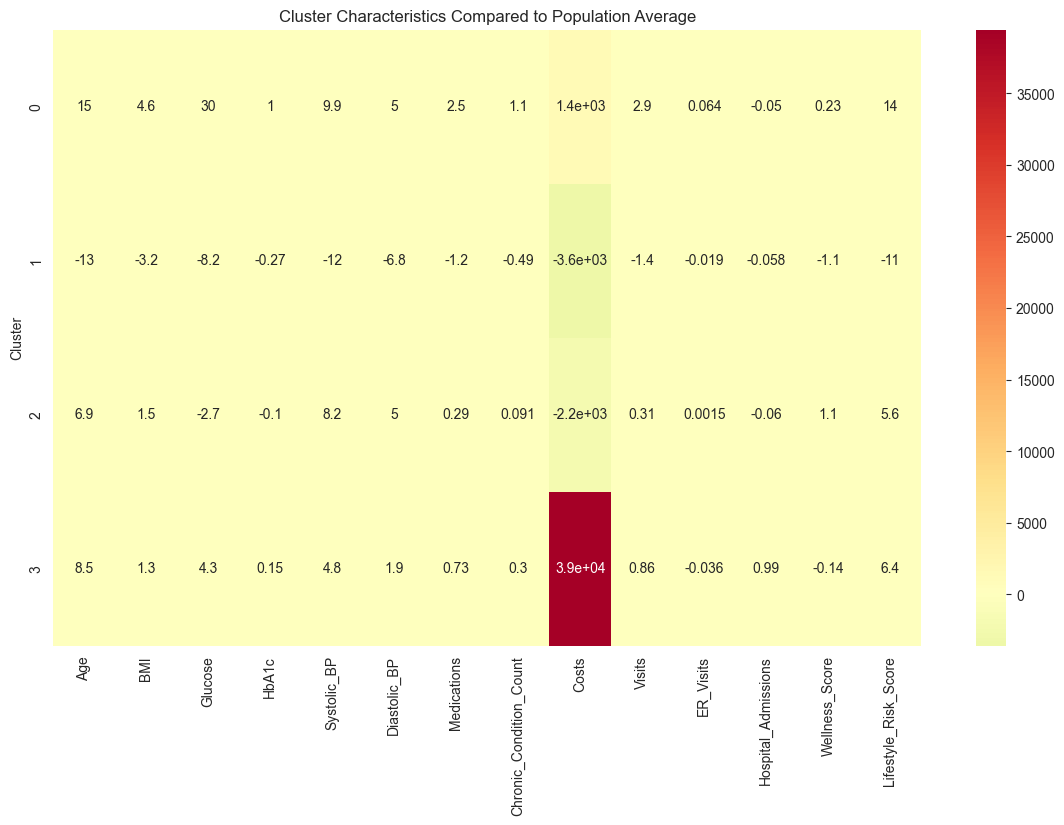

In [315]:
# =====================================================
# Heatmap of Cluster Drivers
# =====================================================

plt.figure(figsize=(14,8))

sns.heatmap(

    cluster_driver_analysis,

    annot=True,

    cmap="RdYlGn_r",

    center=0

)

plt.title(
    "Cluster Characteristics Compared to Population Average"
)

plt.show()

In [316]:
cluster_driver_analysis.to_csv(
    "cluster_driver_analysis.csv"
)

cluster_driver_summary.to_csv(
    "cluster_driver_summary.csv",
    index=False
)

# saving NLP

In [317]:
nlp_df["Topic_ID"] = (
    lda.transform(
        tfidf.transform(nlp_df["Clean_Feedback"])
    ).argmax(axis=1)
    + 1
)

nlp_df["Topic_Name"] = nlp_df["Topic_ID"].map(topic_mapping)

powerbi_feedback = nlp_df[[
    "Feedback",
    "Corrected_Sentiment",
    "Ratings",
    "Topic_Name"
]].copy()

powerbi_feedback.to_csv(
    "powerbi_feedback.csv",
    index=False
)

In [318]:
topic_summary = pd.DataFrame({

    "Topic_Name":[

        "Billing & Administration",

        "Service Quality & Doctors",

        "Emergency Services & Wait Time",

        "Clinical Care & Surgery",

        "Appointment Scheduling & Access"

    ],

    "Description":[

        "Billing concerns, charges and administration",

        "Doctor experience and service quality",

        "Emergency department and waiting time",

        "Clinical care and surgery experience",

        "Appointments and access to healthcare"

    ]

})

topic_summary.to_csv(
    "topic_summary.csv",
    index=False
)

In [319]:
keyword_summary = tfidf_df.head(20)

keyword_summary.to_csv(
    "keyword_summary.csv",
    index=False
)

In [320]:
# positive_drivers

positive_words.to_csv(
    "positive_drivers.csv",
    index=False
)

In [321]:
# negative_drivers
negative_words.to_csv(
    "negative_drivers.csv",
    index=False
)

In [322]:
# NLP model Comparision

nlp_model_comparison.to_csv(
    "nlp_model_comparison.csv",
    index=False
)

In [323]:
campaign_mapping = pd.DataFrame({

    "Campaign": [

        "Diabetes Prevention Program",

        "Active Lifestyle Initiative",

        "Healthy Aging Program",

        "Hypertension Awareness Program",

        "Care Management Program",

        "General Wellness Program"

    ],

    "Target_Group": [

        "Elevated Glucose",

        "Lifestyle Risk",

        "Age 60+",

        "Elevated BP",

        "Multiple Chronic Conditions",

        "Low Risk Members"

    ],

    "Goal": [

        "Reduce diabetes risk",

        "Increase physical activity",

        "Support healthy aging",

        "Improve BP control",

        "Care coordination",

        "Maintain wellness"

    ]

})

campaign_mapping.to_csv(
    "campaign_mapping.csv",
    index=False
)

In [324]:
from sklearn.metrics import classification_report

classification_report_df = pd.DataFrame(
    classification_report(
        y_test,
        pred_lr,
        target_names=sentiment_encoder.classes_,
        output_dict=True
    )
).transpose()

classification_report_df.to_csv(
    "nlp_classification_report.csv",
    index=True
)

print("nlp_classification_report.csv saved successfully.")

print(
    "nlp_classification_report.csv saved successfully."
)

nlp_classification_report.csv saved successfully.
nlp_classification_report.csv saved successfully.


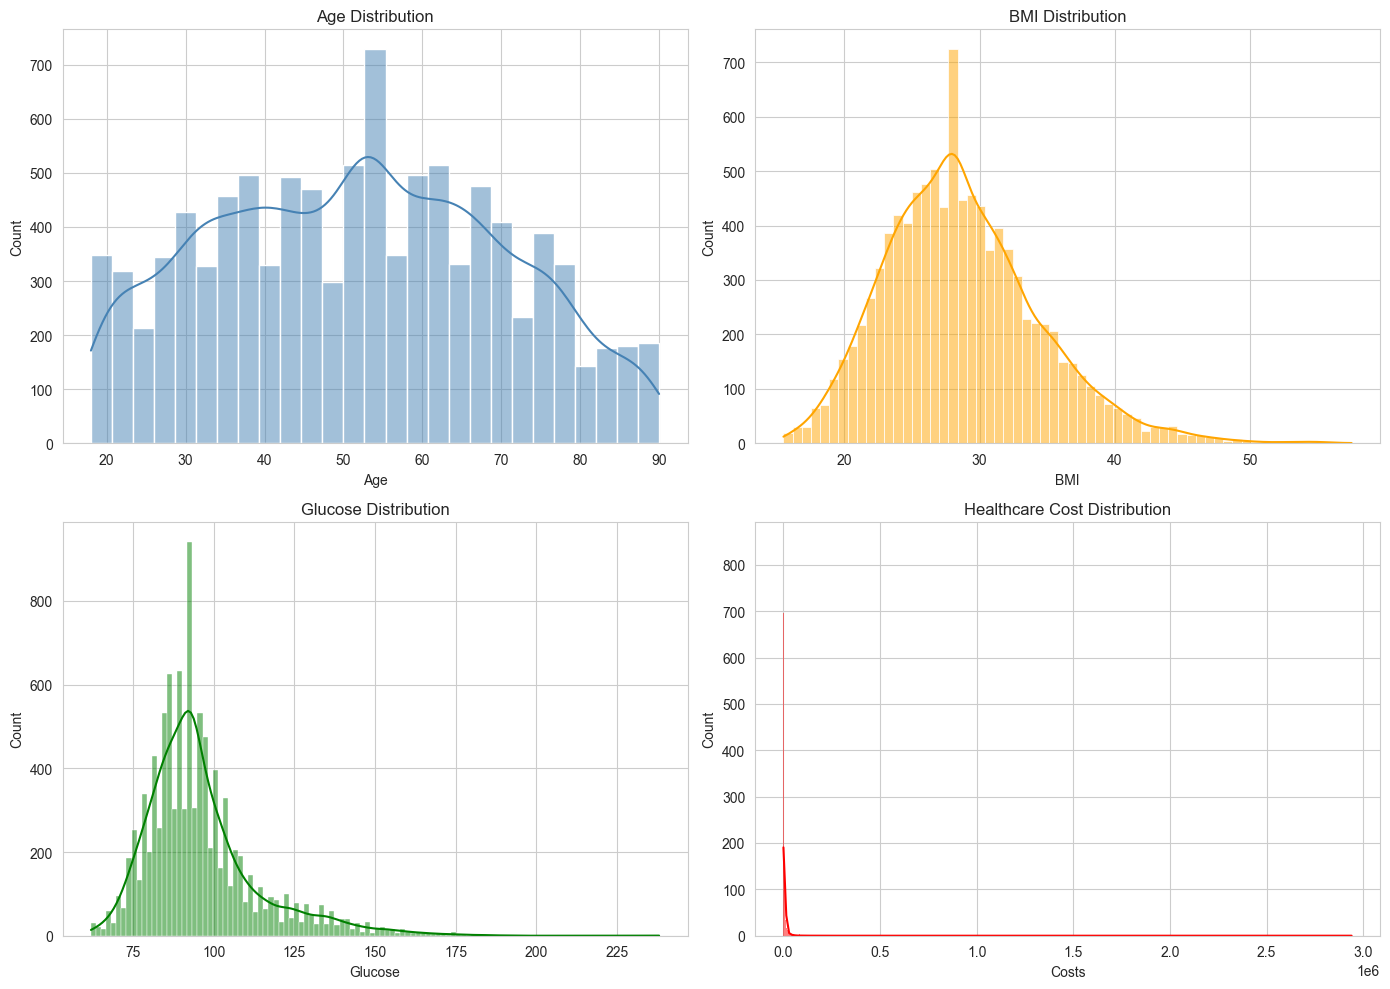

In [325]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14,10)
)

sns.histplot(
    member_level_df["Age"],
    kde=True,
    ax=axes[0,0],
    color="steelblue"
)

axes[0,0].set_title(
    "Age Distribution"
)

sns.histplot(
    member_level_df["BMI"],
    kde=True,
    ax=axes[0,1],
    color="orange"
)

axes[0,1].set_title(
    "BMI Distribution"
)

sns.histplot(
    member_level_df["Glucose"],
    kde=True,
    ax=axes[1,0],
    color="green"
)

axes[1,0].set_title(
    "Glucose Distribution"
)

sns.histplot(
    member_level_df["Costs"],
    kde=True,
    ax=axes[1,1],
    color="red"
)

axes[1,1].set_title(
    "Healthcare Cost Distribution"
)

plt.tight_layout()

plt.savefig(
    "eda_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

C:\Users\P295295\AppData\Local\Temp\ipykernel_13264\39502729.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


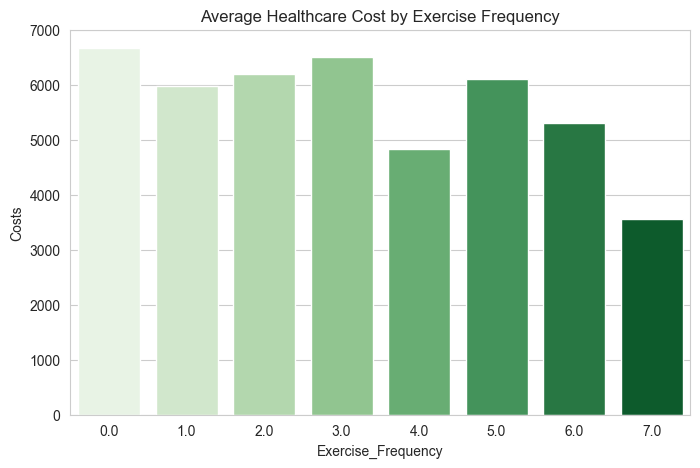

In [326]:
exercise_cost = (

    member_level_df

    .groupby("Exercise_Frequency")["Costs"]

    .mean()

    .reset_index()

)

plt.figure(figsize=(8,5))

sns.barplot(

    data=exercise_cost,

    x="Exercise_Frequency",

    y="Costs",

    palette="Greens"

)

plt.title(
    "Average Healthcare Cost by Exercise Frequency"
)

plt.show()

C:\Users\P295295\AppData\Local\Temp\ipykernel_13264\1662974077.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("BMI_Category")["Glucose"]
C:\Users\P295295\AppData\Local\Temp\ipykernel_13264\1662974077.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


<Axes: xlabel='BMI_Category', ylabel='Glucose'>

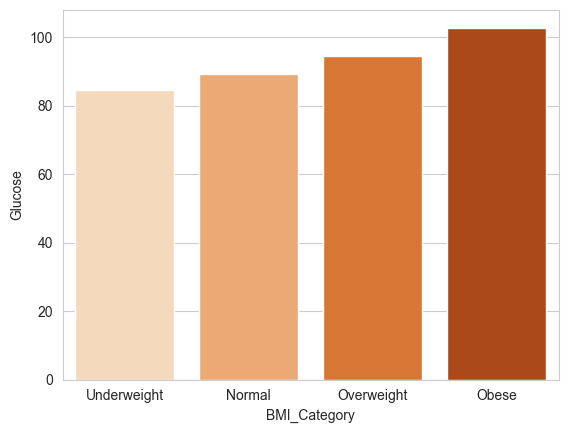

In [327]:
member_level_df["BMI_Category"] = pd.cut(

    member_level_df["BMI"],

    bins=[0,18.5,25,30,100],

    labels=[

        "Underweight",

        "Normal",

        "Overweight",

        "Obese"

    ]

)

bmi_glucose = (

    member_level_df

    .groupby("BMI_Category")["Glucose"]

    .mean()

    .reset_index()

)

sns.barplot(

    data=bmi_glucose,

    x="BMI_Category",

    y="Glucose",

    palette="Oranges"

)

<Axes: xlabel='Smoking_Status', ylabel='Costs'>

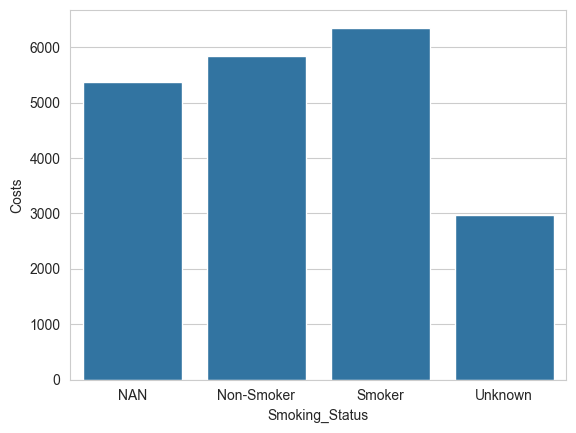

In [328]:
smoking_cost = (

    member_level_df

    .groupby("Smoking_Status")["Costs"]

    .mean()

    .reset_index()

)

sns.barplot(

    data=smoking_cost,

    x="Smoking_Status",

    y="Costs"

)


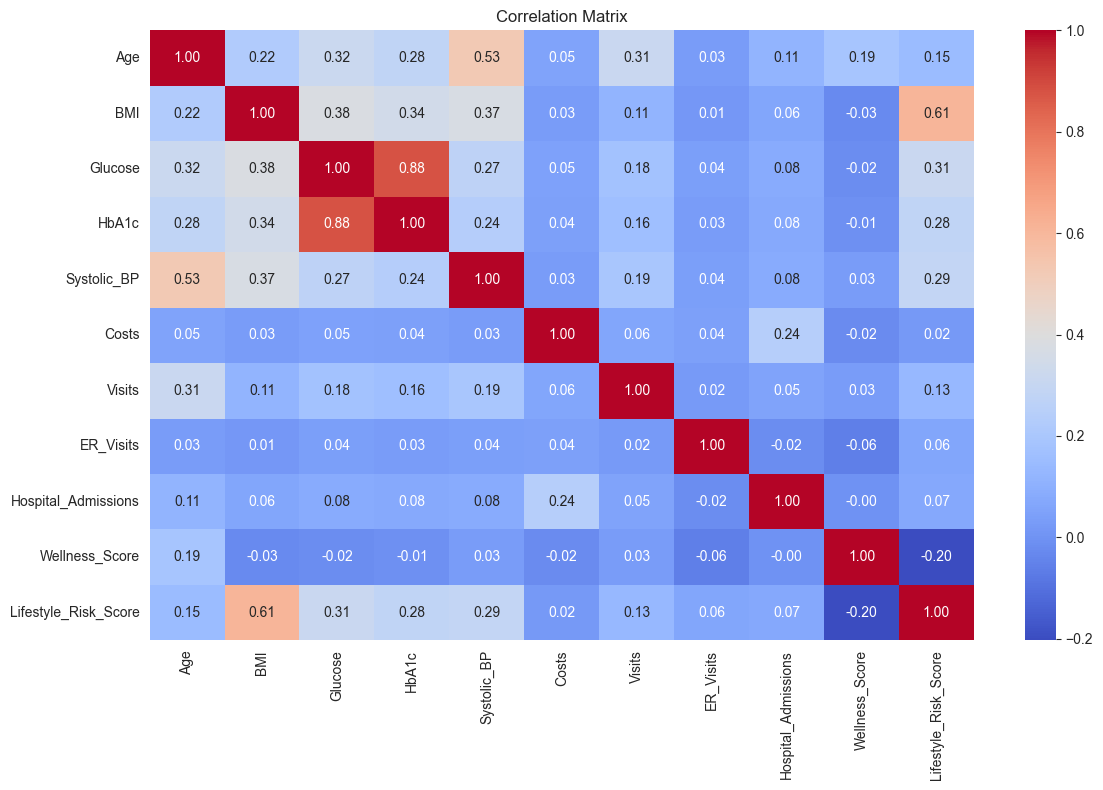

In [329]:
corr_cols = [

    "Age",

    "BMI",

    "Glucose",

    "HbA1c",

    "Systolic_BP",

    "Costs",

    "Visits",

    "ER_Visits",

    "Hospital_Admissions",

    "Wellness_Score",

    "Lifestyle_Risk_Score"

]

corr_matrix = member_level_df[
    corr_cols
].corr()

plt.figure(figsize=(12,8))

sns.heatmap(

    corr_matrix,

    annot=True,

    cmap="coolwarm",

    fmt=".2f"

)

plt.title(
    "Correlation Matrix"
)

plt.tight_layout()

plt.savefig(
    "correlation_heatmap.png",
    dpi=300
)

plt.show()

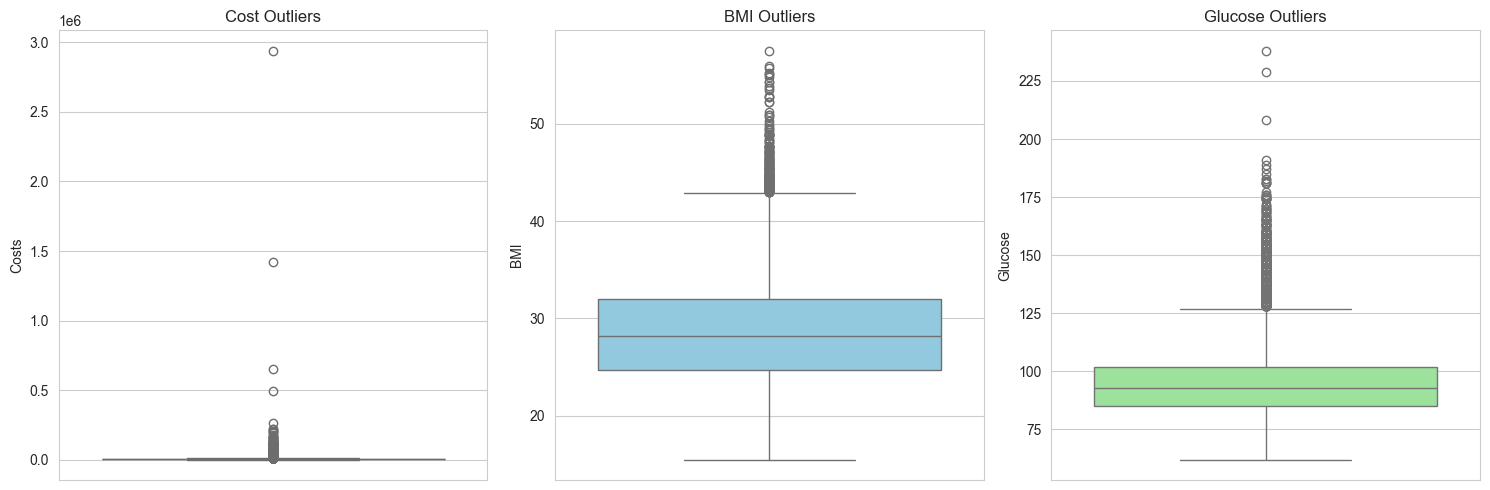

In [330]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15,5)
)

sns.boxplot(

    y=member_level_df["Costs"],

    ax=axes[0],

    color="salmon"

)

axes[0].set_title(
    "Cost Outliers"
)

sns.boxplot(

    y=member_level_df["BMI"],

    ax=axes[1],

    color="skyblue"

)

axes[1].set_title(
    "BMI Outliers"
)

sns.boxplot(

    y=member_level_df["Glucose"],

    ax=axes[2],

    color="lightgreen"

)

axes[2].set_title(
    "Glucose Outliers"
)

plt.tight_layout()

plt.savefig(
    "outlier_analysis.png",
    dpi=300
)

plt.show()

In [331]:
cost_by_cluster = (

    member_level_df

    .groupby("Cluster_Name")["Costs"]

    .mean()

    .reset_index()

)

<Axes: xlabel='Cluster_Name', ylabel='Costs'>

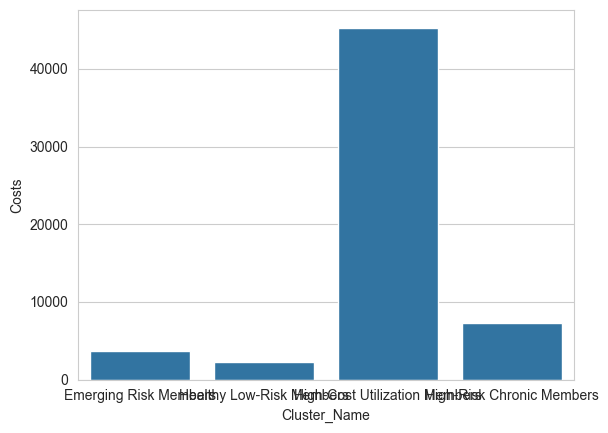

In [332]:
sns.barplot(

    data=cost_by_cluster,

    x="Cluster_Name",

    y="Costs"

)

In [333]:
member_level_df["Cluster"].value_counts()

Cluster
1    4091
2    3940
0    1404
3     547
Name: count, dtype: int64

In [334]:
print(

    member_level_df[

        ["Cluster","Cluster_Name"]

    ]

    .drop_duplicates()

    .sort_values("Cluster")

)

    Cluster                   Cluster_Name
6         0      High-Risk Chronic Members
0         1       Healthy Low-Risk Members
2         2          Emerging Risk Members
37        3  High-Cost Utilization Members


In [335]:
member_level_df["Cluster_Name"].isna().mean()

0.0